<a href="https://colab.research.google.com/github/Epot12/QML_project/blob/master/QML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#QML PROJECT   Emiliano Lorenzo Matricola: 7177126

Questo notebook è basato sull'articolo "Quantum integration in swin
transformer mitigates overfitting in
breast cancer screening" di Zongyu Xie, Xiaoguang Yang, Shuni Zhang, Jingru Yang, Yun Zhu, Aoqi Zhang, Haitao Sun, Qun Dai, Lei Li, Hongde Liu, Wenlong Ming & Menghan Dou. Né il codice né i dataset usati sono resi disponibili insieme all'articolo, pertanto la seguente implementazione è stata prodotta in modo originale dal sottoscritto seguendo, per la prima parte del notebook, le indicazioni tecniche dettagliate fornite nell'articolo.
Il notebook è stato eseguito su Google Colab, facendo ricorso alla GPU A100 con RAM elevata (disponibile con il piano PRO) per ottimizzare i tempi di calcolo. Per quanto riguarda il Real Quantum Computer, è stato fatto uso della macchina IBM Torino disponibile su IBM Quantum Platform con Open Plan. Si segnala che l'esecuzione del circuito quantistico testato ha consumato buona parte dei 10 minuti disponibili con l'Open Plan.
Altro dettaglio importante riguarda il fatto che i modelli prodotti da questo notebook sono stati salvati nel drive personale dell'autore e il codice li carica da tale drive. E' quindi necessario sostituire le directories con quelle del proprio Google Drive.

In [2]:
import os
import shutil
from google.colab import drive
import torch
import torch.nn as nn
import pandas as pd
import glob
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.models import swin_b, Swin_B_Weights

drive.mount('/content/drive')
drive_path_models = '/content/drive/MyDrive/QML/models'
local_path_models = '/content/models'

Mounted at /content/drive


La seguente cella implementa la gestione locale dei seed per i random generators, allo scopo di non dover usare variabili globali.

In [3]:
import torch
import numpy as np
import random

class LocalSeed:
    """Context manager per applicare un seed temporaneo senza alterare il resto del notebook."""
    def __init__(self, seed=42):
        self.seed = seed
        # Scatta la fotografia dello stato attuale
        self.saved_random_state = random.getstate()
        self.saved_np_state = np.random.get_state()
        self.saved_torch_state = torch.get_rng_state()
        if torch.cuda.is_available():
            self.saved_cuda_state = torch.cuda.get_rng_state_all()

    def __enter__(self):
        # Imposta il seed fisso per questo blocco
        random.seed(self.seed)
        np.random.seed(self.seed)
        torch.manual_seed(self.seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(self.seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        # Ripristina la fotografia quando il blocco finisce
        random.setstate(self.saved_random_state)
        np.random.set_state(self.saved_np_state)
        torch.set_rng_state(self.saved_torch_state)
        if torch.cuda.is_available():
            torch.cuda.set_rng_state_all(self.saved_cuda_state)

            torch.backends.cudnn.deterministic = False
            torch.backends.cudnn.benchmark = True

##Exploratory Data Analysis INbreast

Questa sezione del notebook si concentra sull'analisi del dataset INBreast (dataset medico di mammografie digitali ai raggi X), usato nel paper di riferimento come dataset di external validation. Data l'impossibilità di accedere al dataset primario usato dagli autori, qui è stata valutata l'opzione di usare questo dataset per il fine tuning dei modelli.
INbreast non si è rivelato però l'alternativa migliore, a causa di difficoltà nel preprocessing dei dati. Nello specifico, l'individuazione delle regioni tumorali tramite le coordinate ROI dà luogo a crop errati o poco informativi per il modello, a causa del formato complesso dei dati delle coordinate stesse, di cui è difficile fare il parsing.

In [ ]:
!pip install pydicom

In [ ]:
import pydicom

zip_path = '/content/drive/MyDrive/QML/INbreast/INbreast.zip'

# estrazione zip nella memoria temporanea di Colab, NON su Drive
# Questo percorso è veloce e si cancella alla chiusura di Colab
extract_path = '/content/data/INbreast_extracted'

print(f"File ZIP sorgente: {zip_path}")
print(f"Cartella di destinazione: {extract_path}")

# Estrazione (Unzip)
if not os.path.exists(extract_path):
    print("Estrazione in corso...")
    # Creo la cartella
    os.makedirs(extract_path, exist_ok=True)

    # Estraggo lo zip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Estrazione completata!")
else:
    print("Dataset già estratto, procedo.")

# Ora cerco i DICOM nella cartella ESTRATTA (non nello zip)
dataset_root = extract_path  # punta alla cartella aperta!

print(f"Analisi del percorso: {dataset_root}")

dicom_files = []
for root, dirs, files in os.walk(dataset_root):
    for file in files:
        # AGGIUNTO: .roi e .m alla lista delle esclusioni
        if not file.startswith('.') and not file.endswith(('.xls', '.xlsx', '.csv', '.xml', '.txt', '.zip', '.roi', '.m')):
             dicom_files.append(os.path.join(root, file))

print(f"Trovati {len(dicom_files)} potenziali file DICOM.")

# Estrazione Metadati
data_list = []
print("Lettura metadati DICOM in corso...")

for file_path in dicom_files:
    try:
        ds = pydicom.dcmread(file_path, stop_before_pixels=True)

        # Recupera il valore grezzo dal DICOM
        pid_dicom = ds.get('PatientID', '')

        # Logica di correzione: Se è "Unknown", vuoto o None, usa il nome del file
        filename = os.path.basename(file_path)
        if str(pid_dicom).strip() in ['Unknown', '', 'None']:
            # Pulisce il nome file da estensioni o caratteri extra
            clean_pid = filename.split('_')[0].replace('.dcm', '')
            final_patient_id = clean_pid
        else:
            final_patient_id = pid_dicom

        data_list.append({
            'file_path': file_path,
            'PatientID': final_patient_id,  # Usa il valore corretto calcolato sopra
            'Laterality': ds.get('ImageLaterality', 'Unknown'),
            'ViewPosition': ds.get('ViewPosition', 'Unknown'),
            'Rows': ds.get('Rows', 0),
            'Columns': ds.get('Columns', 0)
        })
    except Exception as e:
        print(f"Errore su {file_path}: {e}")
        continue

df_images = pd.DataFrame(data_list)
print(f"Fatto! Dimensioni dataset: {df_images.shape}")
display(df_images.head())

File ZIP sorgente: /content/drive/MyDrive/QML/INbreast/INbreast.zip
Cartella di destinazione: /content/data/INbreast_extracted
Dataset già estratto, procedo.
Analisi del percorso: /content/data/INbreast_extracted
🎉 Trovati 411 potenziali file DICOM.
Lettura metadati DICOM in corso...
Errore su /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/inbreast.pdf: File is missing DICOM File Meta Information header or the 'DICM' prefix is missing from the header. Use force=True to force reading.
Fatto! Dimensioni dataset: (410, 6)


,file_path,PatientID,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,Unknown,Unknown,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,Unknown,Unknown,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,Unknown,Unknown,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,Unknown,Unknown,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,Unknown,Unknown,3328,2560


Nel codice seguente si verifica se esistono degli split predefiniti. Inoltre vengono cercate le diagnosi.

In [ ]:
# Cerca il file Excel con le diagnosi (BI-RADS)
xls_files = glob.glob(os.path.join(dataset_root, '**/*.xls*'), recursive=True)
csv_files = glob.glob(os.path.join(dataset_root, '**/*.csv'), recursive=True)

# Uniamo le liste
candidates = xls_files + csv_files

# FILTRO DI SICUREZZA
# Ignoro file che iniziano con '._' (Mac) o '~$' (File aperti di Windows)
metadata_files = [f for f in candidates if not os.path.basename(f).startswith(('._', '~$'))]

print("\n--- ANALISI FEATURES E LABELS ---")
if metadata_files:
    # Prendiamo il primo file valido trovato
    meta_path = metadata_files[0]
    print(f"Trovato file di metadati/label: {meta_path}")

    # Carica a seconda del formato
    try:
        if meta_path.endswith('.csv'):
            # Proviamo con ; che è standard INbreast, se fallisce pandas avvisa
            df_labels = pd.read_csv(meta_path, sep=';')
            if df_labels.shape[1] < 2: # Se ha letto tutto in una colonna sola, riprova con la virgola
                print("Separatore ';' non valido, riprovo con ','")
                df_labels = pd.read_csv(meta_path, sep=',')
        else:
            df_labels = pd.read_excel(meta_path)

        print("File caricato con successo!")
        print("Prime righe del file Labels:")
        display(df_labels.head())
        print("\n Colonne disponibili (Features):")
        print(df_labels.columns.tolist())

    except Exception as e:
        print(f"Errore nella lettura del file Excel: {e}")

else:
    print(" ATTENZIONE: Nessun file Excel/CSV valido trovato.")
    print("Controlla se il file 'INbreast.xls' è presente nello zip.")





--- ANALISI FEATURES E LABELS ---
📄 Trovato file di metadati/label: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/INbreast.xls
✅ File caricato con successo!
Prime righe del file Labels:


,Patient ID,Patient age,Laterality,View,Acquisition date,File Name,ACR,Bi-Rads,Mass,Micros,Distortion,Asymmetry,Findings Notes (in Portuguese),Other Notes,Lesion Annotation Status,Pectoral Muscle Annotation,Other Annotations
0,removed,removed,R,CC,201001.0,22678622.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
1,removed,removed,L,CC,201001.0,22678646.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
2,removed,removed,R,MLO,201001.0,22678670.0,4,1,NaN,NaN,NaN,NaN,normal,NaN,No annotation (Normal),NaN,NaN
3,removed,removed,L,MLO,201001.0,22678694.0,4,3,X,NaN,NaN,NaN,nódulo,NaN,NaN,NaN,NaN
4,removed,removed,R,CC,201001.0,22614074.0,2,5,X,X,NaN,NaN,nódulo QSE + micros,NaN,NaN,NaN,NaN



📊 Colonne disponibili (Features):
['Patient ID', 'Patient age', 'Laterality', 'View', 'Acquisition date', 'File Name', 'ACR', 'Bi-Rads', 'Mass ', 'Micros', 'Distortion', 'Asymmetry', 'Findings Notes (in Portuguese)', 'Other Notes', 'Lesion Annotation Status', 'Pectoral Muscle Annotation', 'Other Annotations']


In [ ]:
# MERGE (UNIONE) DELLE TABELLE

# Pulizia della chiave nel file Excel (df_labels)
# Converto la colonna 'File Name' in stringa e tolgo il ".0" finale se c'è
# (perché nel DICOM abbiamo "22614074", qui "22614074.0")
df_labels['File Name'] = df_labels['File Name'].astype(str).str.replace('.0', '', regex=False)

# Pulizia della chiave nel DataFrame Immagini (df_images)

df_images['PatientID'] = df_images['PatientID'].astype(str).str.strip()

# Eseguo il Merge
# Uniamo "Left" (teniamo tutte le immagini) con "Right" (l'Excel)
# Chiave Immagini: 'PatientID' Chiave Excel: 'File Name'
df_final = pd.merge(df_images, df_labels, left_on='PatientID', right_on='File Name', how='left')

# Riempio i campi "Unknown" usando i dati dell'Excel
# Se Laterality era Unknown, prende quella dell'Excel
df_final['Laterality'] = df_final['Laterality_x'].where(df_final['Laterality_x'] != 'Unknown', df_final['Laterality_y'])
df_final['ViewPosition'] = df_final['ViewPosition'].where(df_final['ViewPosition'] != 'Unknown', df_final['View'])

# Pulizia finale colonne doppie
columns_to_keep = ['file_path', 'PatientID', 'Bi-Rads', 'Laterality', 'ViewPosition', 'Rows', 'Columns']
df_final = df_final[columns_to_keep]

print("Merge completato!")
print(f"Dimensioni finali: {df_final.shape}")
print("Esempio dati finali:")
display(df_final.head())

# Controllo quanti hanno il Bi-Rads (se qualcuno è NaN c'è stato un problema di match)
missing = df_final['Bi-Rads'].isna().sum()
print(f"\n Immagini senza etichetta Bi-Rads trovata: {missing}")

✅ Merge completato!
Dimensioni finali: (410, 7)
Esempio dati finali:


,file_path,PatientID,Bi-Rads,Laterality,ViewPosition,Rows,Columns
0,/content/data/INbreast_extracted/INbreast/INbr...,53582540,1,R,MLO,3328,2560
1,/content/data/INbreast_extracted/INbreast/INbr...,53581941,2,R,CC,3328,2560
2,/content/data/INbreast_extracted/INbreast/INbr...,51049489,2,R,MLO,3328,2560
3,/content/data/INbreast_extracted/INbreast/INbr...,50996999,2,L,CC,4084,3328
4,/content/data/INbreast_extracted/INbreast/INbr...,53581433,1,L,CC,3328,2560



⚠️ Immagini senza etichetta Bi-Rads trovata: 0


✅ Conversione completata!
Distribuzione Classi:
Label
0    310
1    100
Name: count, dtype: int64


/tmp/ipython-input-786881577.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df_final, palette=['green', 'red'])


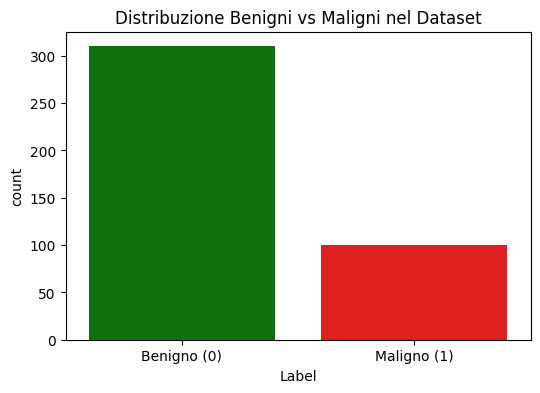

In [ ]:
# CONVERSIONE IN CLASSI BINARIE

def mappa_birads(valore):
    # Convertiamo in intero (gestisce anche stringhe tipo '4a', '4b' se ce ne fossero)
    try:
        v = int(str(valore)[0]) # Prende solo la prima cifra (es '4a' -> 4)
    except:
        return None # Gestione errori

    if v in [1, 2, 3]:
        return 0 # Classe BENIGNO
    elif v in [4, 5, 6]:
        return 1 # Classe MALIGNO
    else:
        return None # BI-RADS 0 o errori

# Applichiamo la funzione
df_final['Label'] = df_final['Bi-Rads'].apply(mappa_birads)

# Rimuoviamo eventuali righe non decodificate
df_final = df_final.dropna(subset=['Label'])
df_final['Label'] = df_final['Label'].astype(int)

# Visualizziamo la distribuzione
print("Conversione completata!")
print("Distribuzione Classi:")
print(df_final['Label'].value_counts())

# Grafico per vedere se è bilanciato
plt.figure(figsize=(6, 4))
sns.countplot(x='Label', data=df_final, palette=['green', 'red'])
plt.xticks([0, 1], ['Benigno (0)', 'Maligno (1)'])
plt.title('Distribuzione Benigni vs Maligni nel Dataset')
plt.show()

In [ ]:
print("Cerco un file .roi di esempio...")

roi_files_found = []
# Cerca ricorsivamente nella cartella estratta
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            roi_files_found.append(os.path.join(root, file))

if roi_files_found:
    sample_roi = roi_files_found[0]
    print(f"Trovato: {sample_roi}")
    print("-" * 30)
    print("CONTENUTO DEL FILE (Primi 500 caratteri):")
    print("-" * 30)

    try:
        # Proviamo a leggerlo come testo
        with open(sample_roi, 'r', encoding='utf-8', errors='replace') as f:
            content = f.read(500)
            print(content)
    except Exception as e:
        print(f"Impossibile leggere il file come testo: {e}")

    print("-" * 30)
else:
    print("Nessun file .roi trovato nelle cartelle estratte!")

🔍 Cerco un file .roi di esempio...
📄 Trovato: /content/data/INbreast_extracted/INbreast/INbreast Release 1.0/PectoralMuscle/Pectoral Muscle ROI/50998440_muscle.roi
------------------------------
CONTENUTO DEL FILE (Primi 500 caratteri):
------------------------------
streamtyped���@���NSMutableArray ��NSArray ��NSObject ��i����ROI���������MyPoint �����NSString��+{2759.05, 6.62378}���������{2779.96, 53.4911}���������{2798.42, 117.778}���������{2810, 177.986}���������{2821.57, 247.457}���������{2835.47, 312.297}���������{2847.05, 384.084}���������{2860.94, 460.502}���������{2874.84, 529.974}���������{2891.05, 617.971}���������{2904.94, 689.758}���������{2921.15, 761.545}���������{2946.62, 861.12}���������{2976.73, 942.17}���������
------------------------------


In [ ]:
import re
import numpy as np
import cv2 # OpenCV per il ridimensionamento
from google.colab.patches import cv2_imshow # Per vedere le immagini su Colab

# PARSER DEL FILE .ROI
def parse_roi_file(roi_path):
    """
    Legge un file .roi di INbreast e restituisce una lista di coordinate (x, y).
    Usa Regex per trovare i pattern {numero, numero}.
    """
    try:
        with open(roi_path, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()

        # Questa regex cerca pattern tipo {1234.56, 789.10}
        # Spiegazione regex: \{ = parentesi graffa aperta, ([0-9.]+) = cattura numero
        points_str = re.findall(r'\{([0-9.]+),\s*([0-9.]+)\}', content)

        points = []
        for p in points_str:
            x, y = float(p[0]), float(p[1])
            points.append([x, y])

        return np.array(points)
    except Exception as e:
        print(f"Errore lettura ROI {roi_path}: {e}")
        return None

# PRENDE IL QUADRATO (Bounding Box)
def get_bounding_box(points, img_shape):
    """
    Dai punti del contorno, calcola il rettangolo (min_x, min_y, max_x, max_y).
    Aggiunge un piccolo margine (padding) per non tagliare il bordo del tumore.
    """
    if points is None or len(points) == 0:
        return None

    # Coordinate minime e massime
    min_x = np.min(points[:, 0])
    max_x = np.max(points[:, 0])
    min_y = np.min(points[:, 1])
    max_y = np.max(points[:, 1])

    # Aggiungo un margine del 10% (Padding)
    width = max_x - min_x
    height = max_y - min_y
    margin = int(max(width, height) * 0.1)

    # Coordinate finali (facendo attenzione a non uscire dall'immagine)
    x1 = int(max(0, min_x - margin))
    y1 = int(max(0, min_y - margin))
    x2 = int(min(img_shape[1], max_x + margin))
    y2 = int(min(img_shape[0], max_y + margin))

    return (x1, y1, x2, y2)

def process_single_case(dicom_path, roi_path_list):
    """
    Scarta muscoli, scarta ROI enormi E scarta ROI nere
    """
    ds = pydicom.dcmread(dicom_path)
    img = ds.pixel_array
    total_area = img.shape[0] * img.shape[1]

    # Normalizza a 0-255
    img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    best_crop = None
    best_roi_name = None
    max_brightness_found = 0 # Cerco la ROI più "bianca" (più densa/significativa)

    for r_path in roi_path_list:
        # Filtro 1: Niente muscoli
        if "muscle" in r_path.lower() or "pectoral" in r_path.lower():
            continue

        points = parse_roi_file(r_path)
        if points is not None and len(points) > 3:
            bbox = get_bounding_box(points, img.shape)
            if bbox is None: continue

            x1, y1, x2, y2 = bbox
            crop_area = (x2 - x1) * (y2 - y1)

            # Filtro 2: Niente contorni enormi
            coverage = crop_area / total_area
            if coverage > 0.40:
                continue

            # FILTRO 3: CONTROLLO LUMINOSITÀ
            # Estraiamo il crop provvisorio
            temp_crop = img_norm[y1:y2, x1:x2]
            if temp_crop.size == 0: continue

            avg_brightness = np.mean(temp_crop)

            # Se l'immagine è troppo scura non va bene
            # Una lesione vera è densa (chiara). Soglia empirica: 30 su 255.
            if avg_brightness < 30:
                continue

            # Se arriva qui, è una ROI valida.
            # Strategia: Prendo quella con la luminosità media più alta (il tumore è bianco)
            # invece che la più piccola. Questo aiuta a centrare la massa.
            if avg_brightness > max_brightness_found:
                max_brightness_found = avg_brightness
                best_crop = temp_crop
                best_roi_name = r_path

    if best_crop is None:
        return None, None

    # Resize finale per Swin Transformer
    img_final = cv2.resize(best_crop, (224, 224), interpolation=cv2.INTER_CUBIC)

    return img_final, best_roi_name

In [ ]:
# TEST VISIVO
print("Test del sistema di ritaglio su un caso Maligno...")

# Trova tutti i file ROI nel sistema
all_rois = []
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            all_rois.append(os.path.join(root, file))

# Prende un caso Maligno (Bi-Rads 4, 5, 6 -> Label 1)
malignant_cases = df_final[df_final['Label'] == 1]

if not malignant_cases.empty:
    # Ne prende uno casuale
    sample = malignant_cases.iloc[0]
    pid = sample['PatientID']
    dcm_path = sample['file_path']

    print(f"Paziente Test: {pid}")

    # Cerca i file ROI che appartengono a questo paziente
    # (Il nome del file ROI di solito contiene l'ID del paziente)
    patient_rois = [r for r in all_rois if str(pid) in r]

    if patient_rois:
        print(f"Trovati {len(patient_rois)} file ROI candidati.")

        # PROVA IL RITAGLIO
        cropped_img, roi_used = process_single_case(dcm_path, patient_rois)

        if cropped_img is not None:
            print(f"Successo! ROI usata: {os.path.basename(roi_used)}")

            plt.figure(figsize=(10, 5))

            # Mostra originale (ridimensionata per display)
            ds = pydicom.dcmread(dcm_path)
            plt.subplot(1, 2, 1)
            plt.imshow(ds.pixel_array, cmap='gray')
            plt.title("Mammografia Intera (4000px)")
            plt.axis('off')

            # Mostra il ritaglio
            plt.subplot(1, 2, 2)
            plt.imshow(cropped_img, cmap='gray')
            plt.title("Ritaglio Lesione (224x224)\nInput per Swin Transformer")
            plt.axis('off')

            plt.show()
        else:
            print("Trovati file ROI ma nessuno era una lesione valida (forse solo muscoli?).")
    else:
        print("Nessun file ROI trovato per questo paziente maligno.")
else:
    print("Nessun caso maligno nel dataframe?!")

🔬 Test del sistema di ritaglio su un caso Maligno...
Paziente Test: 22580038
Trovati 1 file ROI candidati.
❌ Trovati file ROI ma nessuno era una lesione valida (forse solo muscoli?).


🔬 Cerco un caso Maligno con una ROI valida (tumore vero)...

✅ TROVATO! Paziente: 50994354
📄 ROI usata: 50994354.roi


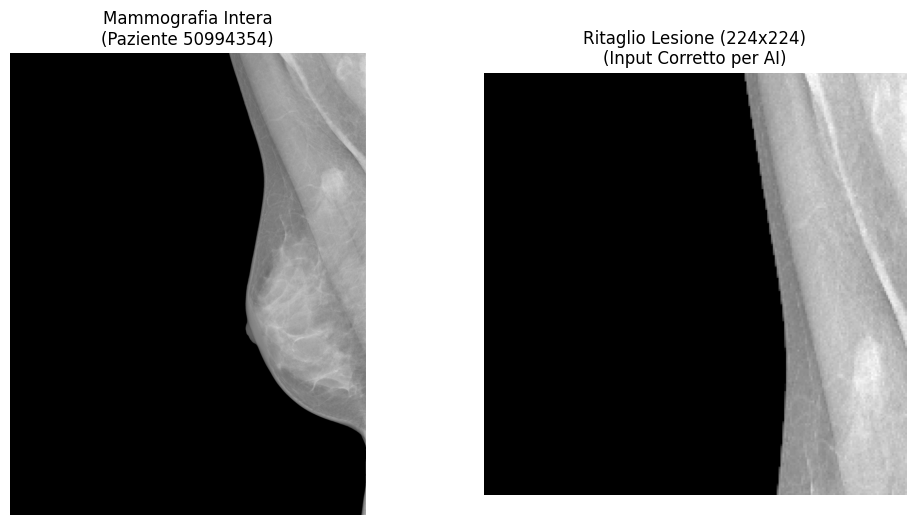

In [ ]:
# TEST VISIVO AVANZATO (Cerca un caso valido)
print("Cerco un caso Maligno con una ROI valida (tumore vero)...")

# Trova tutti i file ROI nel sistema
all_rois = []
for root, dirs, files in os.walk('/content/data/INbreast_extracted'):
    for file in files:
        if file.endswith('.roi'):
            all_rois.append(os.path.join(root, file))

# Prende tutti i casi Maligni
malignant_cases = df_final[df_final['Label'] == 1]

found_valid_case = False

# Ciclo sui primi 50 pazienti maligni finché non ne trovo uno buono
for index, sample in malignant_cases.head(50).iterrows():
    pid = sample['PatientID']
    dcm_path = sample['file_path']

    # Cerca ROI per questo paziente
    patient_rois = [r for r in all_rois if str(pid) in r]

    if not patient_rois:
        continue # Nessuna ROI per questo

    # Prova a processarlo
    cropped_img, roi_used = process_single_case(dcm_path, patient_rois)

    if cropped_img is not None:
        print(f"\n TROVATO! Paziente: {pid}")
        print(f" ROI usata: {os.path.basename(roi_used)}")

        plt.figure(figsize=(12, 6))

        # Originale
        ds = pydicom.dcmread(dcm_path)
        plt.subplot(1, 2, 1)
        plt.imshow(ds.pixel_array, cmap='gray')
        plt.title(f"Mammografia Intera\n(Paziente {pid})")
        plt.axis('off')

        # Ritaglio
        plt.subplot(1, 2, 2)
        plt.imshow(cropped_img, cmap='gray')
        plt.title("Ritaglio Lesione (224x224)\n(Input Corretto per AI)")
        plt.axis('off')

        plt.show()

        found_valid_case = True
        break

if not found_valid_case:
    print("\n Ho controllato 50 pazienti maligni ma nessuno aveva una ROI 'piccola' valida.")
    print("Potrebbe essere necessario alzare la soglia del 40% o controllare i file ROI.")

## Caricamento BreastMNIST e Exploratory Data Analysis

Jiancheng Yang, Rui Shi, Donglai Wei, Zequan Liu, Lin Zhao, Bilian Ke, Hanspeter Pfister, Bingbing Ni. Yang, Jiancheng, et al. "MedMNIST v2-A large-scale lightweight benchmark for 2D and 3D biomedical image classification." Scientific Data, 2023.
                            
  Jiancheng Yang, Rui Shi, Bingbing Ni. "MedMNIST Classification Decathlon: A Lightweight AutoML Benchmark for Medical Image Analysis". IEEE 18th International Symposium on Biomedical Imaging (ISBI), 2021.
  
  Di seguito viene importato il dataset BreastMNIST (ecografie mammarie), parte della raccolta MedMNIST. Questo è il dataset effettivamente usato per il fine tuning dei modelli

In [3]:
!pip install medmnist

import os
import torch
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from torchvision import transforms
import medmnist
from medmnist import BreastMNIST, INFO

# CONFIGURAZIONE SALVATAGGIO
output_dir = '/content/eda_results'
os.makedirs(output_dir, exist_ok=True)

# Impostazioni grafiche per alta qualità
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'serif'
sns.set_style("whitegrid")

print(f"I grafici verranno salvati in: {output_dir}")

# CARICAMENTO DATI
print(f"MedMNIST v{medmnist.__version__} installato correttamente.")

# Info Dataset
data_flag = 'breastmnist'
info = INFO[data_flag]
class_names = info['label'] # {'0': 'malignant', '1': 'normal, benign'}
print(f"Dataset: {info['description']}")
print(f"Class names ufficiali di BreastMNIST: {class_names}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.5 MB/s eta 0:00:00
I grafici verranno salvati in: /content/eda_results
MedMNIST v3.0.2 installato correttamente.
Dataset: The BreastMNIST is based on a dataset of 780 breast ultrasound images. It is categorized into 3 classes: normal, benign, and malignant. As we use low-resolution images, we simplify the task into binary classification by combining normal and benign as positive and classifying them against malignant as negative. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images of 1×500×500 are resized into 1×28×28.
Class names ufficiali di BreastMNIST: {'0': 'malignant', '1': 'normal, benign'}


100%|██████████| 560k/560k [00:00<00:00, 929kB/s] 



--- 1. STRUTTURA DEL DATASET ---
Dimensioni Immagine: torch.Size([1, 28, 28])
Mapping Classi (usato nei grafici): {0: 'Malignant', 1: 'Benign'}
Numero campioni Training: 546


/tmp/ipython-input-2755156716.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Diagnosis', data=df_labels, order=['Malignant', 'Benign'], palette=['#d62728', '#2ca02c'])


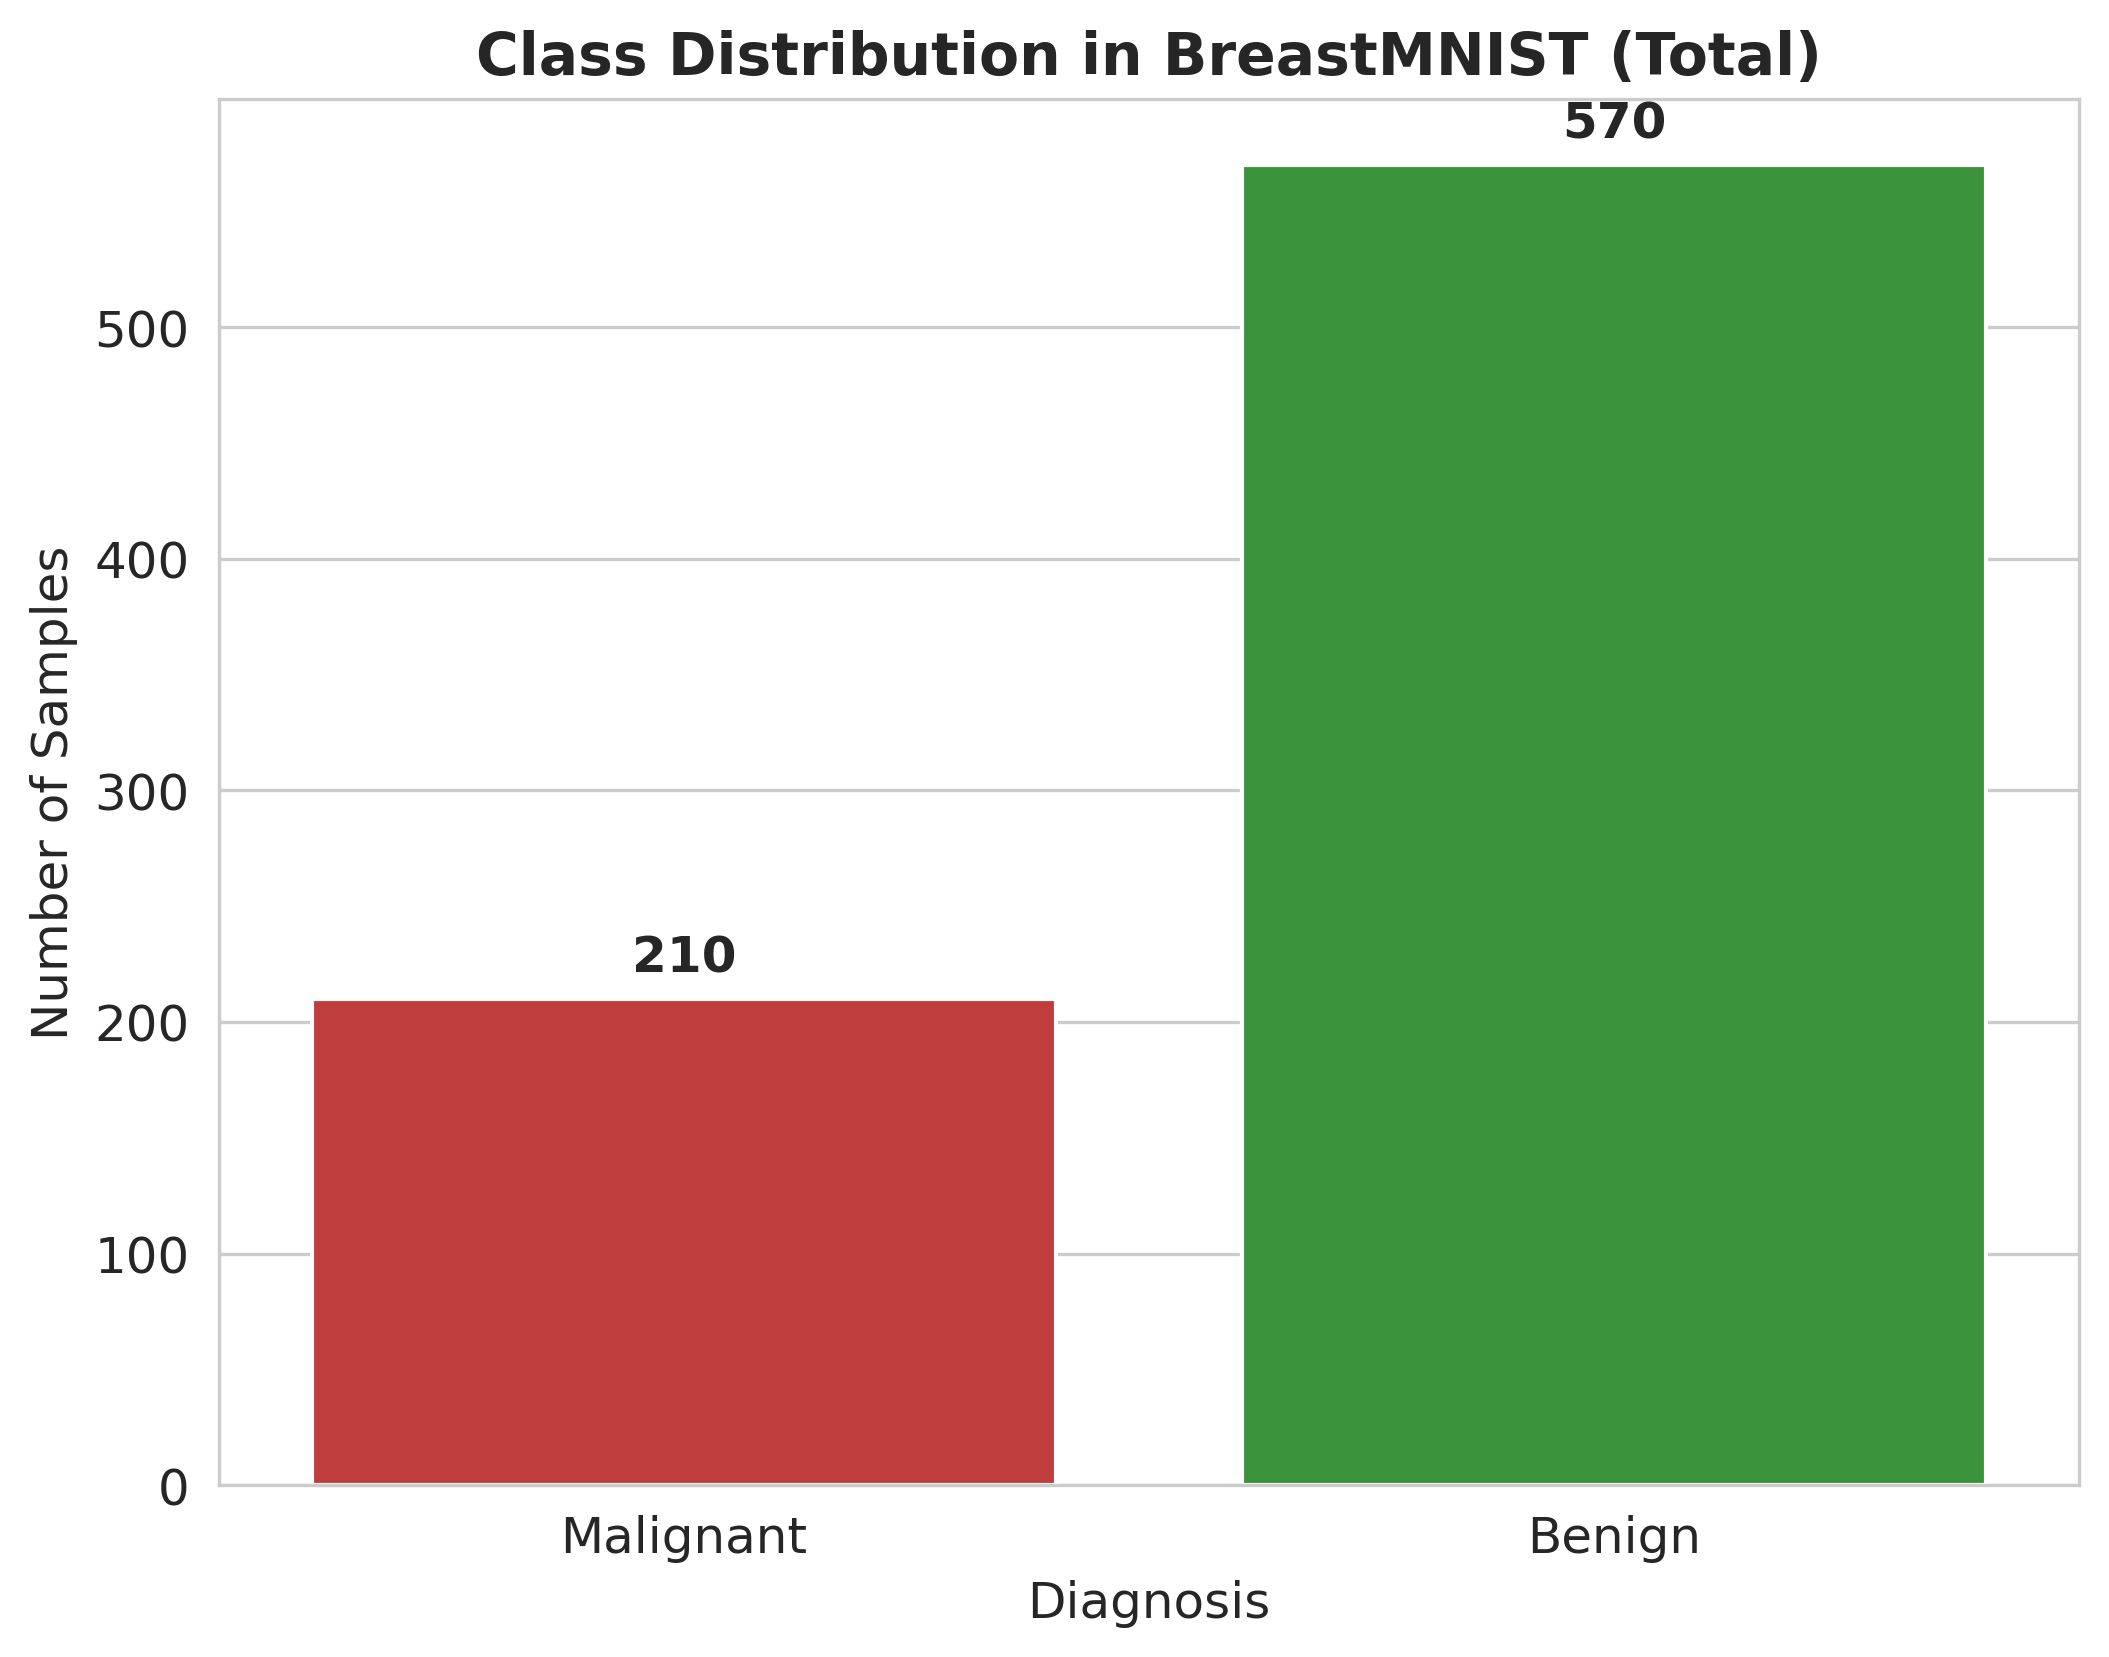

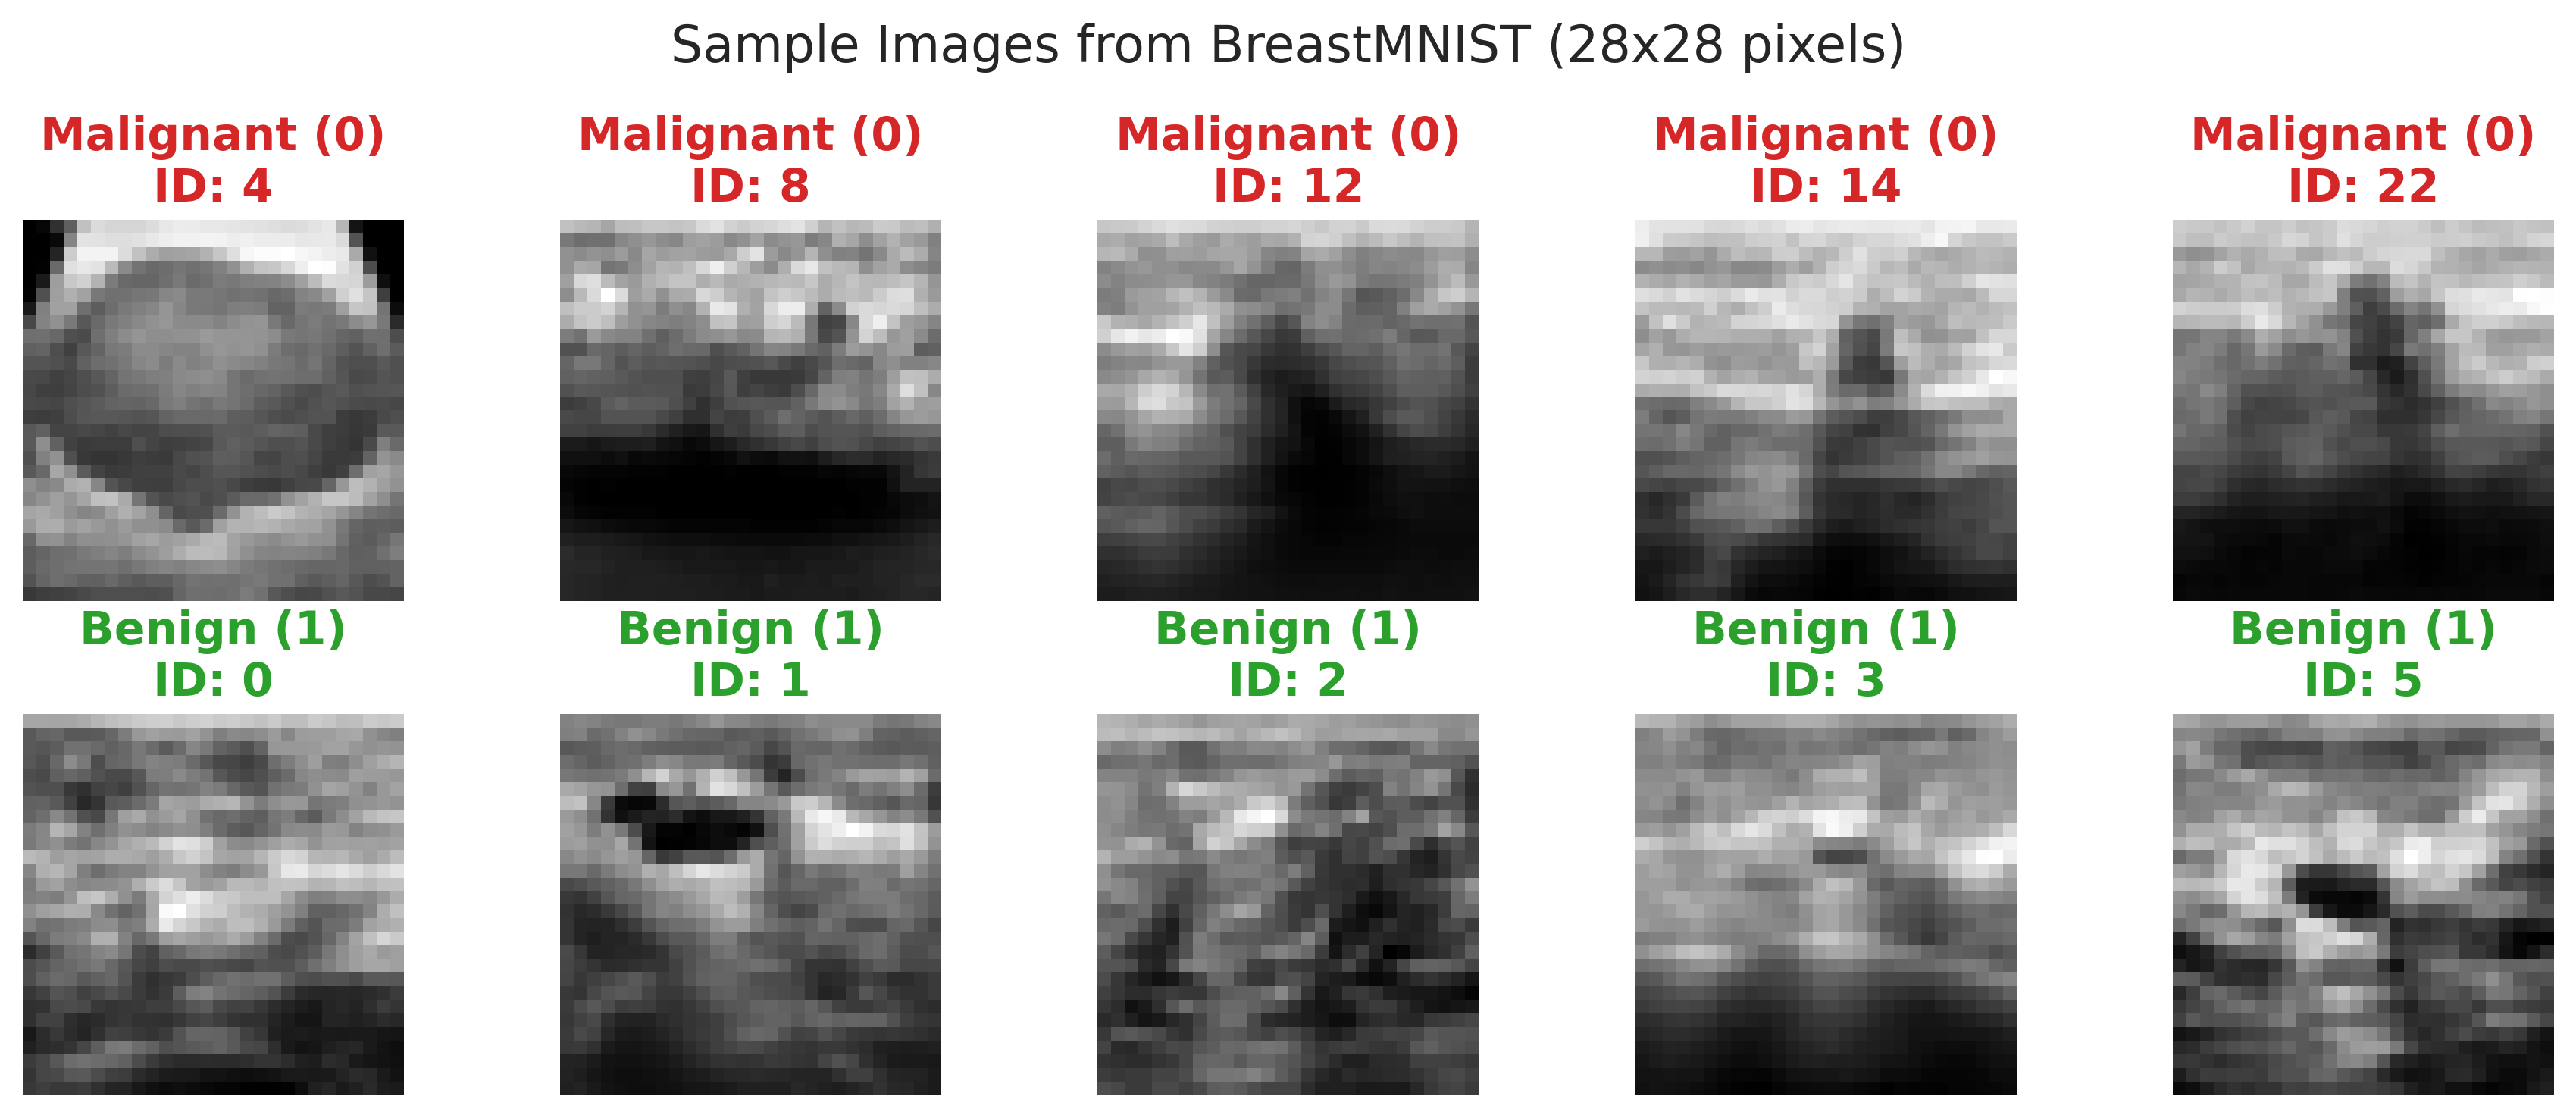

Generazione Istogramma Pixel...


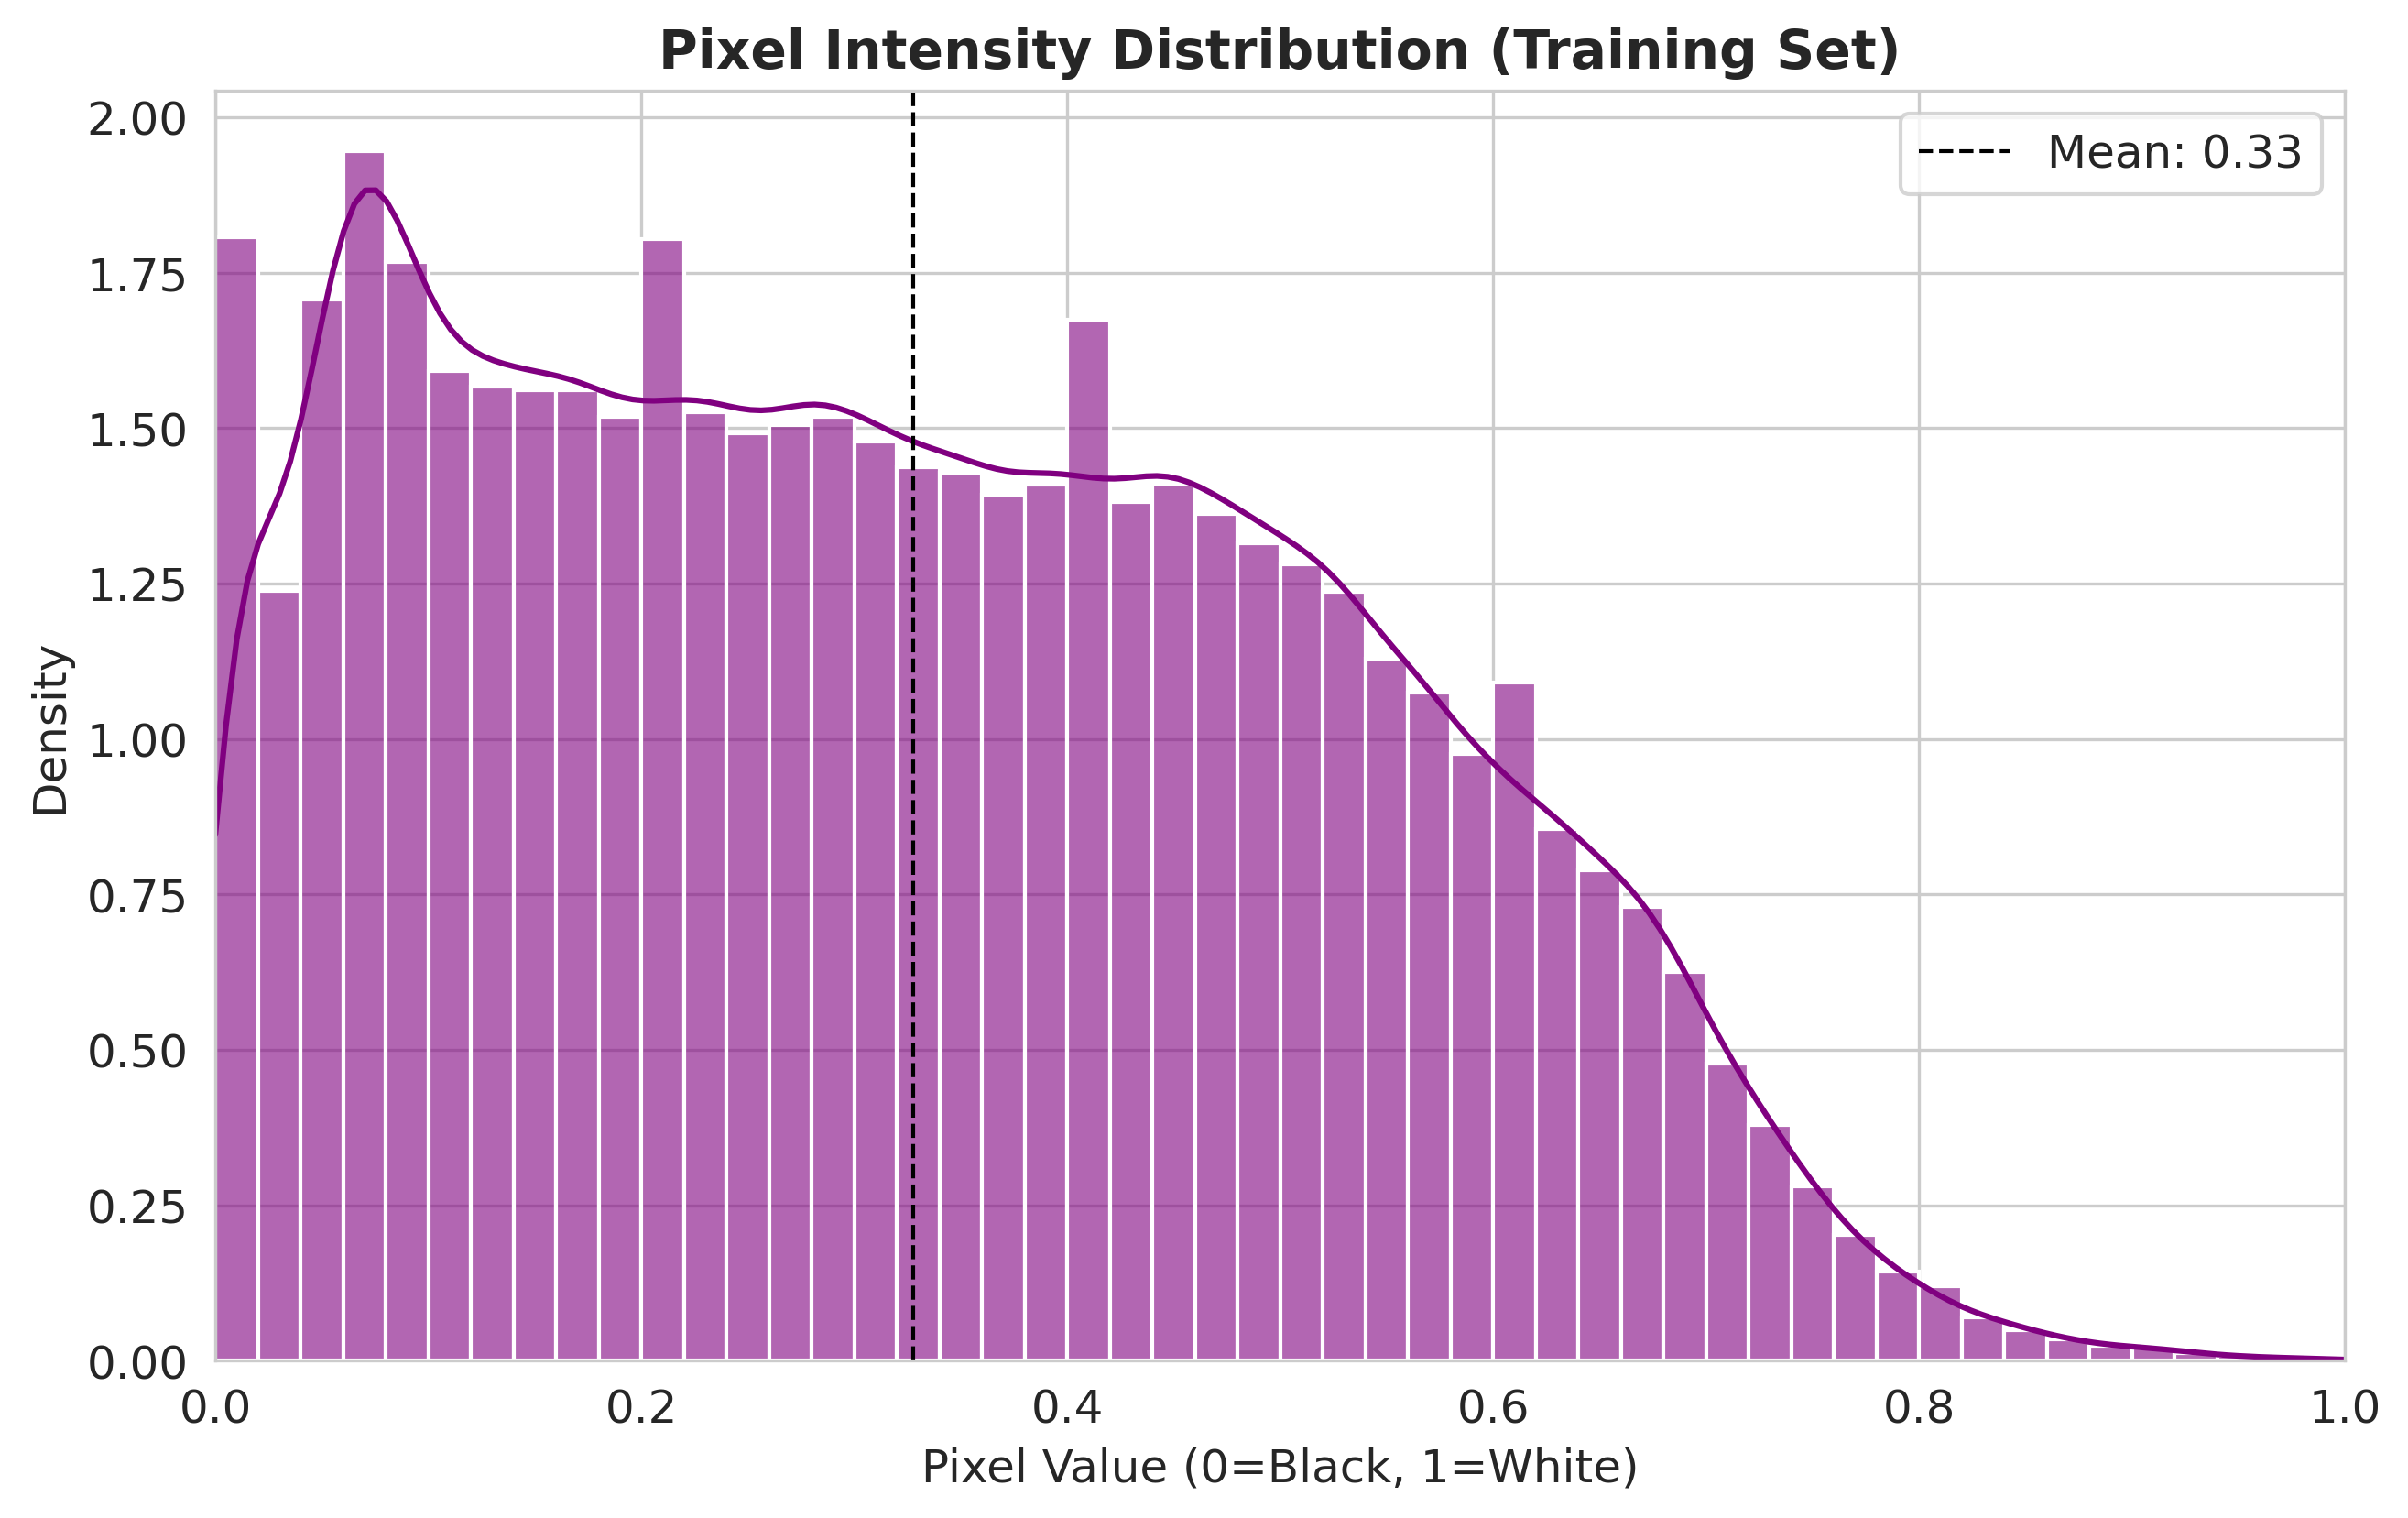

 Generazione Immagine Media...


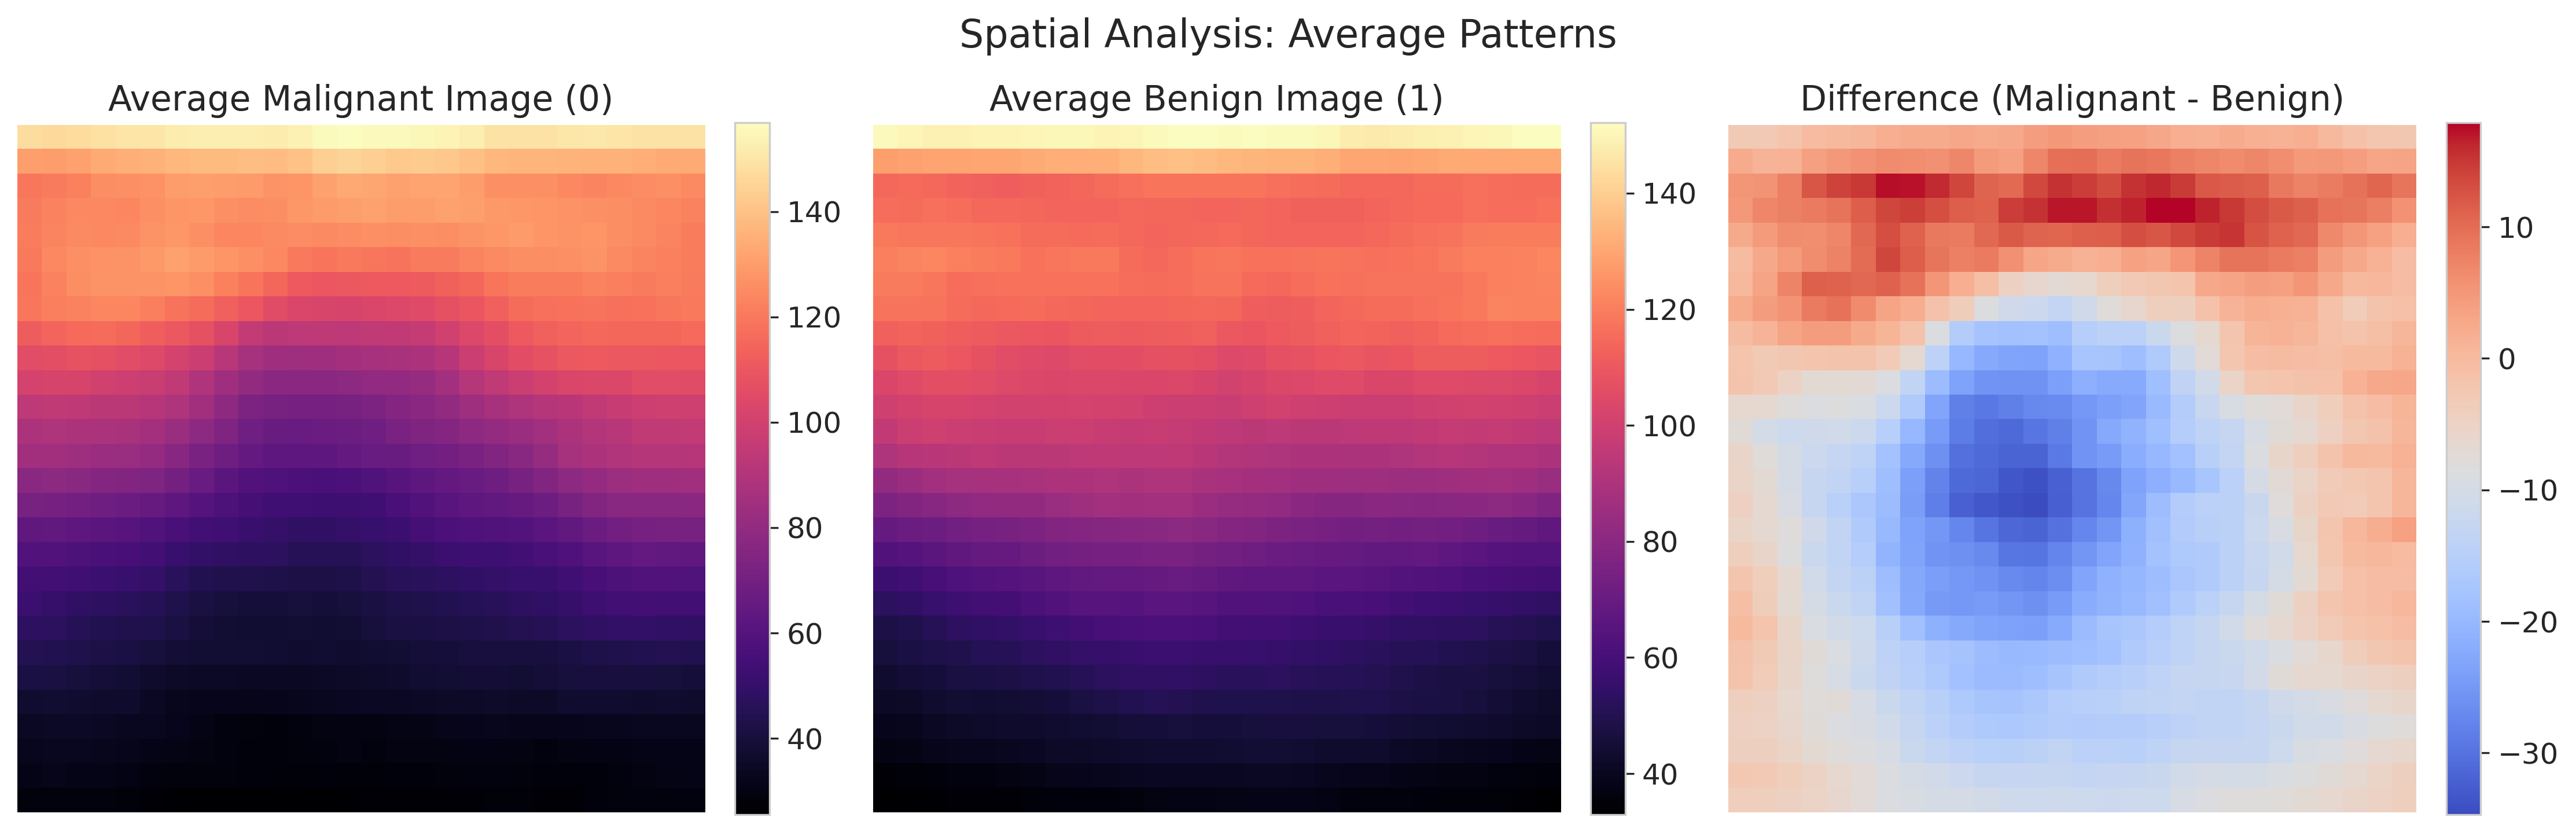


 EDA Completata con successo! I file sono pronti per il download.


In [4]:
# 0 = Maligno (Malignant), 1 = Benigno (Benign/Normal)
class_map = {0: 'Malignant', 1: 'Benign'}

data_transform = transforms.ToTensor()

train_dataset = BreastMNIST(split='train', transform=data_transform, download=True)
val_dataset = BreastMNIST(split='val', transform=data_transform, download=True)
test_dataset = BreastMNIST(split='test', transform=data_transform, download=True)

print("\n--- 1. STRUTTURA DEL DATASET ---")
print(f"Dimensioni Immagine: {train_dataset[0][0].shape}")
print(f"Mapping Classi (usato nei grafici): {class_map}")
print(f"Numero campioni Training: {len(train_dataset)}")

# GRAFICO DISTRIBUZIONE
# Unisco le etichette
all_labels = np.concatenate([
    train_dataset.labels,
    val_dataset.labels,
    test_dataset.labels
])

df_labels = pd.DataFrame(all_labels, columns=['label'])
# Qui uso la class_map definita sopra
df_labels['Diagnosis'] = df_labels['label'].map(class_map)

plt.figure(figsize=(8, 6))
# Countplot: Rosso per Maligno (0), Verde per Benigno (1)
# Attenzione all'ordine: se 'Malignant' appare prima o dopo, i colori devono seguire.
# Uso 'hue' per forzare l'assegnazione corretta dei colori.
ax = sns.countplot(x='Diagnosis', data=df_labels, order=['Malignant', 'Benign'], palette=['#d62728', '#2ca02c'])

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontsize=12, fontweight='bold')

plt.title('Class Distribution in BreastMNIST (Total)', fontsize=14, fontweight='bold')
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)

plt.savefig(f"{output_dir}/01_class_distribution.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/01_class_distribution.png", bbox_inches='tight')
plt.show()

# GRIGLIA CAMPIONI
def get_indices(dataset, class_id, num=5):
    # .flatten() è necessario perché dataset.labels a volte è (N, 1) invece di (N,)
    return np.where(dataset.labels.flatten() == class_id)[0][:num]

idx_malignant = get_indices(train_dataset, 0, 5) # 0 = Maligno
idx_benign = get_indices(train_dataset, 1, 5)    # 1 = Benigno

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Riga 1: Maligni (Classe 0)
for i, idx in enumerate(idx_malignant):
    img = train_dataset.imgs[idx]
    axes[0, i].imshow(img, cmap='gray')
    axes[0, i].set_title(f"Malignant (0)\nID: {idx}", color='#d62728', fontweight='bold')
    axes[0, i].axis('off')

# Riga 2: Benigni (Classe 1)
for i, idx in enumerate(idx_benign):
    img = train_dataset.imgs[idx]
    axes[1, i].imshow(img, cmap='gray')
    axes[1, i].set_title(f"Benign (1)\nID: {idx}", color='#2ca02c', fontweight='bold')
    axes[1, i].axis('off')

plt.suptitle(f"Sample Images from BreastMNIST ({28}x{28} pixels)", fontsize=16)
plt.tight_layout()

plt.savefig(f"{output_dir}/02_sample_grid.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/02_sample_grid.png", bbox_inches='tight')
plt.show()

# ISTOGRAMMA PIXEL
print("Generazione Istogramma Pixel...")
pixel_values = train_dataset.imgs.flatten() / 255.0

plt.figure(figsize=(10, 6))
sns.histplot(pixel_values, bins=50, kde=True, color='purple', stat='density', alpha=0.6)
plt.title('Pixel Intensity Distribution (Training Set)', fontsize=14, fontweight='bold')
plt.xlabel('Pixel Value (0=Black, 1=White)', fontsize=12)
plt.xlim(0, 1)

mean_val = np.mean(pixel_values)
plt.axvline(mean_val, color='k', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
plt.legend()

plt.savefig(f"{output_dir}/03_pixel_distribution.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/03_pixel_distribution.png", bbox_inches='tight')
plt.show()

# IMMAGINE MEDIA
print(" Generazione Immagine Media...")
imgs = train_dataset.imgs
labels = train_dataset.labels.flatten() # Flatten per sicurezza

# 0=Maligno, 1=Benigno
mean_mal = np.mean(imgs[labels == 0], axis=0) # Media dei Maligni
mean_ben = np.mean(imgs[labels == 1], axis=0) # Media dei Benigni

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

im0 = ax[0].imshow(mean_mal, cmap='magma')
ax[0].set_title('Average Malignant Image (0)')
ax[0].axis('off')
plt.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04)

im1 = ax[1].imshow(mean_ben, cmap='magma')
ax[1].set_title('Average Benign Image (1)')
ax[1].axis('off')
plt.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

# Differenza (Maligno - Benigno)
# Se questa immagine ha zone rosse, significa che i tumori sono più luminosi in quelle zone
diff = mean_mal - mean_ben
im2 = ax[2].imshow(diff, cmap='coolwarm')
ax[2].set_title('Difference (Malignant - Benign)')
ax[2].axis('off')
plt.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

plt.suptitle("Spatial Analysis: Average Patterns", fontsize=16)
plt.tight_layout()

plt.savefig(f"{output_dir}/04_average_patterns.pdf", bbox_inches='tight')
plt.savefig(f"{output_dir}/04_average_patterns.png", bbox_inches='tight')
plt.show()

print("\n EDA Completata con successo! I file sono pronti per il download.")

## Swin B Transformer classico

In [4]:
def get_classical_swin_model():
    # Carica i pesi ImageNet
    weights = Swin_B_Weights.IMAGENET1K_V1
    model = swin_b(weights=weights)

    # FIX PER BREASTMNIST (1 Canale -> 3 Canali)
    # Modifico il primo strato convoluzionale per accettare input in scala di grigi
    old_conv = model.features[0][0]
    new_conv = nn.Conv2d(1, old_conv.out_channels, kernel_size=old_conv.kernel_size,
                         stride=old_conv.stride, padding=old_conv.padding)

    # Copio i pesi facendo la media (così non perdo l'addestramento ImageNet)
    with torch.no_grad():
        new_conv.weight[:] = old_conv.weight.sum(dim=1, keepdim=True)
        new_conv.bias[:] = old_conv.bias

    model.features[0][0] = new_conv

    # Scongela tutto (Fine-Tuning completo)
    for param in model.parameters():
        param.requires_grad = True

    # Definisco la Testa CLASSICA (con bottleneck a 16)
    num_features = model.head.in_features

    model.head = nn.Sequential(
        nn.Linear(num_features, 1024),
        nn.ReLU(),
        nn.Linear(1024, 16),    # Riduzione a 16 (come nel paper)
        nn.Linear(16, 2)        # CLASSIFICATORE CLASSICO
    )

    return model

# Creo il modello
classic_model = get_classical_swin_model()
print(" Modello Swin Classico (Baseline) creato correttamente.")

Downloading: "https://download.pytorch.org/models/swin_b-68c6b09e.pth" to /root/.cache/torch/hub/checkpoints/swin_b-68c6b09e.pth


100%|██████████| 335M/335M [00:09<00:00, 36.3MB/s]


 Modello Swin Classico (Baseline) creato correttamente.


## Fine Tuning di Swin B transformer classico su BreastMNIST

 Calcolo delle statistiche sul Training Set...

 Statistiche Calcolate:
   MEAN (Media): 0.3276
   STD  (Dev.Std): 0.2057
----------------------------------------
 Caricamento Dataset Finali (Resized & Normalized)...

 Dataset Pronti per lo Swin Transformer!
   Input Shape: torch.Size([1, 224, 224]) (dovrebbe essere 1x224x224)
   Valore Max pixel (approx): 2.32
   Valore Min pixel (approx): -1.23


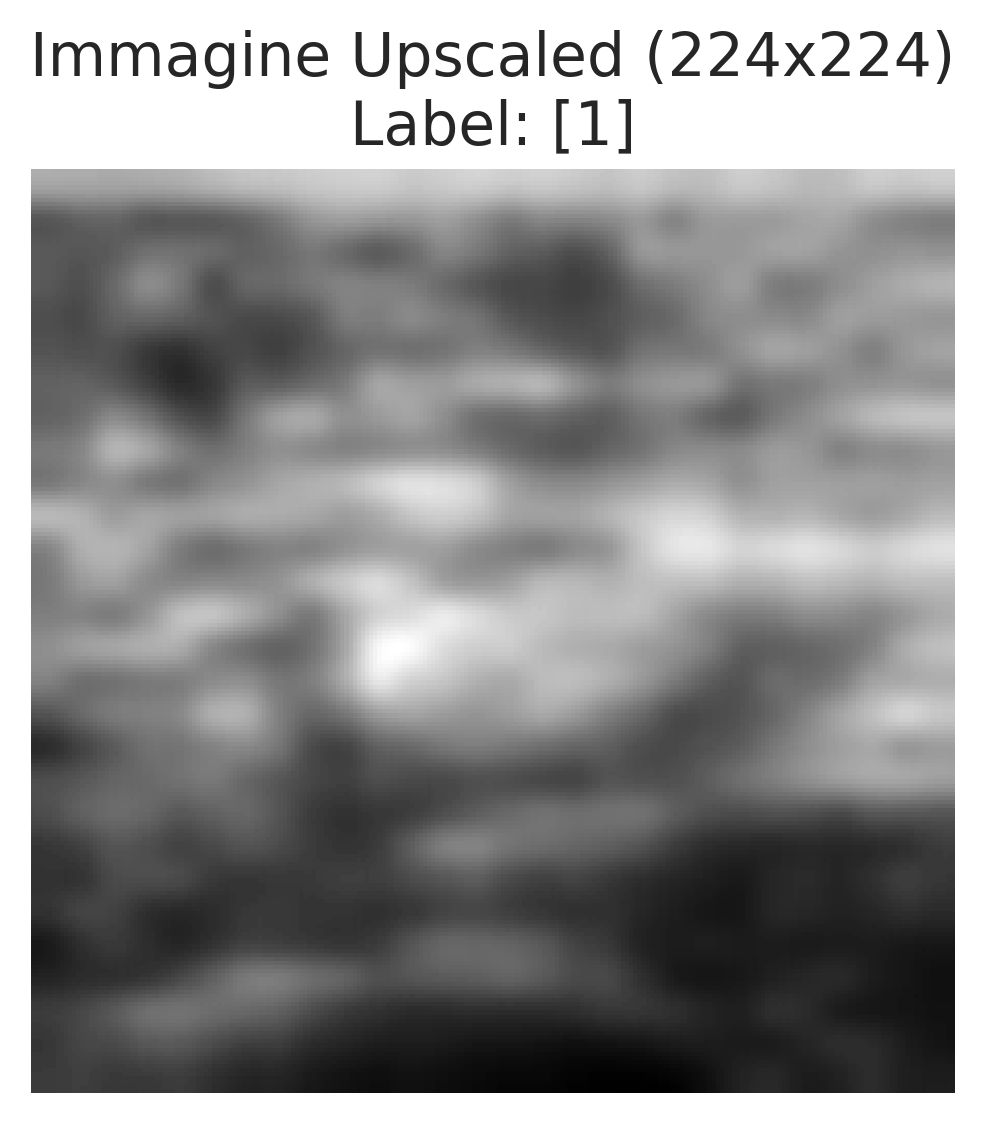

In [6]:
import torch
from torchvision import transforms
from medmnist import BreastMNIST
from torch.utils.data import DataLoader
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import wandb

# CALCOLO STATISTICHE
print(" Calcolo delle statistiche sul Training Set...")

# Carico il dataset SOLO con ToTensor (senza resize, senza normalizzare)
#    per leggere i valori reali dei pixel originali (28x28).
calc_transform = transforms.ToTensor()
train_dataset_raw = BreastMNIST(split='train', transform=calc_transform, download=True)

# Impilo tutte le immagini in un unico Tensore


data = torch.tensor(train_dataset_raw.imgs).float() / 255.0

# Calcolo Media e Deviazione Standard

mean_val = data.mean().item()
std_val = data.std().item()

print(f"\n Statistiche Calcolate:")
print(f"   MEAN (Media): {mean_val:.4f}")
print(f"   STD  (Dev.Std): {std_val:.4f}")
print("-" * 40)


# DEFINIZIONE PIPELINE DI TRASFORMAZIONE
# Ora uso i valori calcolati per definire la trasformazione finale.
# Inserisco il Resize a 224x224 necessario per lo Swin Transformer.

data_transform = transforms.Compose([
    # Upscaling da 28x28 a 224x224
    #    BICUBIC è meglio per le immagini mediche perché crea meno artefatti "a quadretti"
    transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),

    # Conversione in Tensore
    transforms.ToTensor(),

    # Normalizzazione con i valori calcolati
    #    Questo centra i dati esattamente sullo 0.
    transforms.Normalize(mean=[mean_val], std=[std_val])
])


# CARICAMENTO DATASET PRONTI PER SWIN
print(" Caricamento Dataset Finali (Resized & Normalized)...")

# Nota: Uso lo STESSO data_transform (con stats del train) per tutti i set
train_dataset = BreastMNIST(split='train', transform=data_transform, download=True)
val_dataset = BreastMNIST(split='val', transform=data_transform, download=True)
test_dataset = BreastMNIST(split='test', transform=data_transform, download=True)

print(f"\n Dataset Pronti per lo Swin Transformer!")
print(f"   Input Shape: {train_dataset[0][0].shape} (dovrebbe essere 1x224x224)")
print(f"   Valore Max pixel (approx): {train_dataset[0][0].max():.2f}")
print(f"   Valore Min pixel (approx): {train_dataset[0][0].min():.2f}")

# VISUALIZZAZIONE DI CONTROLLO
import matplotlib.pyplot as plt

img, label = train_dataset[0]
plt.figure(figsize=(4, 4))
plt.imshow(img.squeeze(), cmap='gray')
plt.title(f"Immagine Upscaled (224x224)\nLabel: {label}")
plt.axis('off')
plt.show()

In [7]:
import os
import matplotlib.pyplot as plt

def plot_results(history, save_dir='training_plots', model_name='model'):
    """
    Plotta Loss e Accuracy ad alta risoluzione per LaTeX.
    Salva sia in PDF (vettoriale) che PNG (alta risoluzione).
    """

    # Configurazione Stile "Scientifico"
    plt.rcParams.update({
        'font.size': 14,           # Testo più grande per leggibilità
        'font.family': 'serif',    # Font con grazie (simile a Times/LaTeX)
        'axes.labelsize': 14,      # Etichette assi
        'axes.titlesize': 16,      # Titoli
        'xtick.labelsize': 12,     # Numeri assi
        'ytick.labelsize': 12,
        'legend.fontsize': 12,
        'figure.dpi': 300,         # Risoluzione a schermo
        'savefig.dpi': 300,        # Risoluzione salvataggio
        'axes.grid': True,         # Griglia attiva
        'grid.alpha': 0.3          # Griglia leggera
    })

    # Creazione cartella per i salvataggi
    os.makedirs(save_dir, exist_ok=True)

    epochs = range(1, len(history['train_loss']) + 1)

    # Creiamo la figura (più larga per adattarsi bene ai documenti)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # GRAFICO LOSS
    # Usiamo colori ad alto contrasto e marker chiari
    ax1.plot(epochs, history['train_loss'], 'o-', label='Train Loss',
             color='#1f77b4', linewidth=2, markersize=6) # Blu

    if history['val_loss'] and history['val_loss'][0] is not None:
        ax1.plot(epochs, history['val_loss'], 's--', label='Val Loss',
                 color='#ff7f0e', linewidth=2, markersize=6) # Arancione

    ax1.set_title('Training & Validation Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Cross Entropy Loss')
    ax1.legend(frameon=True, fancybox=True, framealpha=0.9)

    # GRAFICO ACCURACY
    ax2.plot(epochs, history['train_acc'], 'o-', label='Train Acc',
             color='#2ca02c', linewidth=2, markersize=6) # Verde

    if history['val_acc'] and history['val_acc'][0] is not None:
        ax2.plot(epochs, history['val_acc'], 's--', label='Val Acc',
                 color='#d62728', linewidth=2, markersize=6) # Rosso

    ax2.set_title('Training & Validation Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend(frameon=True, fancybox=True, framealpha=0.9)

    plt.tight_layout()

    # SALVATAGGIO
    # PDF per il documento LaTeX (Vettoriale, qualità infinita)
    pdf_path = os.path.join(save_dir, f'{model_name}_results.pdf')
    plt.savefig(pdf_path, format='pdf', bbox_inches='tight')

    # PNG per le Slide / Powerpoint (Alta risoluzione)
    png_path = os.path.join(save_dir, f'{model_name}_results.png')
    plt.savefig(png_path, format='png', bbox_inches='tight')

    print(f"Grafici salvati in alta risoluzione in: {save_dir}")
    print(f"    PDF: {pdf_path}")
    print(f"    PNG: {png_path}")

    plt.show()

### Pipeline per training, validation e test

In [8]:
def train_one_epoch(model, train_loader, optimizer, loss_fn, do_squeeze=False, device="cpu"):
    model.train()
    model.to(device)

    # Controllo di sicurezza sulla reduction
    if hasattr(loss_fn, "reduction") and loss_fn.reduction != "mean":
        raise ValueError("loss_fn must use reduction='mean'")

    total_loss = 0.0
    total_samples = 0

    acc_sum = 0.0
    acc_count = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        if do_squeeze:
            labels = labels.to(device, non_blocking=True).squeeze().long()
        else:
            labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(inputs)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = inputs.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        with torch.no_grad():
          _, preds = torch.max(outputs, 1)
          acc_batch = (preds == labels).float().mean().item()
          acc_sum += acc_batch * batch_size
          acc_count += batch_size

    epoch_loss = total_loss / total_samples
    epoch_acc = acc_sum / acc_count


    return epoch_loss, epoch_acc


def evaluate_model(model, val_loader, loss_fn, do_squeeze=False, device=None):
    model.to(device)
    model.eval()

    # Controllo di sicurezza sulla reduction
    if hasattr(loss_fn, "reduction") and loss_fn.reduction != "mean":
        raise ValueError("loss_fn must use reduction='mean'")

    total_loss = 0.0
    total_samples = 0

    acc_sum = 0.0
    acc_count = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, non_blocking=True)
            if do_squeeze:
                labels = labels.to(device, non_blocking=True).squeeze().long()
            else:
                labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            loss = loss_fn(outputs, labels)

            batch_size = inputs.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            _, preds = torch.max(outputs, 1)
            acc_batch = (preds == labels).float().mean().item()

            acc_sum += acc_batch * batch_size
            acc_count += batch_size

    val_loss = total_loss / total_samples
    val_acc = acc_sum / acc_count

    return val_loss, val_acc

In [9]:
def train_pipeline(
    model,
    optimizer,
    train_loader,
    val_loader=None,
    loss_fn=None,
    model_name="N/A",
    epochs=10,
    device=None,
    scheduler=None,
    early_stopping=False,
    patience=5,
    checkpoint_interval=0,
    verbose=True,
    drive_dir=None,
    save_best_model=False,
    wandb_flag=None
):
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    if drive_dir is not None:
      # Setup Cartella di Salvataggio (Solo Drive)
      timestamp = time.strftime("%Y%m%d_%H%M%S")
      run_name = f"{model_name}_{timestamp}"
      # Cartella specifica per questa run
      save_dir = os.path.join(drive_dir, run_name)
      os.makedirs(save_dir, exist_ok=True)

    if verbose and drive_dir is not None:
        print(f"I modelli verranno salvati in: {save_dir}")

    best_metric = -float("inf")
    epochs_no_improve = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    with tqdm(range(epochs), desc=f"Training {model_name}", ncols=150) as pbar:
        for epoch in pbar:
            # Training
            train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, loss_fn, do_squeeze=True, device=device)

            # Validation
            val_loss, val_acc = (None, None)
            if val_loader is not None:
                val_loss, val_acc = evaluate_model(model, val_loader, loss_fn, do_squeeze=True, device=device)

            # Scheduler
            if scheduler:
                if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau) and val_loss is not None:
                    scheduler.step(val_loss)
                else:
                    scheduler.step()

            # History update
            history['train_loss'].append(train_loss)
            history['train_acc'].append(train_acc)
            if val_loader is not None:
                history['val_loss'].append(val_loss)
                history['val_acc'].append(val_acc)

            # WandB Log
            if wandb_flag:
              log_dict = {"Train Loss": train_loss, "Train Accuracy": train_acc, "epoch": epoch + 1}
              if val_acc is not None:
                  log_dict["Validation Accuracy"] = val_acc
                  log_dict["Validation Loss"] = val_loss
              wandb.log(log_dict)

            if verbose:
                postfix = {"Train Loss": f"{train_loss:.4f}", "Train Acc": f"{train_acc:.4f}"}
                if val_loader is not None:
                    postfix.update({"Val Loss": f"{val_loss:.4f}", "Val Acc": f"{val_acc:.4f}"})
                pbar.set_postfix(postfix)

            #Checkpoint Periodico
            if checkpoint_interval > 0 and (epoch + 1) % checkpoint_interval == 0 and drive_dir is not None:
                path = os.path.join(save_dir, f"epoch_{epoch+1}.pt")
                torch.save({
                    "epoch": epoch+1,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "history": history
                }, path)

            # Salvataggio Best Model (Indipendente da Early Stopping)
            if val_loader is not None and val_acc is not None:
              if val_acc > best_metric:
                epochs_no_improve = 0
                best_metric = val_acc
                if drive_dir is not None:
                  if save_best_model:
                    # Salvo il Best Model direttamente nella cartella save_dir
                    best_path = os.path.join(save_dir, "best_model.pt")
                    torch.save({
                        "epoch": epoch+1,
                        "model_state_dict": model.state_dict(),
                        "optimizer_state_dict": optimizer.state_dict(),
                        "history": history,
                        "best_acc": best_metric
                    }, best_path)

              else:
                epochs_no_improve += 1

            # Early Stopping Check
            if early_stopping and epochs_no_improve >= patience:
                pbar.write(f"[Early Stopping] Nessun miglioramento per {patience} epoche.")
                break


    return model, history

### Funzione per calcolare le metriche mediche del paper

In [10]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import confusion_matrix, roc_auc_score, balanced_accuracy_score, accuracy_score
from tqdm.notebook import tqdm

def calculate_metrics(model, dataloader, device="cuda", dataset_name="Dataset"):
    """
    Calcola le metriche complete (Paper Standard) per un modello generico su un dataset generico.
    Gestisce automaticamente il mapping: Classe 0 (Maligno) vs Classe 1 (Benigno).
    """
    model.eval()
    model.to(device)

    all_targets = []
    all_preds = []
    all_probs = [] # Serve per l'AUC

    print(f"Avvio Valutazione su: {dataset_name}...")

    with torch.no_grad():
        for inputs, targets in tqdm(dataloader, desc="Inference", leave=False):
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Forward Pass
            outputs = model(inputs)

            # Probabilità (Softmax) per AUC
            probs = F.softmax(outputs, dim=1)

            # Predizione secca (Argmax)
            _, preds = torch.max(outputs, 1)

            # Accumulo su CPU
            all_targets.extend(targets.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    # Conversione in array Numpy
    y_true = np.array(all_targets)
    y_pred = np.array(all_preds)
    y_probs = np.array(all_probs)

    # CALCOLO METRICHE

    # 1. Matrice di Confusione
    # Sklearn ordina le classi: [0, 0], [0, 1], [1, 0], [1, 1]
    # In questo caso: 0=Maligno, 1=Benigno
    cm = confusion_matrix(y_true, y_pred)

    # Estrazione valori puri
    # True Malignants (Predetti 0, Veri 0)
    true_malignant = cm[0, 0]
    # False Benigns (Predetti 1, Veri 0) -> I Maligni persi!
    false_benign = cm[0, 1]
    # False Malignants (Predetti 0, Veri 1) -> Falsi allarmi
    false_malignant = cm[1, 0]
    # True Benigns (Predetti 1, Veri 1)
    true_benign = cm[1, 1]

    # 2. Sensitivity
    # Capacità di trovare i tumori
    sensitivity = true_malignant / (true_malignant + false_benign) if (true_malignant + false_benign) > 0 else 0

    # 3. Specificity
    # Capacità di escludere i sani
    specificity = true_benign / (true_benign + false_malignant) if (true_benign + false_malignant) > 0 else 0

    # 4. Balanced Accuracy (Media tra Sens e Spec)
    bacc = balanced_accuracy_score(y_true, y_pred)

    # 5. AUC (Area Under Curve)
    # Calcolo l'AUC.

    try:
        auc = roc_auc_score(y_true, y_probs[:, 1])
    except ValueError:
        auc = 0.5 # Fallback se c'è una sola classe nel batch (raro)

    # 6. Accuracy Standard
    acc = accuracy_score(y_true, y_pred)

    # --- STAMPA REPORT ---
    print("\n" + "="*50)
    print(f"📊 REPORT METRICHE: {dataset_name}")
    print("="*50)
    print(f"✅ Accuracy Standard:    {acc:.4f}")
    print(f"⚖️  Balanced Accuracy:    {bacc:.4f}  (Target Paper)")
    print(f"📈 AUC Score:            {auc:.4f}")
    print("-" * 30)
    print(f"🔍 Sensitivity (Maligno): {sensitivity:.4f}  (Capacità di trovare tumori)")
    print(f"🛡️  Specificity (Benigno): {specificity:.4f}")
    print("="*50 + "\n")

    # Restituisce un dizionario per uso futuro (es. loggare su WandB o salvare su file)
    return {
        "bacc": bacc,
        "auc": auc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "accuracy": acc
    }

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# CREAZIONE DATALOADERS
# Batch size 32 dovrebbe essere standard per Swin-B su Colab
BATCH_SIZE = 32

print(" Creazione DataLoader...")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,          # Velocizza il caricamento dati
    pin_memory=True         # Velocizza il trasferimento in GPU
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

 Creazione DataLoader...


In [12]:
class_weights_classic_1 = torch.tensor([2.7, 1.0]).to("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# CONFIGURAZIONE TRAINING
# Ricarico il modello pulito
model_classic_1 = get_classical_swin_model()

# Optimizer: SGD come nel paper (Learning Rate 0.001 o 0.0004 come nel paper)
# Il paper usa 0.0004, provo a replicarlo.
optimizer_classic_1 = optim.SGD(model_classic_1.parameters(), lr=0.0004, momentum=0.9, weight_decay=1e-4)

# Loss Function PESATA per lo sbilanciamento (Class 0: Maligno, Class 1: Benigno)
# visti circa 3 volte più benigni. Quindi diamo peso circa 3 ai maligni.
# Peso preciso = N_Benigni / N_Maligni = 570 / 210 ≈ 2.7
loss_fn_classic_1 = nn.CrossEntropyLoss(weight=class_weights_classic_1)

# Scheduler
scheduler_classic_1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_classic_1, mode='min', factor=0.1, patience=3)

# AVVIO FINE-TUNING
print("\n AVVIO TRAINING SWIN TRANSFORMER (CLASSICO)...")

model_classic_1_trained, history_classic_1 = train_pipeline(
    model=model_classic_1,
    optimizer=optimizer_classic_1,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_classic_1,
    model_name="model_classic_1",
    epochs=50,
    patience=10,                # Early Stopping
    early_stopping=True,
    scheduler=scheduler_classic_1,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)



🚀 AVVIO TRAINING SWIN TRANSFORMER (CLASSICO)...
I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_classic_1_20260211_210555


Training model_classic_1:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_classic_1_results.pdf
   🖼️ PNG: training_plots/model_classic_1_results.png


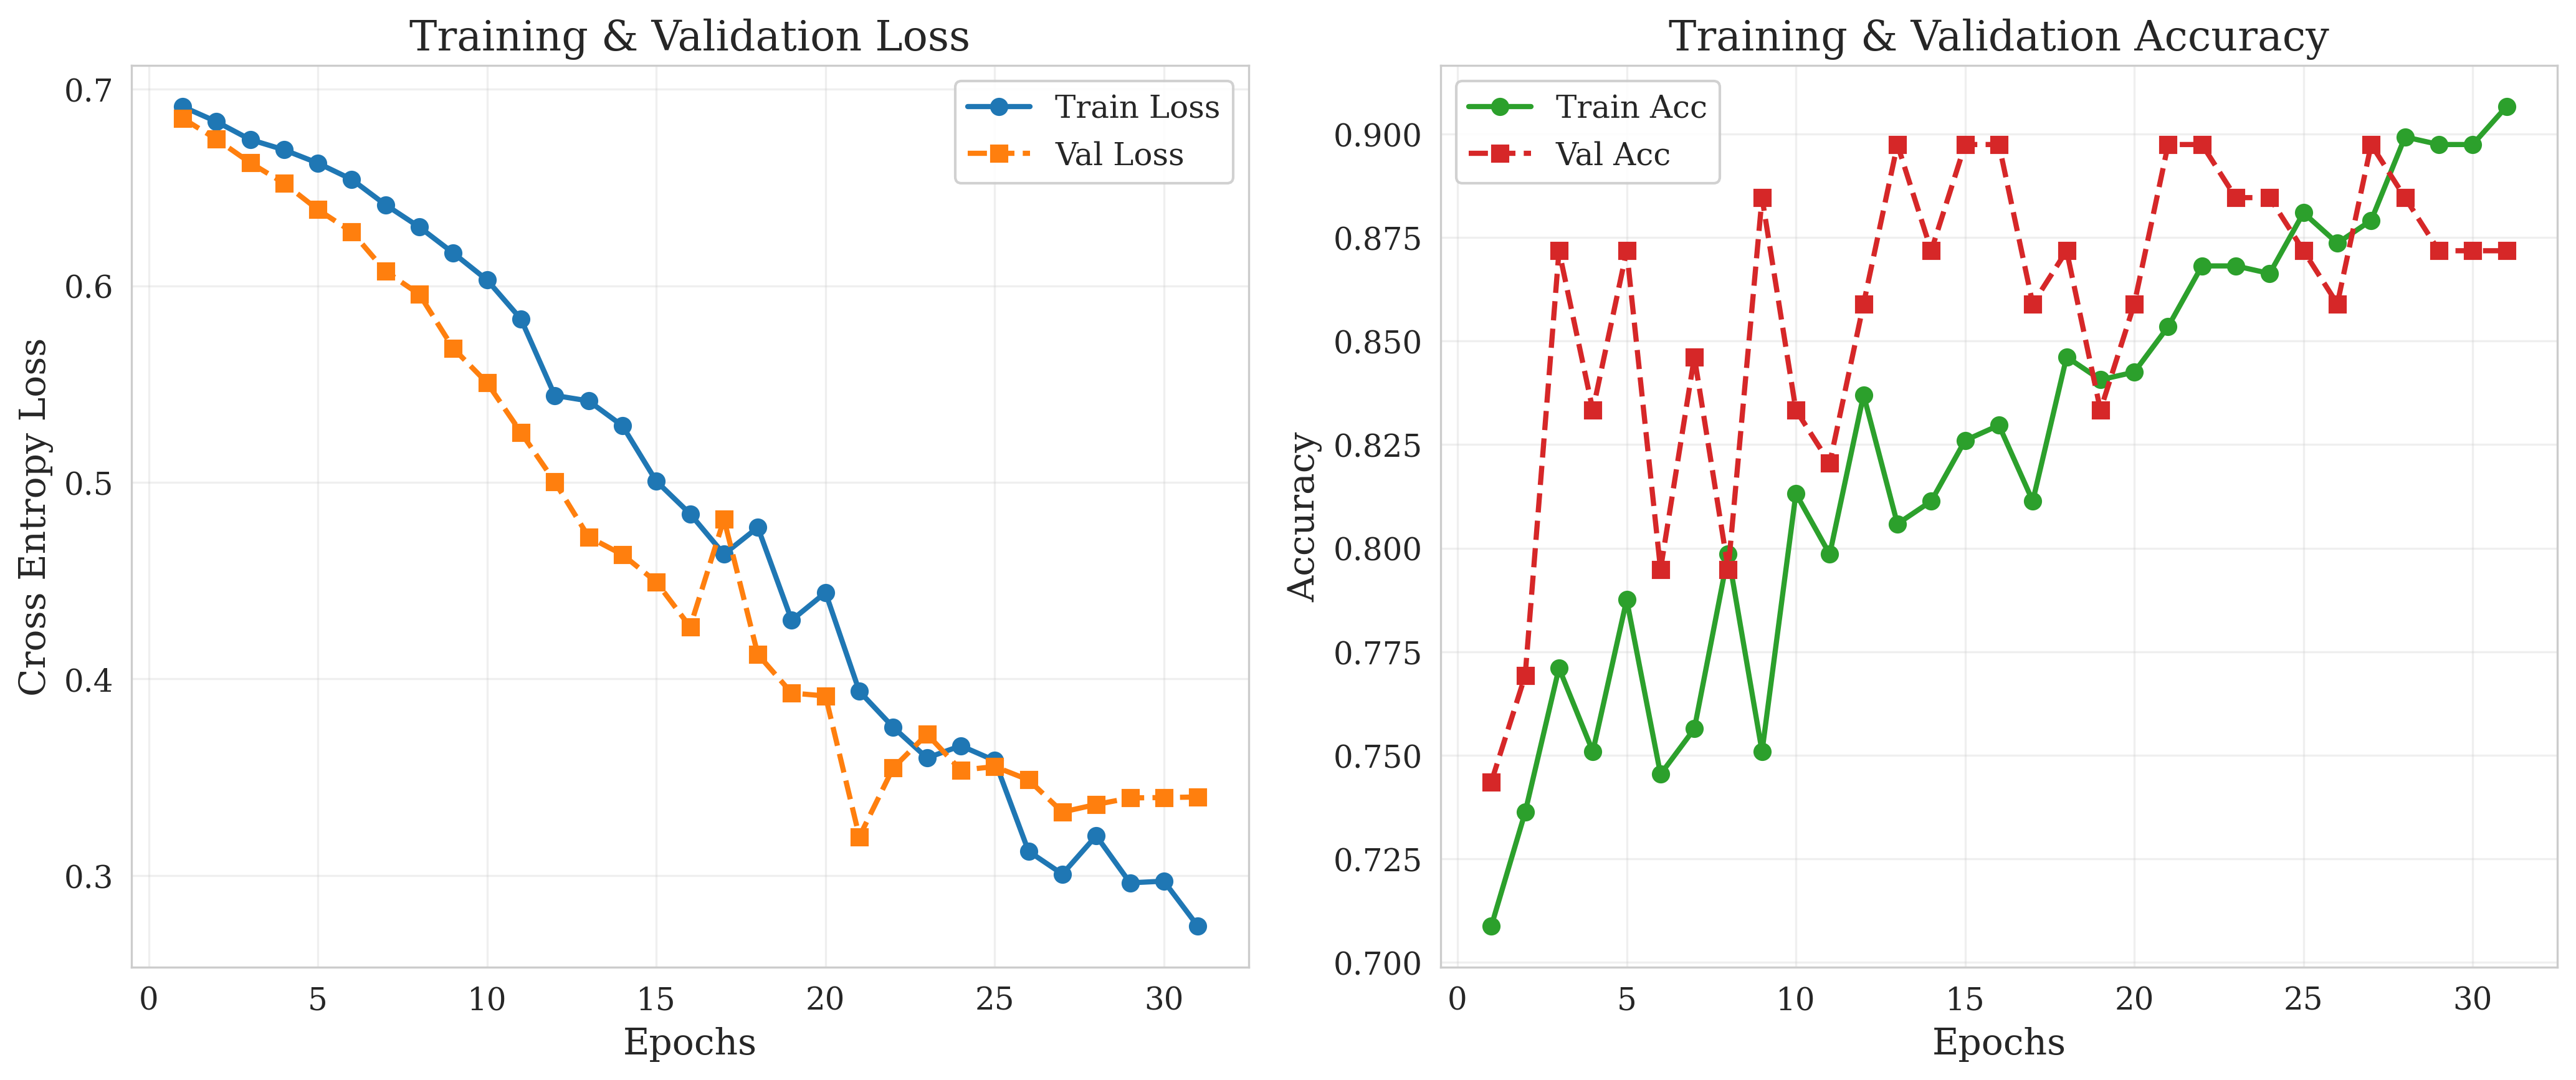

In [ ]:
# VISUALIZZAZIONE RISULTATI
print("\n Generazione Grafici...")
plot_results(history_classic_1, save_dir='training_plots', model_name='model_classic_1')

In [ ]:
print(" VERIFICA INTERMEDIA SUL VALIDATION SET")
print("Obiettivo: Controllare se il modello sta imparando a generalizzare (BACC > 0.5)")

# Chiamata alla funzione generica
val_metrics_classic_1 = calculate_metrics(
    model=model_classic_1_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)


if val_metrics_classic_1['bacc'] > 0.70:
    print(" OTTIMO SEGNALE: Il modello ha una Balanced Accuracy solida sul validation.")
    print("   Significa che sta gestendo bene lo sbilanciamento delle classi.")
elif val_metrics_classic_1['bacc'] > 0.55:
    print(" SEGNALE MEDIO: Il modello impara qualcosa, ma fa fatica sulle classi rare.")
    print("   Forse è necessario aumentare il peso della classe Maligno (class_weights).")
else:
    print(" Il modello sta tirando a indovinare (BACC ~ 0.5).")
    print("   Probabilmente sta predicendo tutto 'Benigno'")

🔍 VERIFICA INTERMEDIA SUL VALIDATION SET
Obiettivo: Controllare se il modello sta imparando a generalizzare (BACC > 0.5)
🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8718
⚖️  Balanced Accuracy:    0.8371  (Target Paper)
📈 AUC Score:            0.9357
------------------------------
🔍 Sensitivity (Maligno): 0.7619  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9123

✅ OTTIMO SEGNALE: Il modello ha una Balanced Accuracy solida sul validation.
   Significa che sta gestendo bene lo sbilanciamento delle classi.


## Fine Tuning di QEST (Quantum) su BreastMNIST

In [4]:
!pip install pennylane pennylane-qiskit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 51.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 935.6/935.6 kB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 79.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 99.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 86.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.9/167.9 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.7/378.7 kB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 105.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 

In [5]:
# Import Generici
import pennylane as qml
from pennylane import numpy as npp

# Import PyTorch
import torch
import torch.nn as nn
import torch.optim as optim



import qiskit

In [6]:
def qnode_factory(circuit_template, n_qubits, device_q, interface="torch"):
    """
    Crea un QNode configurato pronto per qml.qnn.TorchLayer.

    Args:
        circuit_template (func): Una funzione Python che accetta (inputs, weights, n_qubits)
                                 e contiene la logica del circuito (embedding + ansatz + misura).
        n_qubits (int): Il numero di qubit da utilizzare.
        device (qml.Device): L'oggetto device di PennyLane già istanziato (es. default.qubit).

    Returns:
        qml.QNode: Il nodo quantistico configurato con interfaccia Torch.
    """

    # Definiamo il QNode usando il device passato in input
    @qml.qnode(device_q, interface=interface)
    def configured_qnode(inputs, weights):

        # Questo adatta la firma per TorchLayer che si aspetta solo (inputs, weights)
        return circuit_template(inputs, weights, n_qubits)

    return configured_qnode

In [7]:
import pennylane as qml
import matplotlib.pyplot as plt
import time
from google.colab import files

def export_professional_circuit(qnode, dummy_args, filename="quantum_ansatz", style="pennylane", dpi=300):
    """
    Genera ed esporta l'immagine di un circuito quantistico in altissima qualità.

    Parametri:
    - qnode: La funzione del circuito quantistico (decorata con @qml.qnode o creata con QNode).
    - dummy_args: Tupla contenente i dati finti da passare al circuito (es. (inputs, weights)).
    - filename: Nome del file in uscita (senza estensione).
    - style: Stile visivo di PennyLane ('pennylane', 'black_white', 'solarized_dark', 'sketch').
    - dpi: Risoluzione per il file PNG (300 è lo standard per le stampe tipografiche/paper).
    """
    print(f"Generazione del circuito '{filename}' in corso...")

    # 1. Disegna il circuito usando Matplotlib e lo stile scelto
    fig, ax = qml.draw_mpl(qnode, style=style)(*dummy_args)

    # 2. Rendi lo sfondo trasparente se necessario (opzionale ma utile per slide scure)
    # fig.patch.set_alpha(0.0)

    # Nomi dei file
    pdf_path = f"{filename}.pdf"
    png_path = f"{filename}.png"

    # 3. Salvataggio Vettoriale (PDF) - Il Gold Standard per LaTeX
    # bbox_inches='tight' è CRUCIALE: taglia via tutti i margini bianchi inutili
    fig.savefig(pdf_path, format='pdf', bbox_inches='tight')

    # 4. Salvataggio Raster Alta Risoluzione (PNG)
    fig.savefig(png_path, format='png', dpi=dpi, bbox_inches='tight')

    # Chiude la figura per non intasare la memoria di Colab
    plt.close(fig)

    # 5. Download automatico
    print(f"Download di {pdf_path} e {png_path}...")
    files.download(pdf_path)
    time.sleep(1) # Piccola pausa per evitare che Colab blocchi i popup multipli
    files.download(png_path)
    print("Fatto! Immagini pronte per LaTeX.")

#### VQC 8 qubit

In [8]:

n_qubits = 8
dev_8 = qml.device("default.qubit", wires=n_qubits)

def custom_angle_embedding(inputs):
    """
    Implementazione dell'Angle Embedding secondo l'Eq. 2 del Paper.

    Args:
        inputs (torch.Tensor): Il vettore di feature in ingresso (dimensione N).
        wires (iterable): La lista dei qubit su cui applicare l'embedding.
    """
    # PREPROCESSING
    # Trasformo l'input x in x' usando l'arcotangente.
    n_qubits_local = inputs.shape[-1]
    x_prime = torch.atan(inputs)

    # Ciclo su tutti i qubit
    for i in range(n_qubits_local):

        # HADAMARD

        qml.Hadamard(wires=i)

        # Estraiamo il valore per l'i-esimo qubit
        angle = x_prime[..., i]

        # ROTAZIONE Y
        # Ruota di x'
        qml.RY(angle, wires=i)

        # ROTAZIONE Z
        # Ruota di (x')^2
        # Nota: L'elevamento al quadrato aumenta la "non-linearità"
        qml.RZ(angle**2, wires=i)

In [10]:
#@qml.qnode(dev_8, interface="torch")

def circuit(inputs, weights):
  n_qubits_local = inputs.shape[-1]
  n_layers = weights.shape[0]
  custom_angle_embedding(inputs)
  for l in range(n_layers):

        # SOTTO-FASE A: Rotazioni U3 (Apprendimento)
        # Applichiamo una U3 su OGNI qubit
        for q in range(n_qubits_local):
            # Estraiamo i 3 parametri dal tensore dei pesi
            # weights[l, q] è un vettore di 3 numeri: [theta, phi, lambda]
            theta, phi, lam = weights[l, q]

            # Applichiamo la porta
            qml.U3(theta, phi, lam, wires=q)

        # SOTTO-FASE B: Entanglement
        # Porte CZ a catena
        for q in range(n_qubits_local - 1): # Fino al penultimo
             qml.CZ(wires=[q, q + 1])

  return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits_local)]


In [ ]:
n_layers = 2
weight_shapes = {"weights": (n_layers, n_qubits, 3)}

vqc_layer = qml.qnn.TorchLayer(circuit, weight_shapes)

NameError: name 'circuit' is not defined

In [ ]:
def get_quantum_swin_model(n_qubits=8):
    # RIUTILIZZO: Carichiamo il modello classico di base
    # Questo dà lo Swin-B pre-addestrato
    model = get_classical_swin_model()

    # Sostituisco la 'head' classica con quella ibrida

    num_features = model.head[0].in_features

    # DEFINIZIONE DELLA TESTA QUANTISTICA (Hybrid Head)


    model.head = nn.Sequential(
        # COMPRESSIONE (Classical Down-sampling)
        # Riduce da 1024 a 8
        nn.Linear(num_features, n_qubits),

        # CIRCUITO QUANTISTICO (VQC)
        # Prende 8 valori -> li elabora -> restituisce 8 valori di aspettazione
        vqc_layer,

        # INTERPRETE (Post-processing)
        # Prende gli 8 output dei qubit e decide le 2 classi (Benigno/Maligno)
        # Questo permette alla rete di "post-processare gli output"
        nn.Linear(n_qubits, 2)
    )

    return model

In [ ]:
#viene istanziato il modello con 8 qubit
model_quantum_1 = get_quantum_swin_model(n_qubits=8)
# Separiamo i parametri del VQC da quelli Classici
# Il VQC è il secondo elemento di model.head (indice 1)
params_quantum_1 = list(model_quantum_1.head[1].parameters())
quantum_1_ids = list(map(id, params_quantum_1))

# I parametri classici sono tutto il resto
classical_params = filter(lambda p: id(p) not in quantum_1_ids, model_quantum_1.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_1 = optim.SGD([
    {'params': classical_params, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_1,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_1, mode='min', factor=0.1, patience=3)
loss_fn_quantum_1 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_1_trained, history_quantum_1 = train_pipeline(
    model=model_quantum_1,
    optimizer=optimizer_quantum_1,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_1,
    model_name="model_quantum_1",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_1,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_quantum_1_20260211_211135


Training model_quantum_1:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_1_results.pdf
   🖼️ PNG: training_plots/model_quantum_1_results.png


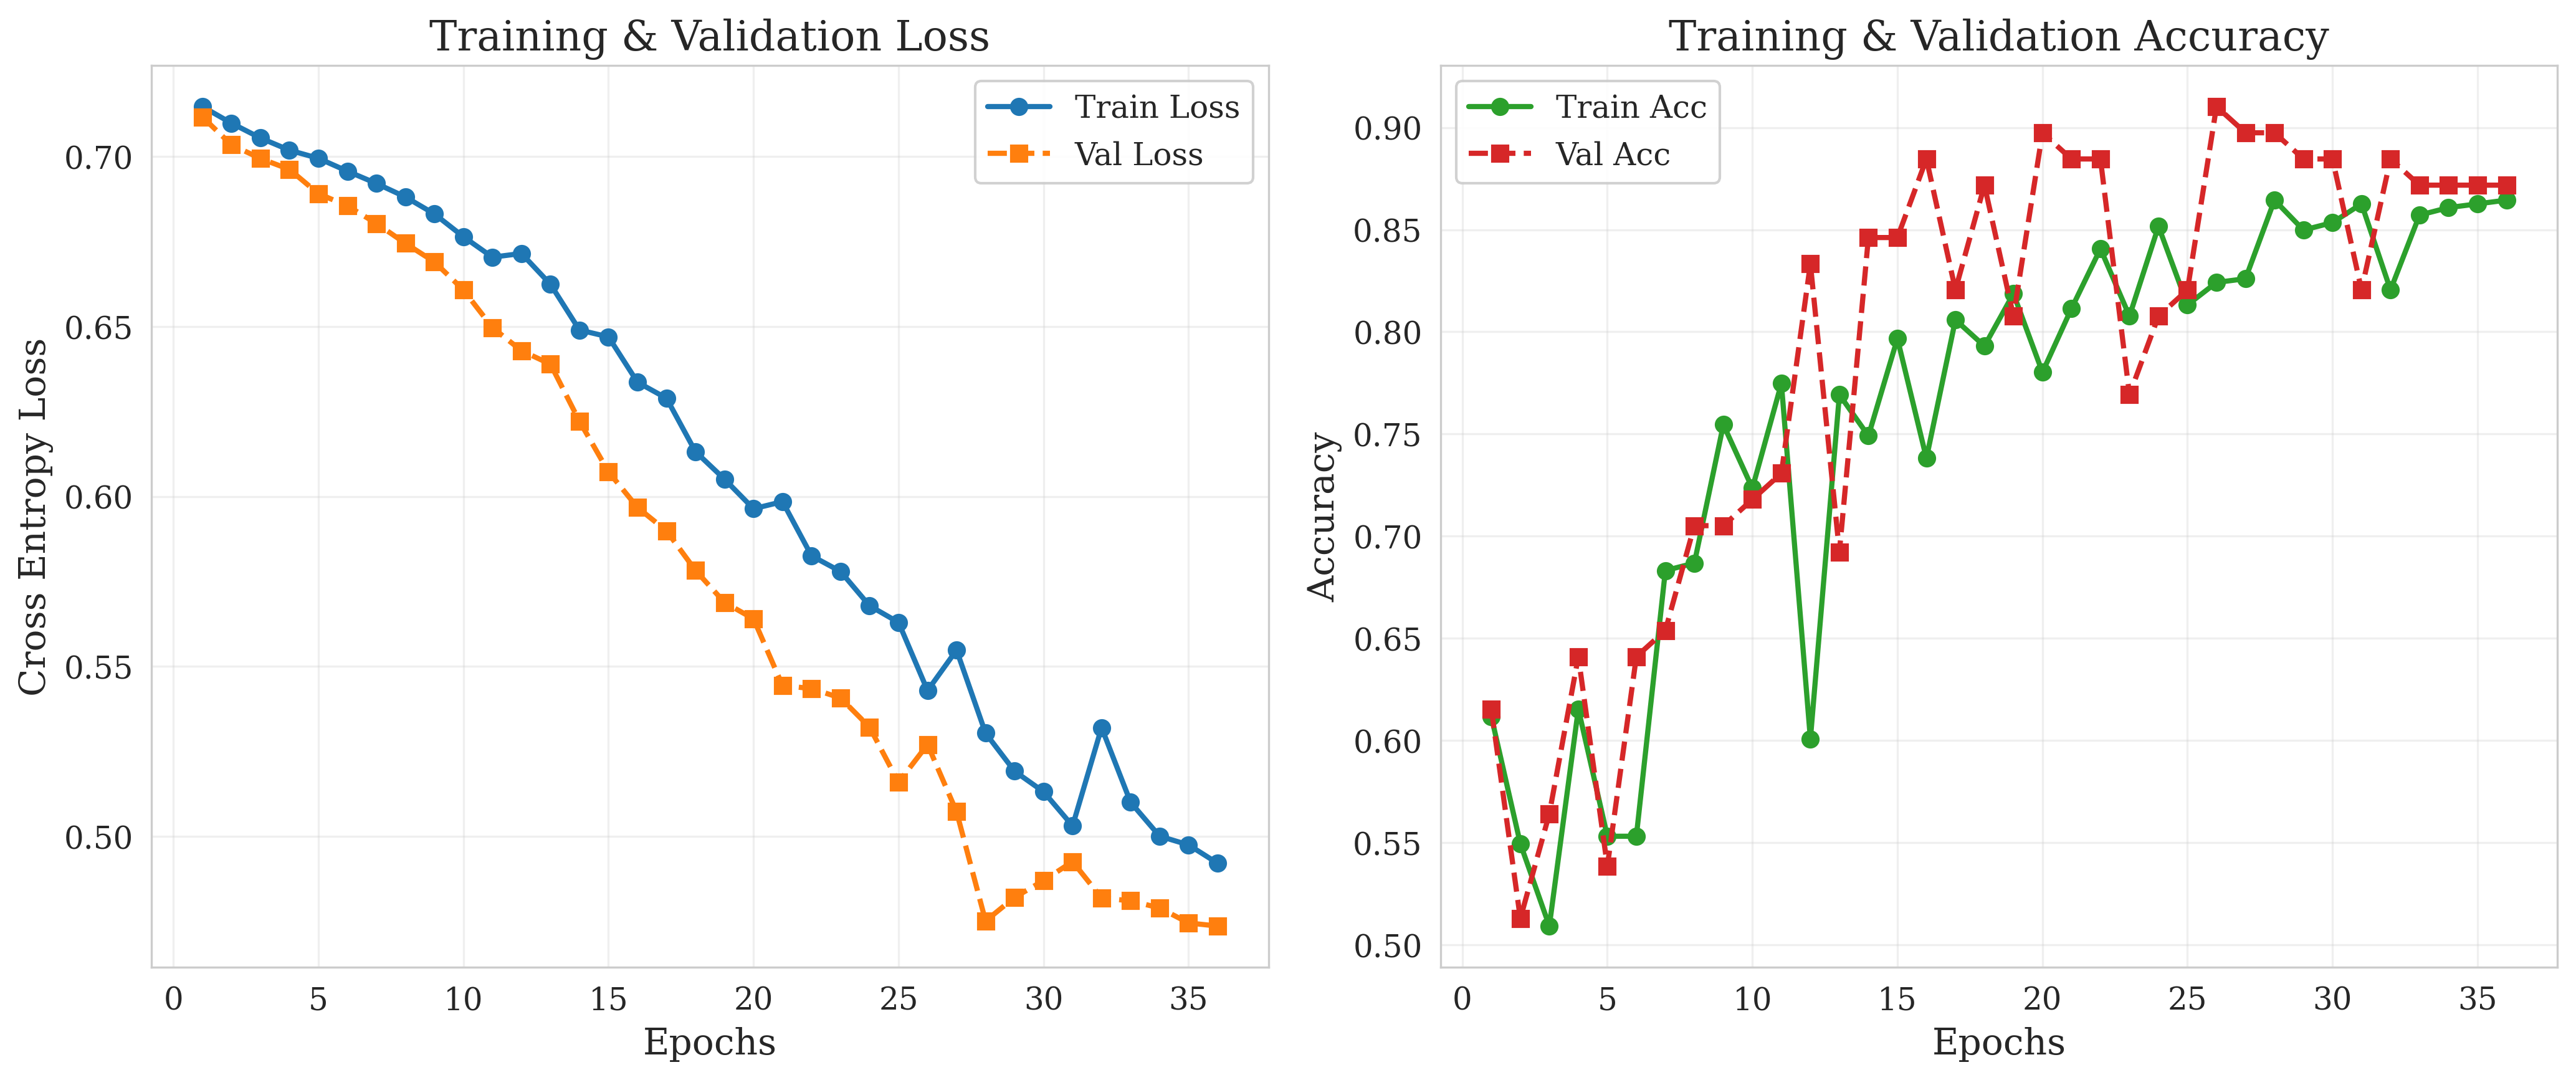

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_1, save_dir='training_plots', model_name='model_quantum_1')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_1 = calculate_metrics(
    model=model_quantum_1_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8718
⚖️  Balanced Accuracy:    0.8672  (Target Paper)
📈 AUC Score:            0.9465
------------------------------
🔍 Sensitivity (Maligno): 0.8571  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8772



### Codice per 1000 shots

In [ ]:
dev_8_finite = qml.device("default.qubit", wires=n_qubits, shots=1000)

/usr/local/lib/python3.12/dist-packages/pennylane/devices/device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


In [ ]:
@qml.qnode(dev_8_finite, interface="torch")

def circuit_finite(inputs, weights):
  custom_angle_embedding(inputs)
  n_layers = weights.shape[0]
  for l in range(n_layers):

        # SOTTO-FASE A: Rotazioni U3 (Apprendimento)
        # Applichiamo una U3 su OGNI qubit
        for q in range(n_qubits):
            # Estraiamo i 3 parametri dal tensore dei pesi
            # weights[l, q] è un vettore di 3 numeri: [theta, phi, lambda]
            theta, phi, lam = weights[l, q]

            # Applichiamo la porta
            qml.U3(theta, phi, lam, wires=q)

        # SOTTO-FASE B: Entanglement (Connessione)
        # Porte CZ a catena
        for q in range(n_qubits - 1): # Fino al penultimo
             qml.CZ(wires=[q, q + 1])

  return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [ ]:
vqc_layer_f = qml.qnn.TorchLayer(circuit_finite, weight_shapes)

In [ ]:
def get_quantum_swin_model_finite(n_qubits=8):
    # RIUTILIZZO: Carico il modello classico di base

    model = get_classical_swin_model()

    # Sostituisco la 'head' classica con quella ibrida

    num_features = model.head[0].in_features

    # DEFINIZIONE DELLA TESTA QUANTISTICA (Hybrid Head)


    model.head = nn.Sequential(
        # COMPRESSIONE (Classical Down-sampling)
        # Riduce da 1024 a 8
        nn.Linear(num_features, n_qubits),

        # CIRCUITO QUANTISTICO (VQC)
        # Prende 8 valori -> li elabora -> restituisce 8 valori di aspettazione
        vqc_layer_f,

        # INTERPRETE (Post-processing)
        # Prende gli 8 output dei qubit e decide le 2 classi (Benigno/Maligno)
        # Questo permette alla rete di "post-processare gli output"
        nn.Linear(n_qubits, 2)
    )

    return model

### VQC 16 qubit

Di seguito è implementata un'astrazione del codice per l'implementazione del VQC del paper, in modo che se ne possano variare i parametri in modo più agevole.

In [17]:
def create_vqc_layer(n_qubits, device_quantum="default.qubit"):
    """
    Genera un layer VQC PyTorch configurato per n_qubits specifici.
    Incapsula device, embedding e circuito per evitare conflitti globali.
    """
    # Crea il device locale (Simulatore o Reale)

    dev = qml.device(device_quantum, wires=n_qubits)

    # Definisco le funzioni interne che "vedono" n_qubits locale
    def local_embedding(inputs):
        x_prime = torch.atan(inputs)
        for i in range(n_qubits):
            qml.Hadamard(wires=i)
            angle = x_prime[..., i]
            qml.RY(angle, wires=i)
            qml.RZ(angle**2, wires=i)

    @qml.qnode(dev, interface="torch")
    def local_circuit(inputs, weights):
        local_embedding(inputs)
        n_layers = weights.shape[0]

        for l in range(n_layers):
            # U3 Gates (Learning)
            for q in range(n_qubits):
                theta, phi, lam = weights[l, q]
                qml.U3(theta, phi, lam, wires=q)

            # Entanglement
            for q in range(n_qubits - 1):
                qml.CZ(wires=[q, q + 1])

        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    # Configurazione Pesi e Creazione Layer
    n_layers = 2
    weight_shapes = {"weights": (n_layers, n_qubits, 3)}
    return qml.qnn.TorchLayer(local_circuit, weight_shapes)

In [ ]:
n_qubits_2 = 16
vqc_layer_16 = create_vqc_layer(n_qubits_2)

In [18]:
def get_quantum_swin_model_arg(vqc_layer, n_qubits=8):
    # RIUTILIZZO: Carico il modello classico di base

    model = get_classical_swin_model()

    # Sostituisco la 'head' classica con quella ibrida

    num_features = model.head[0].in_features

    # DEFINIZIONE DELLA TESTA QUANTISTICA (Hybrid Head)


    model.head = nn.Sequential(
        # COMPRESSIONE (Classical Down-sampling)
        # Riduce da 1024 a 8
        nn.Linear(num_features, n_qubits),

        # CIRCUITO QUANTISTICO (VQC)
        # Prende 8 valori -> li elabora -> restituisce 8 valori di aspettazione
        vqc_layer,

        # INTERPRETE (Post-processing)
        # Prende gli 8 output dei qubit e decide le 2 classi (Benigno/Maligno)
        # Questo permette alla rete di "post-processare gli output"
        nn.Linear(n_qubits, 2)
    )

    return model

In [ ]:
model_quantum_2 = get_quantum_swin_model_arg(vqc_layer_16, n_qubits_2)
params_quantum_2 = list(model_quantum_2.head[1].parameters())
quantum_2_ids = list(map(id, params_quantum_2))

# I parametri classici sono tutto il resto
classical_params_2 = filter(lambda p: id(p) not in quantum_2_ids, model_quantum_2.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_2 = optim.SGD([
    {'params': classical_params_2, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_2,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_2, mode='min', factor=0.1, patience=3)
loss_fn_quantum_2 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_2_trained, history_quantum_2 = train_pipeline(
    model=model_quantum_2,
    optimizer=optimizer_quantum_2,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_2,
    model_name="model_quantum_2",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_2,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_quantum_2_20260211_211645


Training model_quantum_2:   0%|                                                                               …


📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_2_results.pdf
   🖼️ PNG: training_plots/model_quantum_2_results.png


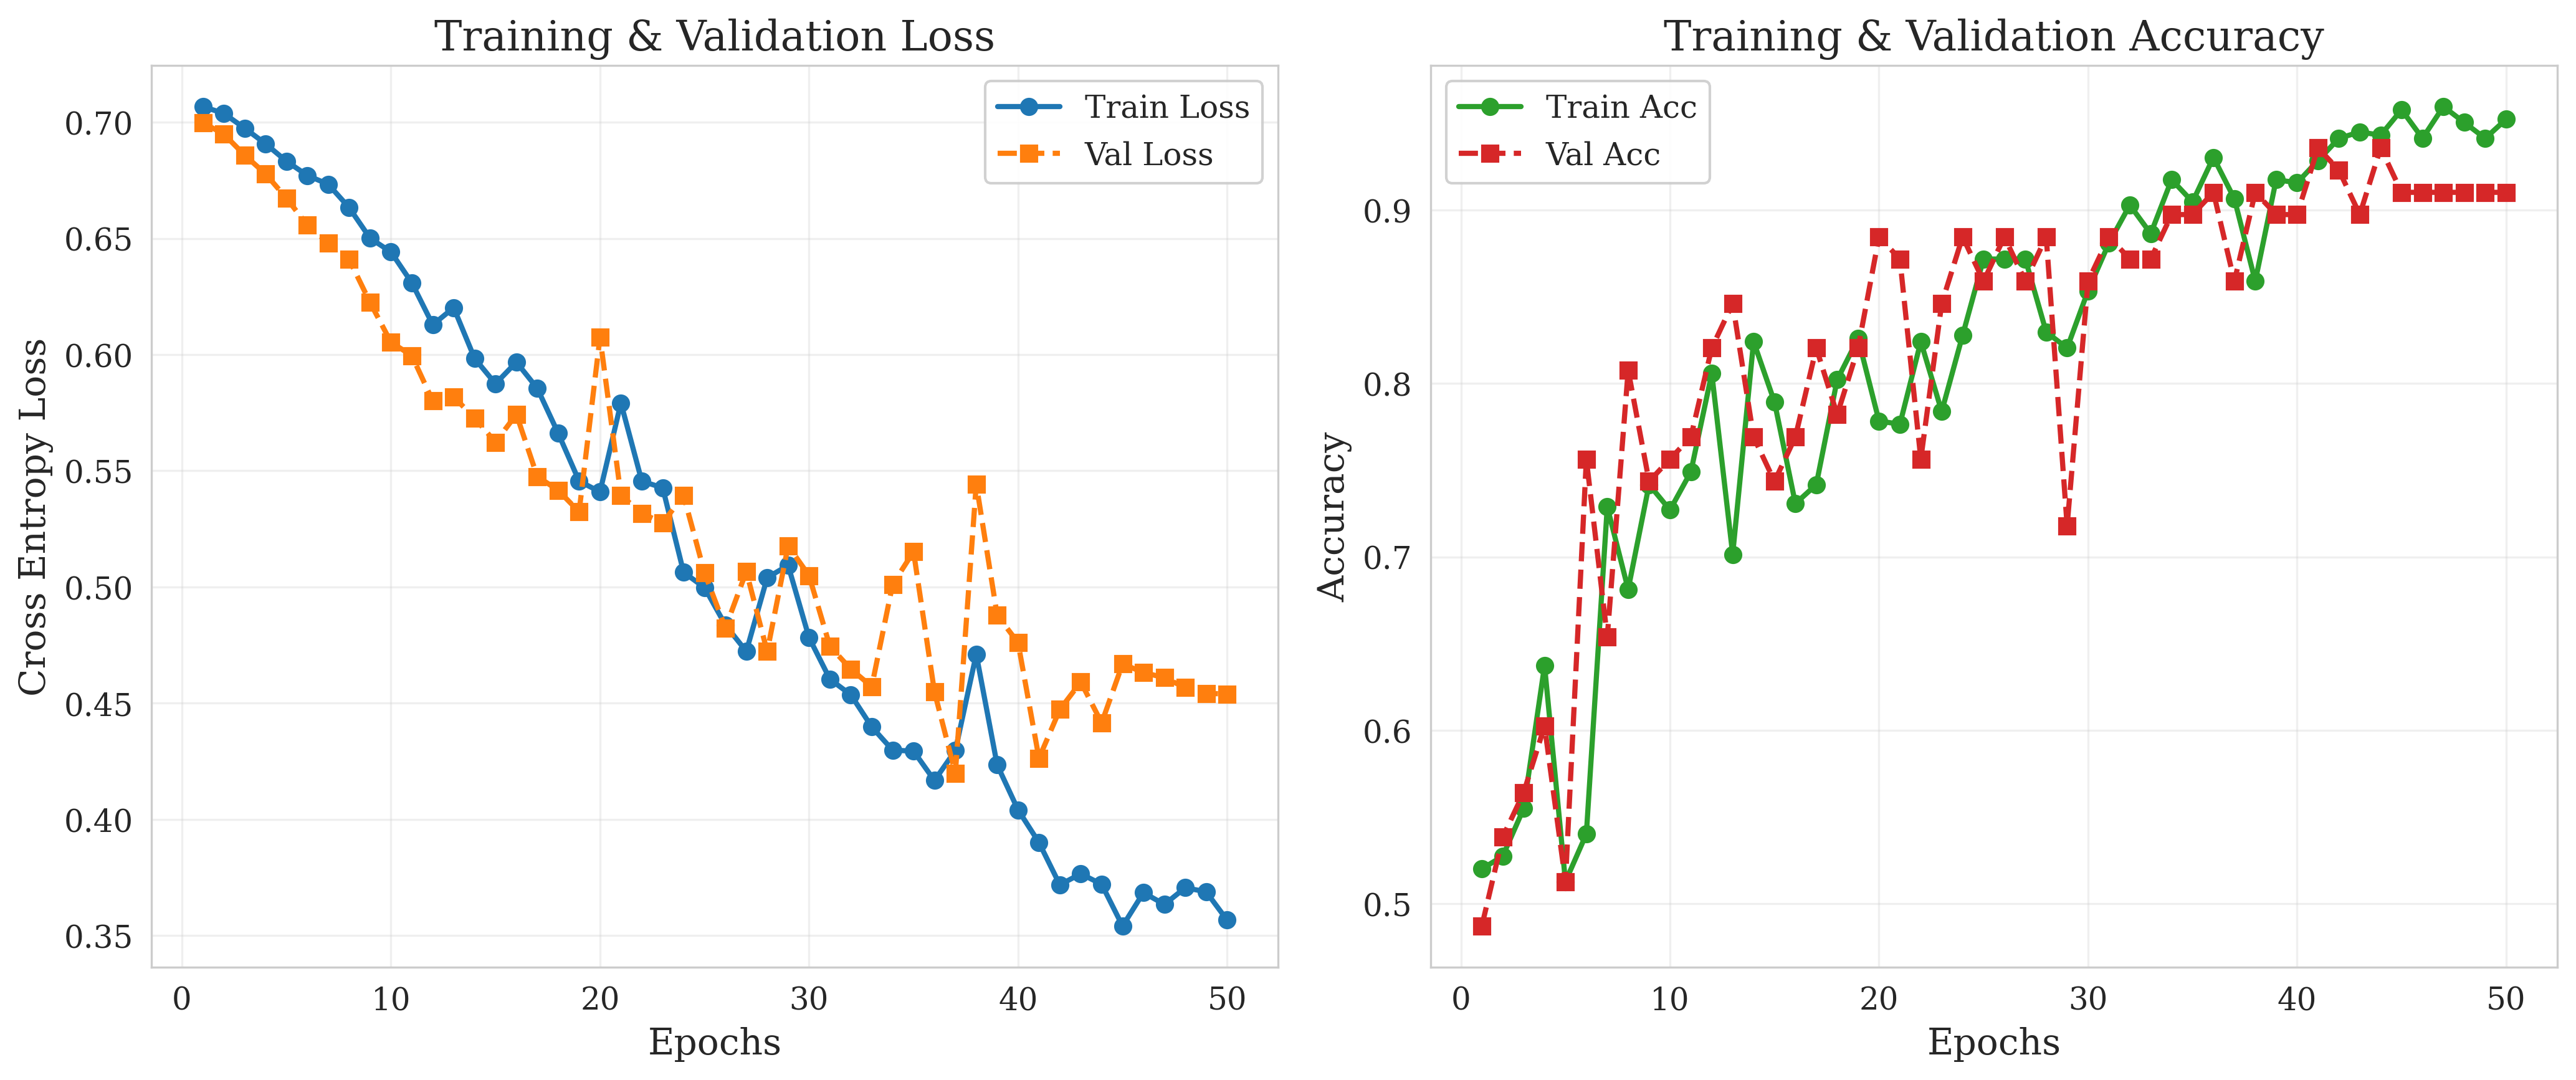

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_2, save_dir='training_plots', model_name='model_quantum_2')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_2 = calculate_metrics(
    model=model_quantum_2_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.9103
⚖️  Balanced Accuracy:    0.8634  (Target Paper)
📈 AUC Score:            0.9641
------------------------------
🔍 Sensitivity (Maligno): 0.7619  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9649



### VQC 8 qubit con Strongly Entangling Layers

In [9]:
# Nuovo circuito (Strongly Entangling)
#@qml.qnode(dev_8, interface="torch")
def circuit_strong(inputs, weights):
    # Embedding dei dati
    n_qubits = inputs.shape[-1]
    custom_angle_embedding(inputs)

    # Layer Variazionale
    # PennyLane gestisce internamente le rotazioni e l'entanglement a lungo raggio.
    # weights ha già la forma corretta (n_layers, n_qubits, 3).
    # ranges=None lascia a PennyLane la scelta migliore dei collegamenti.
    qml.StronglyEntanglingLayers(weights=weights, wires=range(n_qubits))

    # Misura
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [ ]:
vqc_layer_3 = qml.qnn.TorchLayer(circuit_strong, weight_shapes)

In [ ]:
model_quantum_3 = get_quantum_swin_model_arg(vqc_layer_3, n_qubits=8)
params_quantum_3 = list(model_quantum_3.head[1].parameters())
quantum_3_ids = list(map(id, params_quantum_3))

# I parametri classici sono tutto il resto
classical_params_3 = filter(lambda p: id(p) not in quantum_3_ids, model_quantum_3.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_3 = optim.SGD([
    {'params': classical_params_3, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_3,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_3 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_3, mode='min', factor=0.1, patience=3)
loss_fn_quantum_3 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_3_trained, history_quantum_3 = train_pipeline(
    model=model_quantum_3,
    optimizer=optimizer_quantum_3,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_3,
    model_name="model_quantum_3",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_3,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_quantum_3_20260217_121739


Training model_quantum_3:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_3_results.pdf
   🖼️ PNG: training_plots/model_quantum_3_results.png


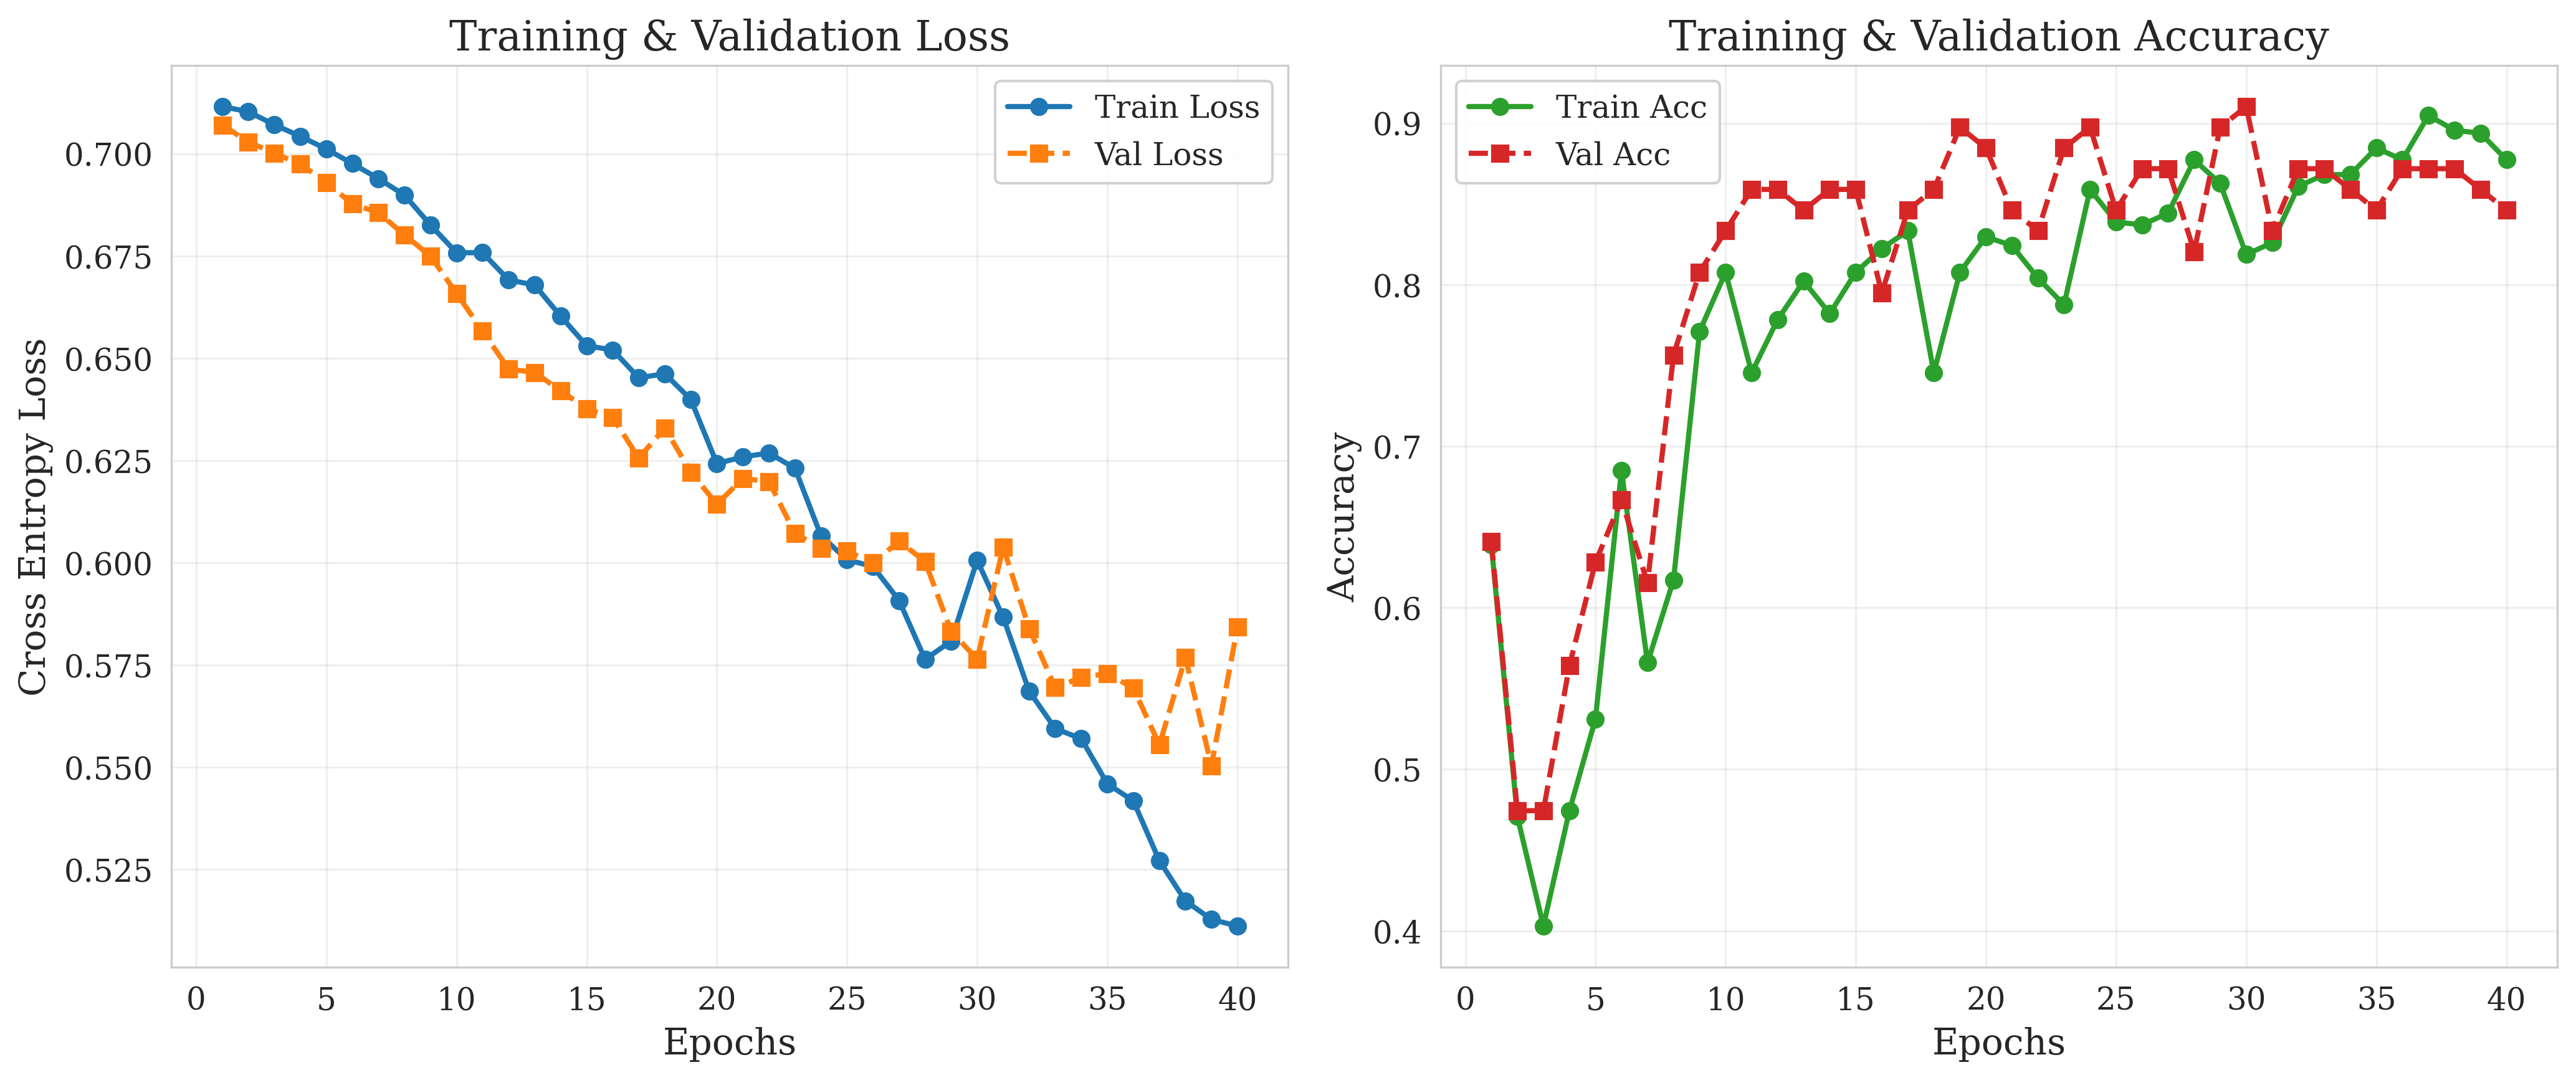

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_3, save_dir='training_plots', model_name='model_quantum_3')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_3 = calculate_metrics(
    model=model_quantum_3_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8462
⚖️  Balanced Accuracy:    0.7444  (Target Paper)
📈 AUC Score:            0.9114
------------------------------
🔍 Sensitivity (Maligno): 0.5238  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9649



### VQC 16 qubit con Strongly Entangling Layers

In [ ]:
def circuit_strong_template(inputs, weights, n_qubits):
    # Embedding dei dati
    custom_angle_embedding(inputs, n_qubits)

    # Layer Variazionale
    # PennyLane gestisce internamente le rotazioni e l'entanglement a lungo raggio.
    # weights ha già la forma corretta (n_layers, n_qubits, 3).
    # ranges=None lascia a PennyLane la scelta migliore dei collegamenti.
    qml.StronglyEntanglingLayers(weights=weights, wires=range(n_qubits))

    # Misura
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [ ]:
n_qubits_4 = 16
dev_16 = qml.device("default.qubit", wires=n_qubits_4)
qnode_4 = qnode_factory(circuit_strong_template, n_qubits_4, dev_16, interface="torch")
weight_shapes_4 = {"weights": (2, n_qubits_4, 3)}
vqc_layer_4 = qml.qnn.TorchLayer(qnode_4, weight_shapes_4)

In [ ]:
model_quantum_4 = get_quantum_swin_model_arg(vqc_layer_4, n_qubits=n_qubits_4)
params_quantum_4 = list(model_quantum_4.head[1].parameters())
quantum_4_ids = list(map(id, params_quantum_4))

# I parametri classici sono tutto il resto
classical_params_4 = filter(lambda p: id(p) not in quantum_4_ids, model_quantum_4.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_4 = optim.SGD([
    {'params': classical_params_4, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_4,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_4 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_4, mode='min', factor=0.1, patience=3)
loss_fn_quantum_4 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_4_trained, history_quantum_4 = train_pipeline(
    model=model_quantum_4,
    optimizer=optimizer_quantum_4,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_4,
    model_name="model_quantum_4",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_4,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_quantum_4_20260217_160337


Training model_quantum_4:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_4_results.pdf
   🖼️ PNG: training_plots/model_quantum_4_results.png


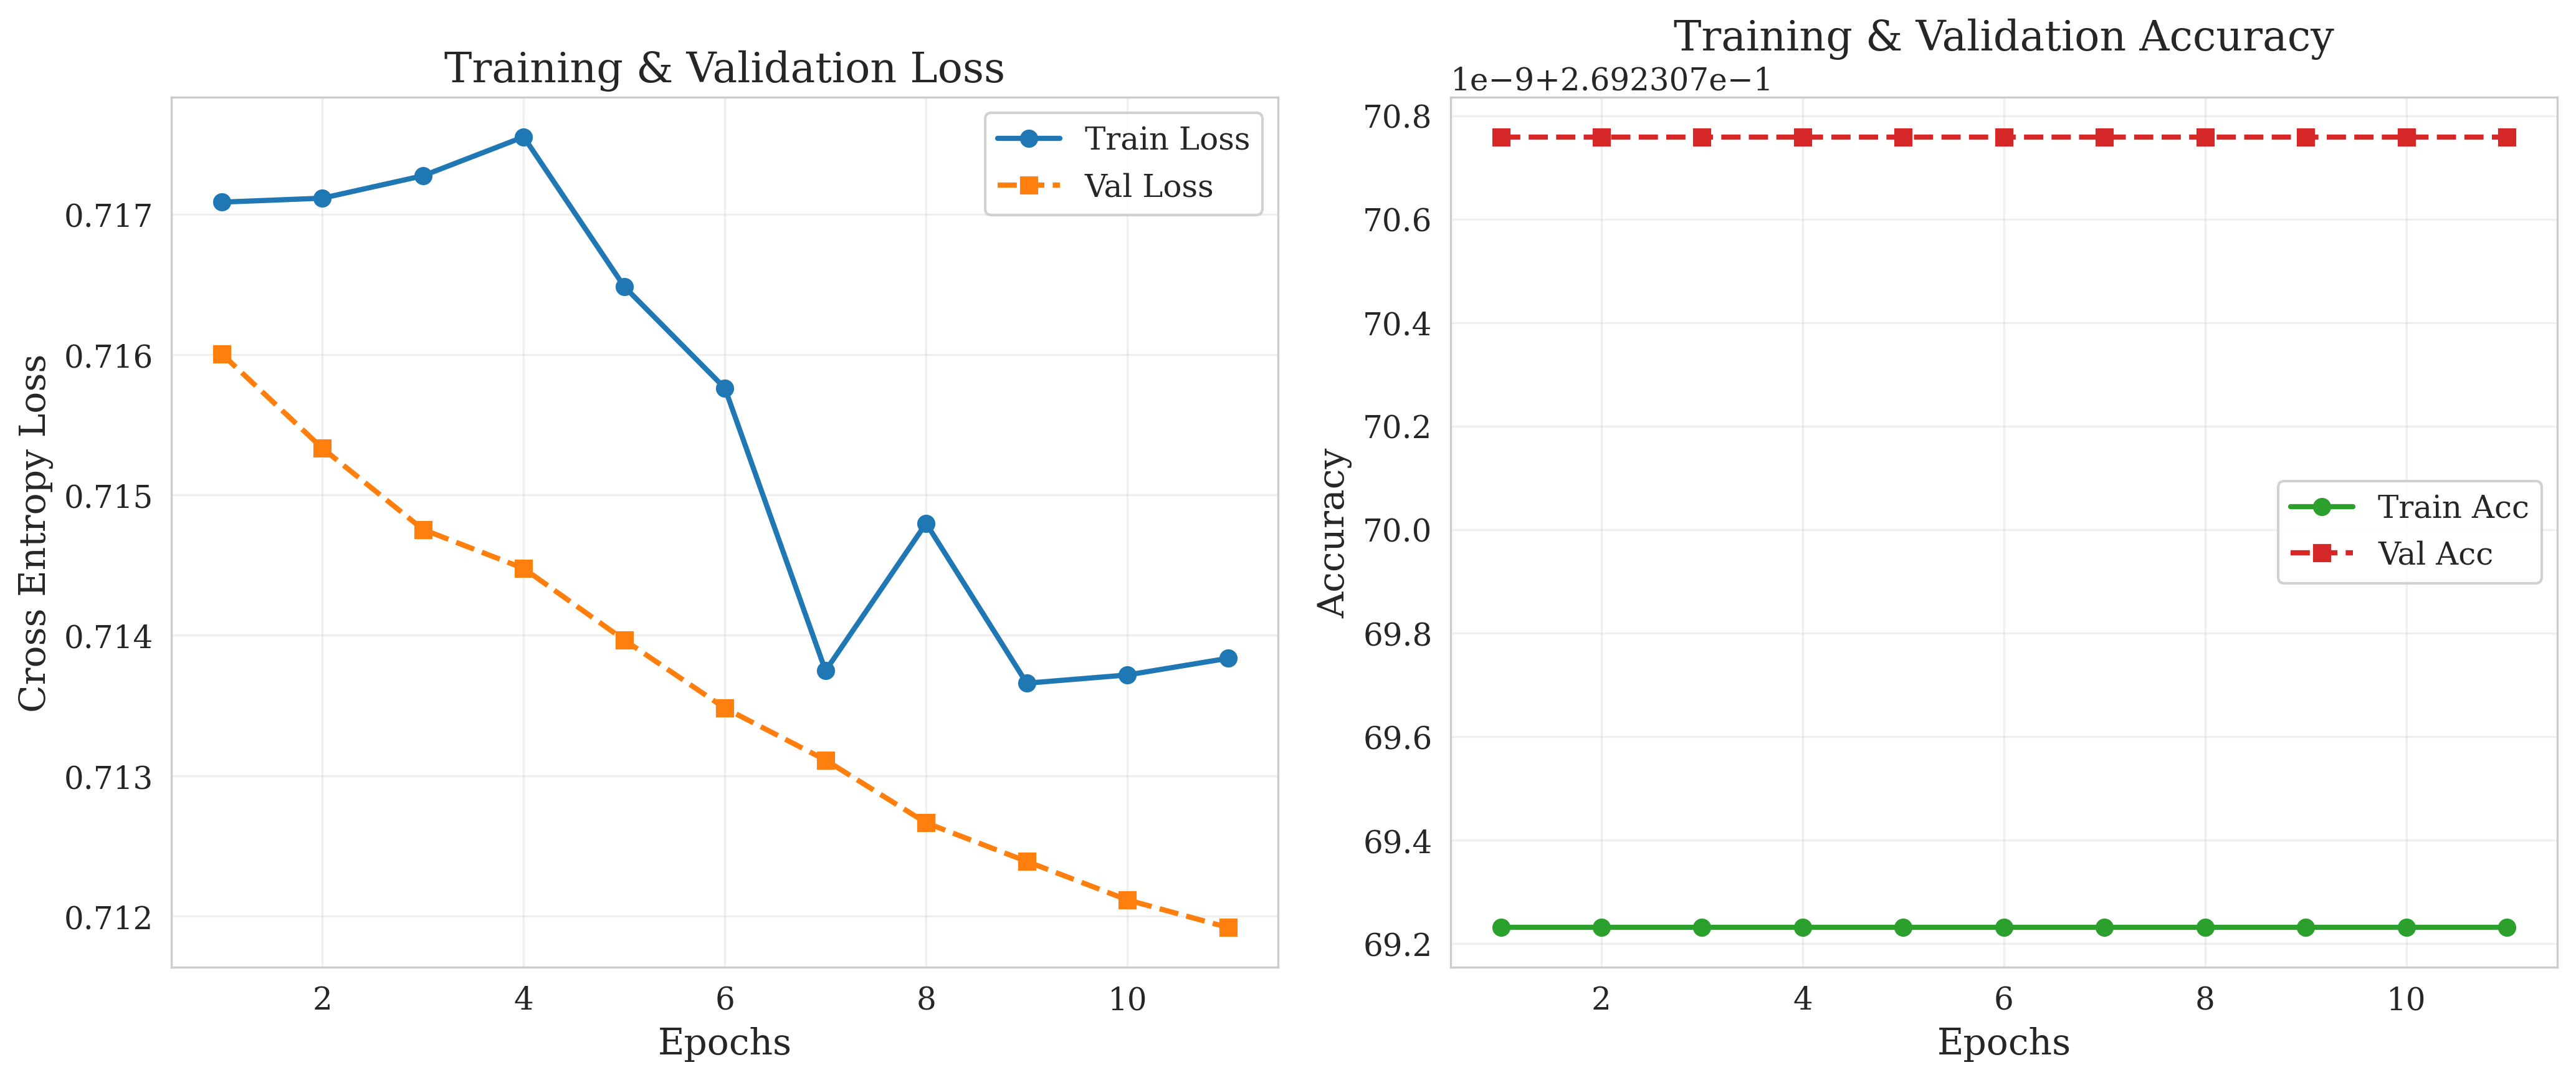

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_4, save_dir='training_plots', model_name='model_quantum_4')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_4 = calculate_metrics(
    model=model_quantum_4_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.2692
⚖️  Balanced Accuracy:    0.5000  (Target Paper)
📈 AUC Score:            0.5272
------------------------------
🔍 Sensitivity (Maligno): 1.0000  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.0000



### VQC a 8 qubit con Data Reuploading

In [ ]:
# Embedding Dinamico (Deve accettare n_qubits)
def custom_angle_embedding_dynamic(inputs, n_qubits):
    x_prime = torch.atan(inputs)
    for i in range(n_qubits):
        qml.Hadamard(wires=i)
        angle = x_prime[..., i]
        qml.RY(angle, wires=i)
        qml.RZ(angle**2, wires=i)

# IL CIRCUITO RE-UPLOADING
def circuit_reupload_template(inputs, weights, n_qubits):
    """
    Implementa Data Re-uploading

    """
    # weights ha shape (n_layers, n_qubits, 3)
    n_layers = weights.shape[0]

    # Ciclo su ogni strato (Layer)
    for l in range(n_layers):
        # Ricarichiamo i dati (Data Re-uploading)
        #    Questo "rinfresca" la memoria del circuito sui dati di input
        custom_angle_embedding_dynamic(inputs, n_qubits)


        for q in range(n_qubits):
            # Estraiamo i 3 parametri dal tensore dei pesi
            # weights[l, q] è un vettore di 3 numeri: [theta, phi, lambda]
            theta, phi, lam = weights[l, q]

            # Applichiamo la porta
            qml.U3(theta, phi, lam, wires=q)

        # SOTTO-FASE B: Entanglement (Connessione)
        # Porte CZ a catena
        for q in range(n_qubits - 1): # Fino al penultimo
             qml.CZ(wires=[q, q + 1])


    # Misura finale
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [ ]:
n_qubits_5 = 8
dev_5 = qml.device("default.qubit", wires=n_qubits_5)
qnode_5 = qnode_factory(circuit_reupload_template, n_qubits_5, dev_5, interface="torch")
weight_shapes_5 = {"weights": (2, n_qubits_5, 3)}
vqc_layer_5 = qml.qnn.TorchLayer(qnode_5, weight_shapes_5)

In [ ]:
model_quantum_5 = get_quantum_swin_model_arg(vqc_layer_5, n_qubits=n_qubits_5)
params_quantum_5 = list(model_quantum_5.head[1].parameters())
quantum_5_ids = list(map(id, params_quantum_5))

# I parametri classici sono tutto il resto
classical_params_5 = filter(lambda p: id(p) not in quantum_5_ids, model_quantum_5.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_5 = optim.SGD([
    {'params': classical_params_5, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_5,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_5 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_5, mode='min', factor=0.1, patience=3)
loss_fn_quantum_5 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_5_trained, history_quantum_5 = train_pipeline(
    model=model_quantum_5,
    optimizer=optimizer_quantum_5,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_5,
    model_name="model_quantum_5",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_5,
    save_best_model=True,
    drive_dir=drive_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/drive/MyDrive/QML/models/model_quantum_5_20260217_164940


Training model_quantum_5:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_5_results.pdf
   🖼️ PNG: training_plots/model_quantum_5_results.png


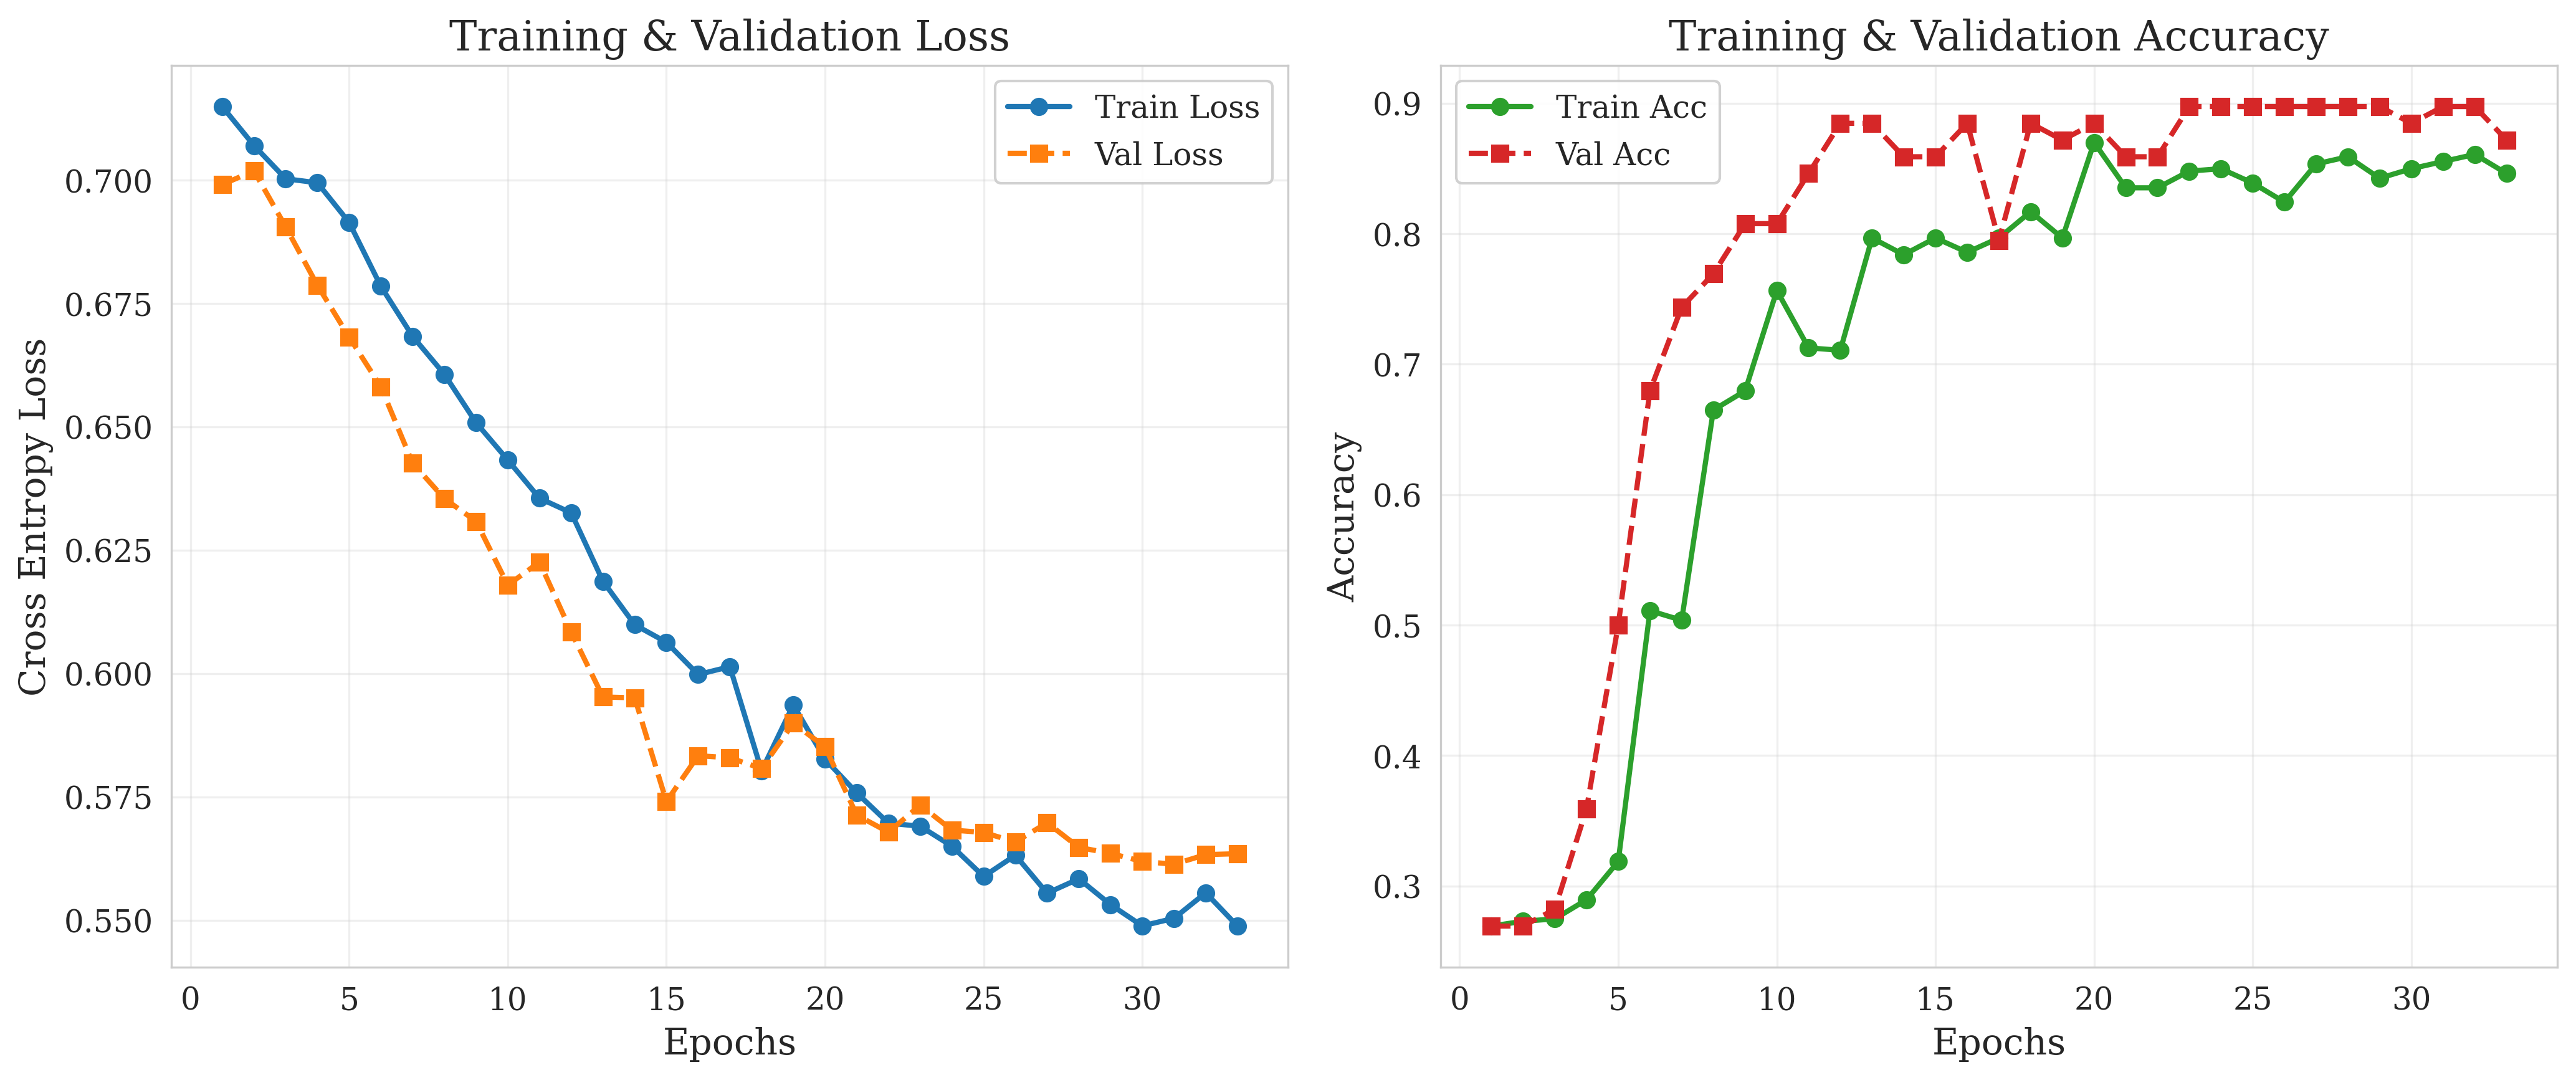

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_5, save_dir='training_plots', model_name='model_quantum_5')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_5 = calculate_metrics(
    model=model_quantum_5_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8718
⚖️  Balanced Accuracy:    0.8221  (Target Paper)
📈 AUC Score:            0.8972
------------------------------
🔍 Sensitivity (Maligno): 0.7143  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9298



### VQC a 16 qubit con Data Reuploading

In [ ]:
n_qubits_6 = 16
dev_6 = qml.device("default.qubit", wires=n_qubits_6)
qnode_6 = qnode_factory(circuit_reupload_template, n_qubits_6, dev_6, interface="torch")
weight_shapes_6 = {"weights": (2, n_qubits_6, 3)}
vqc_layer_6 = qml.qnn.TorchLayer(qnode_6, weight_shapes_6)

In [ ]:
model_quantum_6 = get_quantum_swin_model_arg(vqc_layer_6, n_qubits=n_qubits_6)
params_quantum_6 = list(model_quantum_6.head[1].parameters())
quantum_6_ids = list(map(id, params_quantum_6))

# I parametri classici sono tutto il resto
classical_params_6 = filter(lambda p: id(p) not in quantum_6_ids, model_quantum_6.parameters())

# Definiamo l'ottimizzatore con LR differenziati
optimizer_quantum_6 = optim.SGD([
    {'params': classical_params_6, 'lr': 0.0004},  # LR Classico
    {'params': params_quantum_6,   'lr': 0.004}    # LR Quantum (10x più alto)
], momentum=0.9, weight_decay=1e-4)

In [ ]:
scheduler_quantum_6 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_6, mode='min', factor=0.1, patience=3)
loss_fn_quantum_6 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

model_quantum_6_trained, history_quantum_6 = train_pipeline(
    model=model_quantum_6,
    optimizer=optimizer_quantum_6,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn_quantum_6,
    model_name="model_quantum_6",
    epochs=50,
    patience=10,
    early_stopping=True,
    scheduler=scheduler_quantum_6,
    save_best_model=True,
    drive_dir=local_path_models,
    wandb_flag=False,
    verbose=True
)

I modelli verranno salvati in: /content/models/model_quantum_6_20260218_085758


Training model_quantum_6:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_6_results.pdf
   🖼️ PNG: training_plots/model_quantum_6_results.png


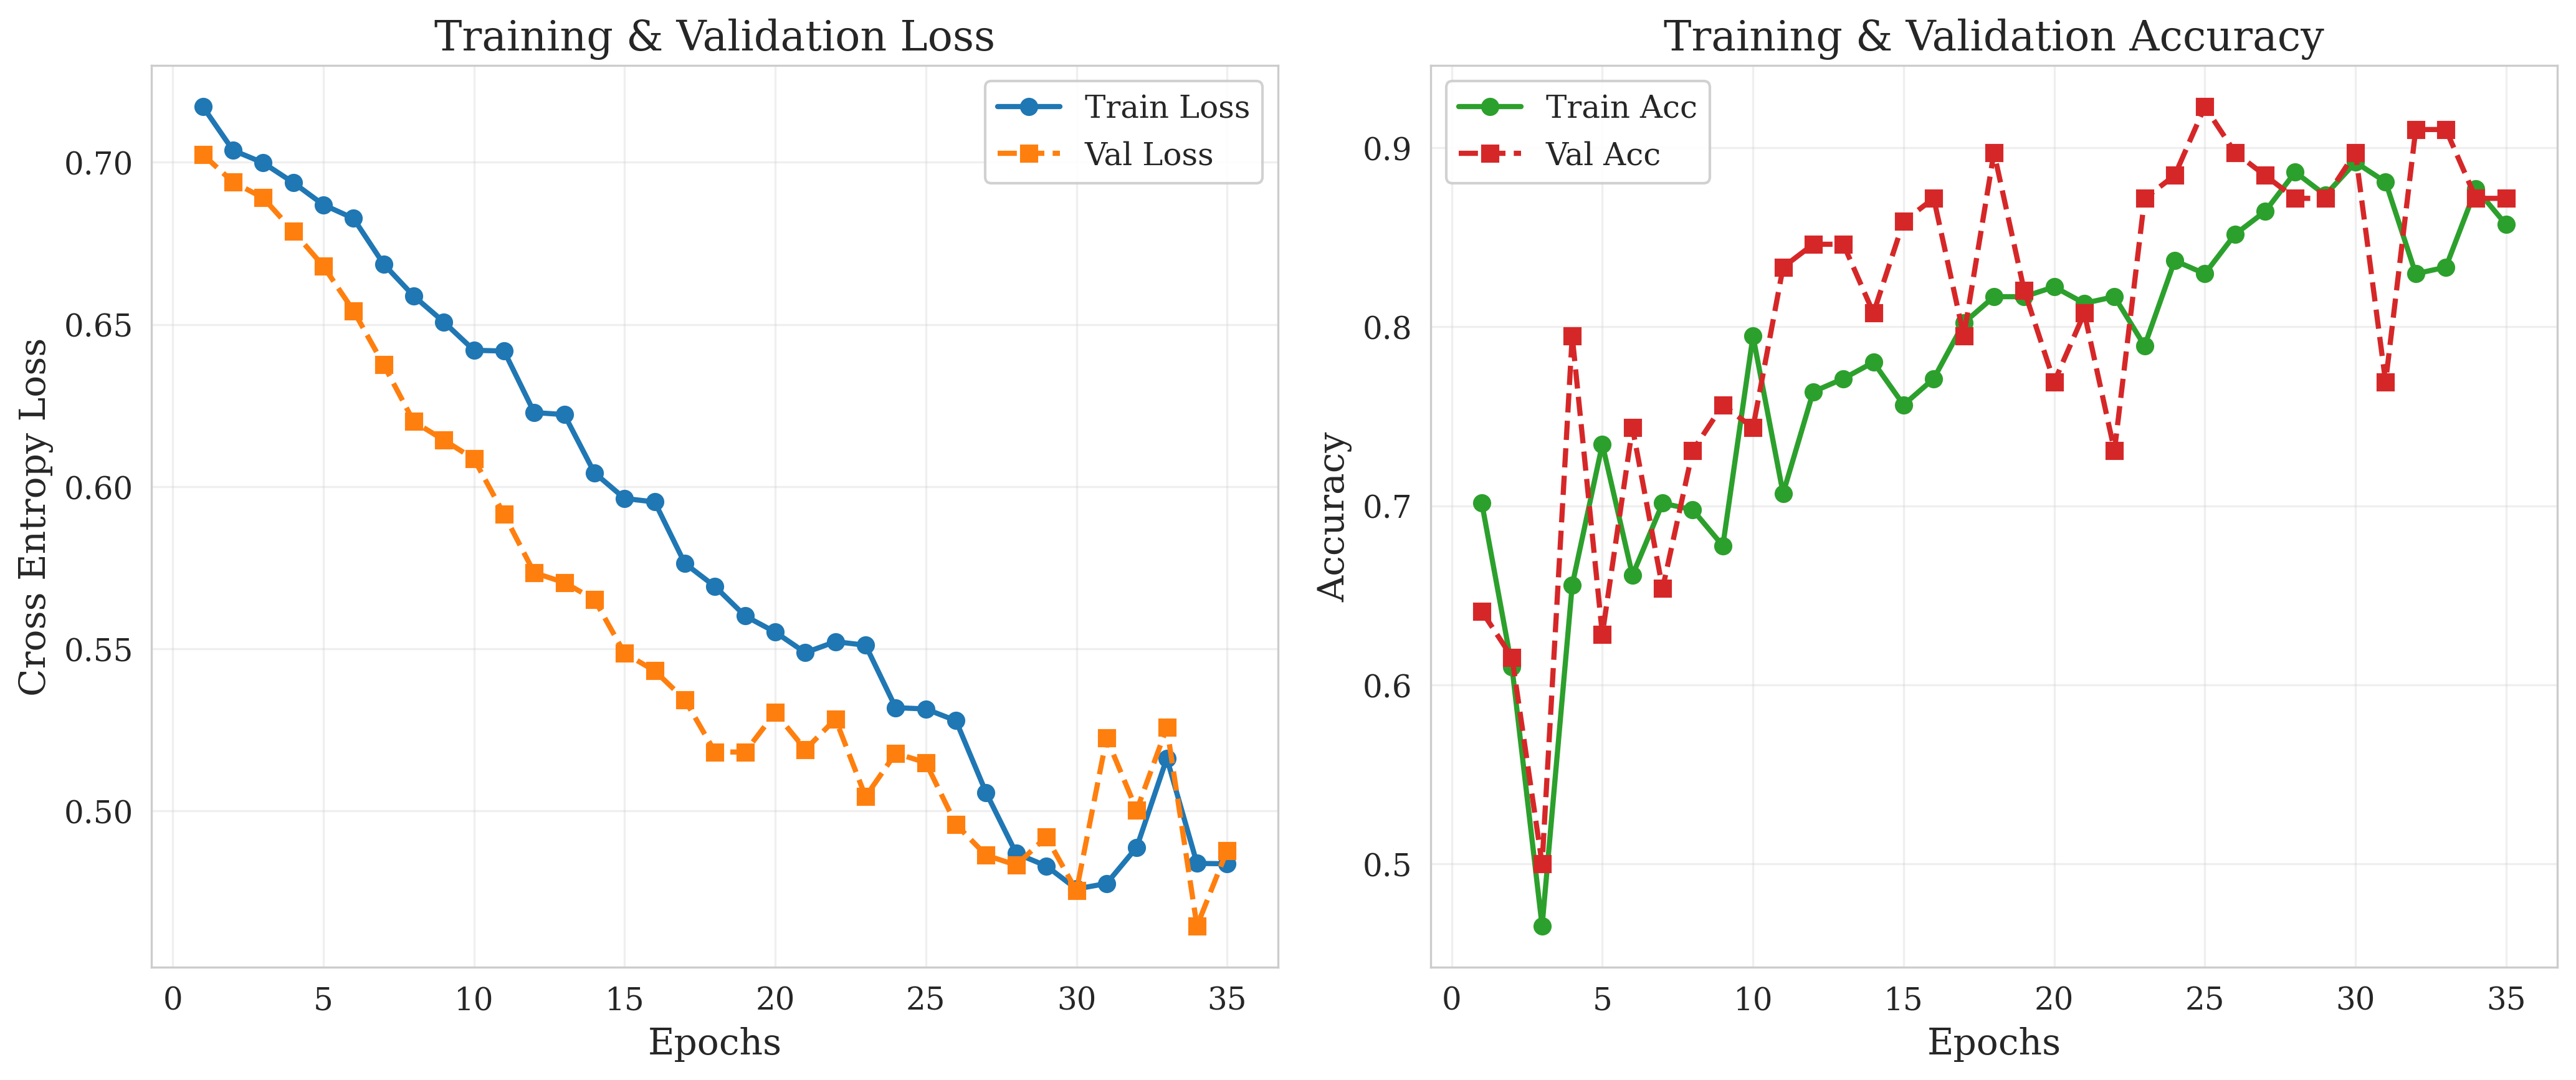

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_6, save_dir='training_plots', model_name='model_quantum_6')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_6 = calculate_metrics(
    model=model_quantum_6_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8718
⚖️  Balanced Accuracy:    0.8221  (Target Paper)
📈 AUC Score:            0.9457
------------------------------
🔍 Sensitivity (Maligno): 0.7143  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9298



### VQC a 16 qubit con Data Reuploading: ottimizzazioni per aumentare la stabilità

In [19]:
def custom_angle_embedding_dynamic_stab(inputs, n_qubits):
    x_prime = torch.atan(inputs)
    for i in range(n_qubits):
        # RIMOSSO qml.Hadamard da qui
        angle = x_prime[..., i]
        qml.RY(angle, wires=i)
        qml.RZ(angle**2, wires=i)

def circuit_reupload_template_stab(inputs, weights, n_qubits):
    n_layers = weights.shape[0]

    # PREPARAZIONE INIZIALE (Una sola volta per tutto il circuito)
    for i in range(n_qubits):
        qml.Hadamard(wires=i)

    # CICLO RE-UPLOADING
    for l in range(n_layers):
        # Inserimento dati
        custom_angle_embedding_dynamic_stab(inputs, n_qubits)

        # Rotazioni Variazionali
        for q in range(n_qubits):
            theta, phi, lam = weights[l, q]
            qml.U3(theta, phi, lam, wires=q)

        # Entanglement
        for q in range(n_qubits - 1):
            qml.CZ(wires=[q, q + 1])

    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [20]:
seed_7 = 1000

In [ ]:
with LocalSeed(seed_7):
  n_qubits_7 = 16
  dev_7 = qml.device("default.qubit", wires=n_qubits_7)
  qnode_7 = qnode_factory(circuit_reupload_template_stab, n_qubits_7, dev_7, interface="torch")
  weight_shapes_7 = {"weights": (2, n_qubits_7, 3)}
  vqc_layer_7 = qml.qnn.TorchLayer(qnode_7, weight_shapes_7)
  with torch.no_grad():
      for param in vqc_layer_7.parameters():
          param.uniform_(-0.01, 0.01)
  model_quantum_7 = get_quantum_swin_model_arg(vqc_layer_7, n_qubits=n_qubits_7)
  params_quantum_7 = list(model_quantum_7.head[1].parameters())
  quantum_7_ids = list(map(id, params_quantum_7))

  # I parametri classici sono tutto il resto
  classical_params_7 = filter(lambda p: id(p) not in quantum_7_ids, model_quantum_7.parameters())

  # Definiamo l'ottimizzatore con LR differenziati
  optimizer_quantum_7 = optim.SGD([
      {'params': classical_params_7, 'lr': 0.0004},  # LR Classico
      {'params': params_quantum_7,   'lr': 0.004}    # LR Quantum (10x più alto)
  ], momentum=0.9, weight_decay=1e-4)
  scheduler_quantum_7 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_7, mode='min', factor=0.1, patience=3)
  loss_fn_quantum_7 = nn.CrossEntropyLoss(weight=class_weights_classic_1, label_smoothing=0.1)

  model_quantum_7_trained, history_quantum_7 = train_pipeline(
      model=model_quantum_7,
      optimizer=optimizer_quantum_7,
      train_loader=train_loader,
      val_loader=val_loader,
      loss_fn=loss_fn_quantum_7,
      model_name="model_quantum_7",
      epochs=50,
      patience=10,
      early_stopping=True,
      scheduler=scheduler_quantum_7,
      save_best_model=True,
      drive_dir=local_path_models,
      wandb_flag=False,
      verbose=True
  )

I modelli verranno salvati in: /content/models/model_quantum_7_20260218_112529


Training model_quantum_7:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_7_results.pdf
   🖼️ PNG: training_plots/model_quantum_7_results.png


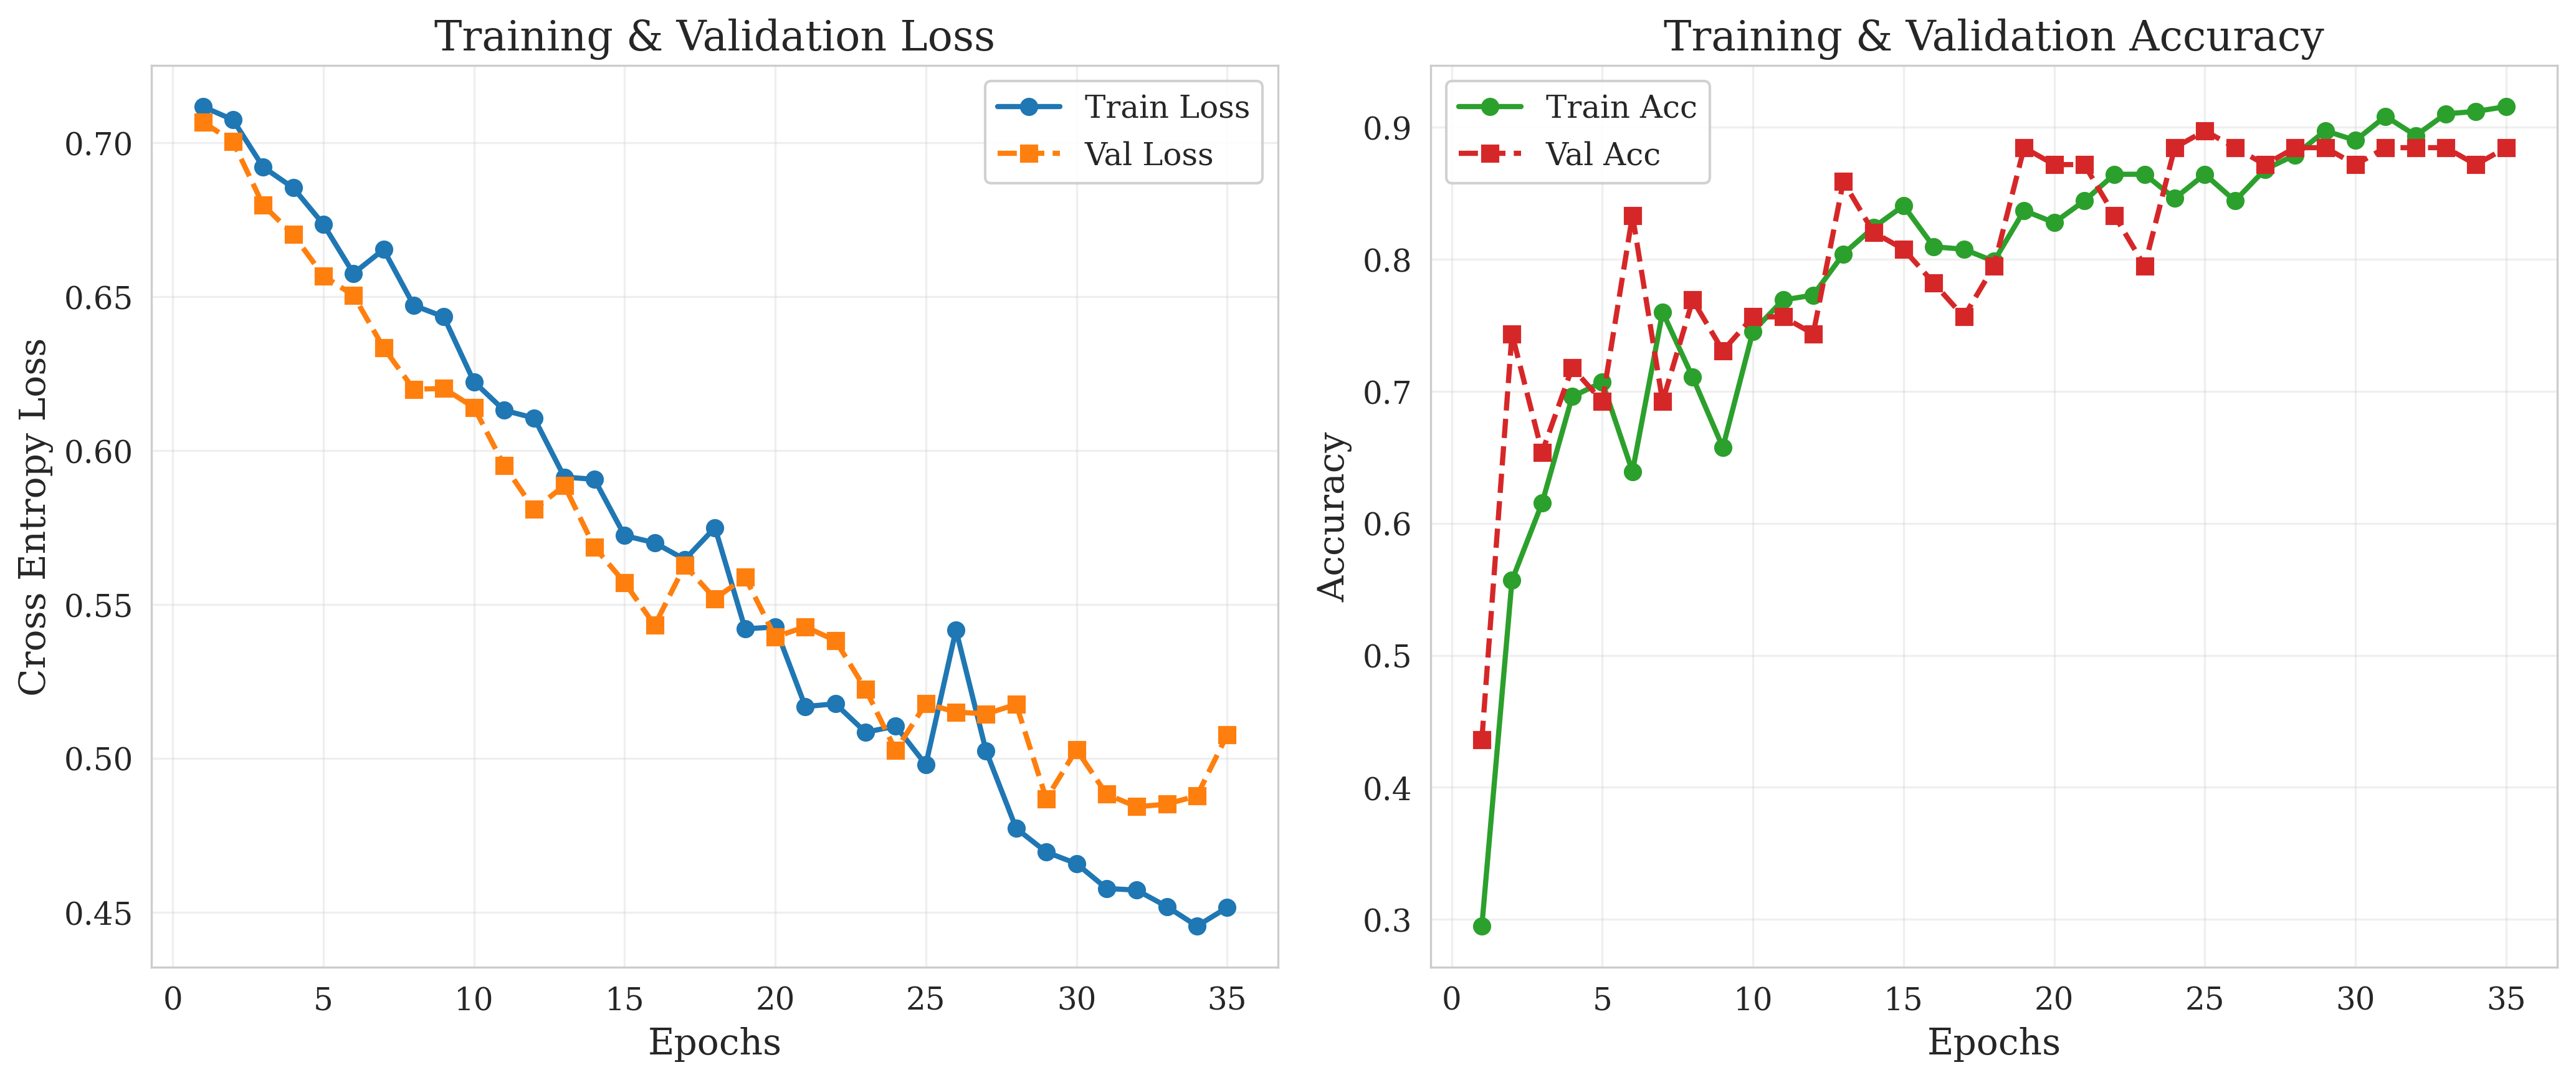

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_7, save_dir='training_plots', model_name='model_quantum_7')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_7 = calculate_metrics(
    model=model_quantum_7_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8846
⚖️  Balanced Accuracy:    0.8308  (Target Paper)
📈 AUC Score:            0.9165
------------------------------
🔍 Sensitivity (Maligno): 0.7143  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9474



### Potenziamenti ulteriori a VQC 16 con data reuploading

In [21]:
def circuit_reupload_template_stab_en(inputs, weights, n_qubits):
    n_layers = weights.shape[0]

    # PREPARAZIONE INIZIALE (Una sola volta per tutto il circuito)
    for i in range(n_qubits):
        qml.Hadamard(wires=i)

    # CICLO RE-UPLOADING
    for l in range(n_layers):
        # Inserimento dati
        custom_angle_embedding_dynamic_stab(inputs, n_qubits)

        # Rotazioni Variazionali
        for q in range(n_qubits):
            theta, phi, lam = weights[l, q]
            qml.U3(theta, phi, lam, wires=q)

        # Entanglement
        for q in range(n_qubits - 1):
            qml.CZ(wires=[q, q + 1])

        if n_qubits > 2:
            qml.CZ(wires=[n_qubits - 1, 0])

    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

In [22]:
class_weights_aggressive = torch.tensor([4.0, 1.0]).to("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# salto il numero 8 nella numerazione per non confondermi con gli 8 qubit
with LocalSeed(seed_7):
  n_qubits_9 = 16
  dev_9 = qml.device("default.qubit", wires=n_qubits_9)
  qnode_9 = qnode_factory(circuit_reupload_template_stab_en, n_qubits_9, dev_9, interface="torch")
  weight_shapes_9 = {"weights": (2, n_qubits_9, 3)}
  vqc_layer_9 = qml.qnn.TorchLayer(qnode_9, weight_shapes_9)
  with torch.no_grad():
      for param in vqc_layer_9.parameters():
          param.uniform_(-0.01, 0.01)
  model_quantum_9 = get_quantum_swin_model_arg(vqc_layer_9, n_qubits=n_qubits_9)
  params_quantum_9 = list(model_quantum_9.head[1].parameters())
  quantum_9_ids = list(map(id, params_quantum_9))

  # I parametri classici sono tutto il resto
  classical_params_9 = filter(lambda p: id(p) not in quantum_9_ids, model_quantum_9.parameters())

  # Definiamo l'ottimizzatore con LR differenziati
  optimizer_quantum_9 = optim.SGD([
      {'params': classical_params_9, 'lr': 0.0004},  # LR Classico
      {'params': params_quantum_9,   'lr': 0.004}    # LR Quantum (10x più alto)
  ], momentum=0.9, weight_decay=1e-4)
  scheduler_quantum_9 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_9, mode='min', factor=0.1, patience=3)
  loss_fn_quantum_9 = nn.CrossEntropyLoss(weight=class_weights_aggressive, label_smoothing=0.1)

  model_quantum_9_trained, history_quantum_9 = train_pipeline(
      model=model_quantum_9,
      optimizer=optimizer_quantum_9,
      train_loader=train_loader,
      val_loader=val_loader,
      loss_fn=loss_fn_quantum_9,
      model_name="model_quantum_9",
      epochs=50,
      patience=10,
      early_stopping=True,
      scheduler=scheduler_quantum_9,
      save_best_model=True,
      drive_dir=local_path_models,
      wandb_flag=False,
      verbose=True
  )

I modelli verranno salvati in: /content/models/model_quantum_9_20260218_120643


Training model_quantum_9:   0%|                                                                               …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_9_results.pdf
   🖼️ PNG: training_plots/model_quantum_9_results.png


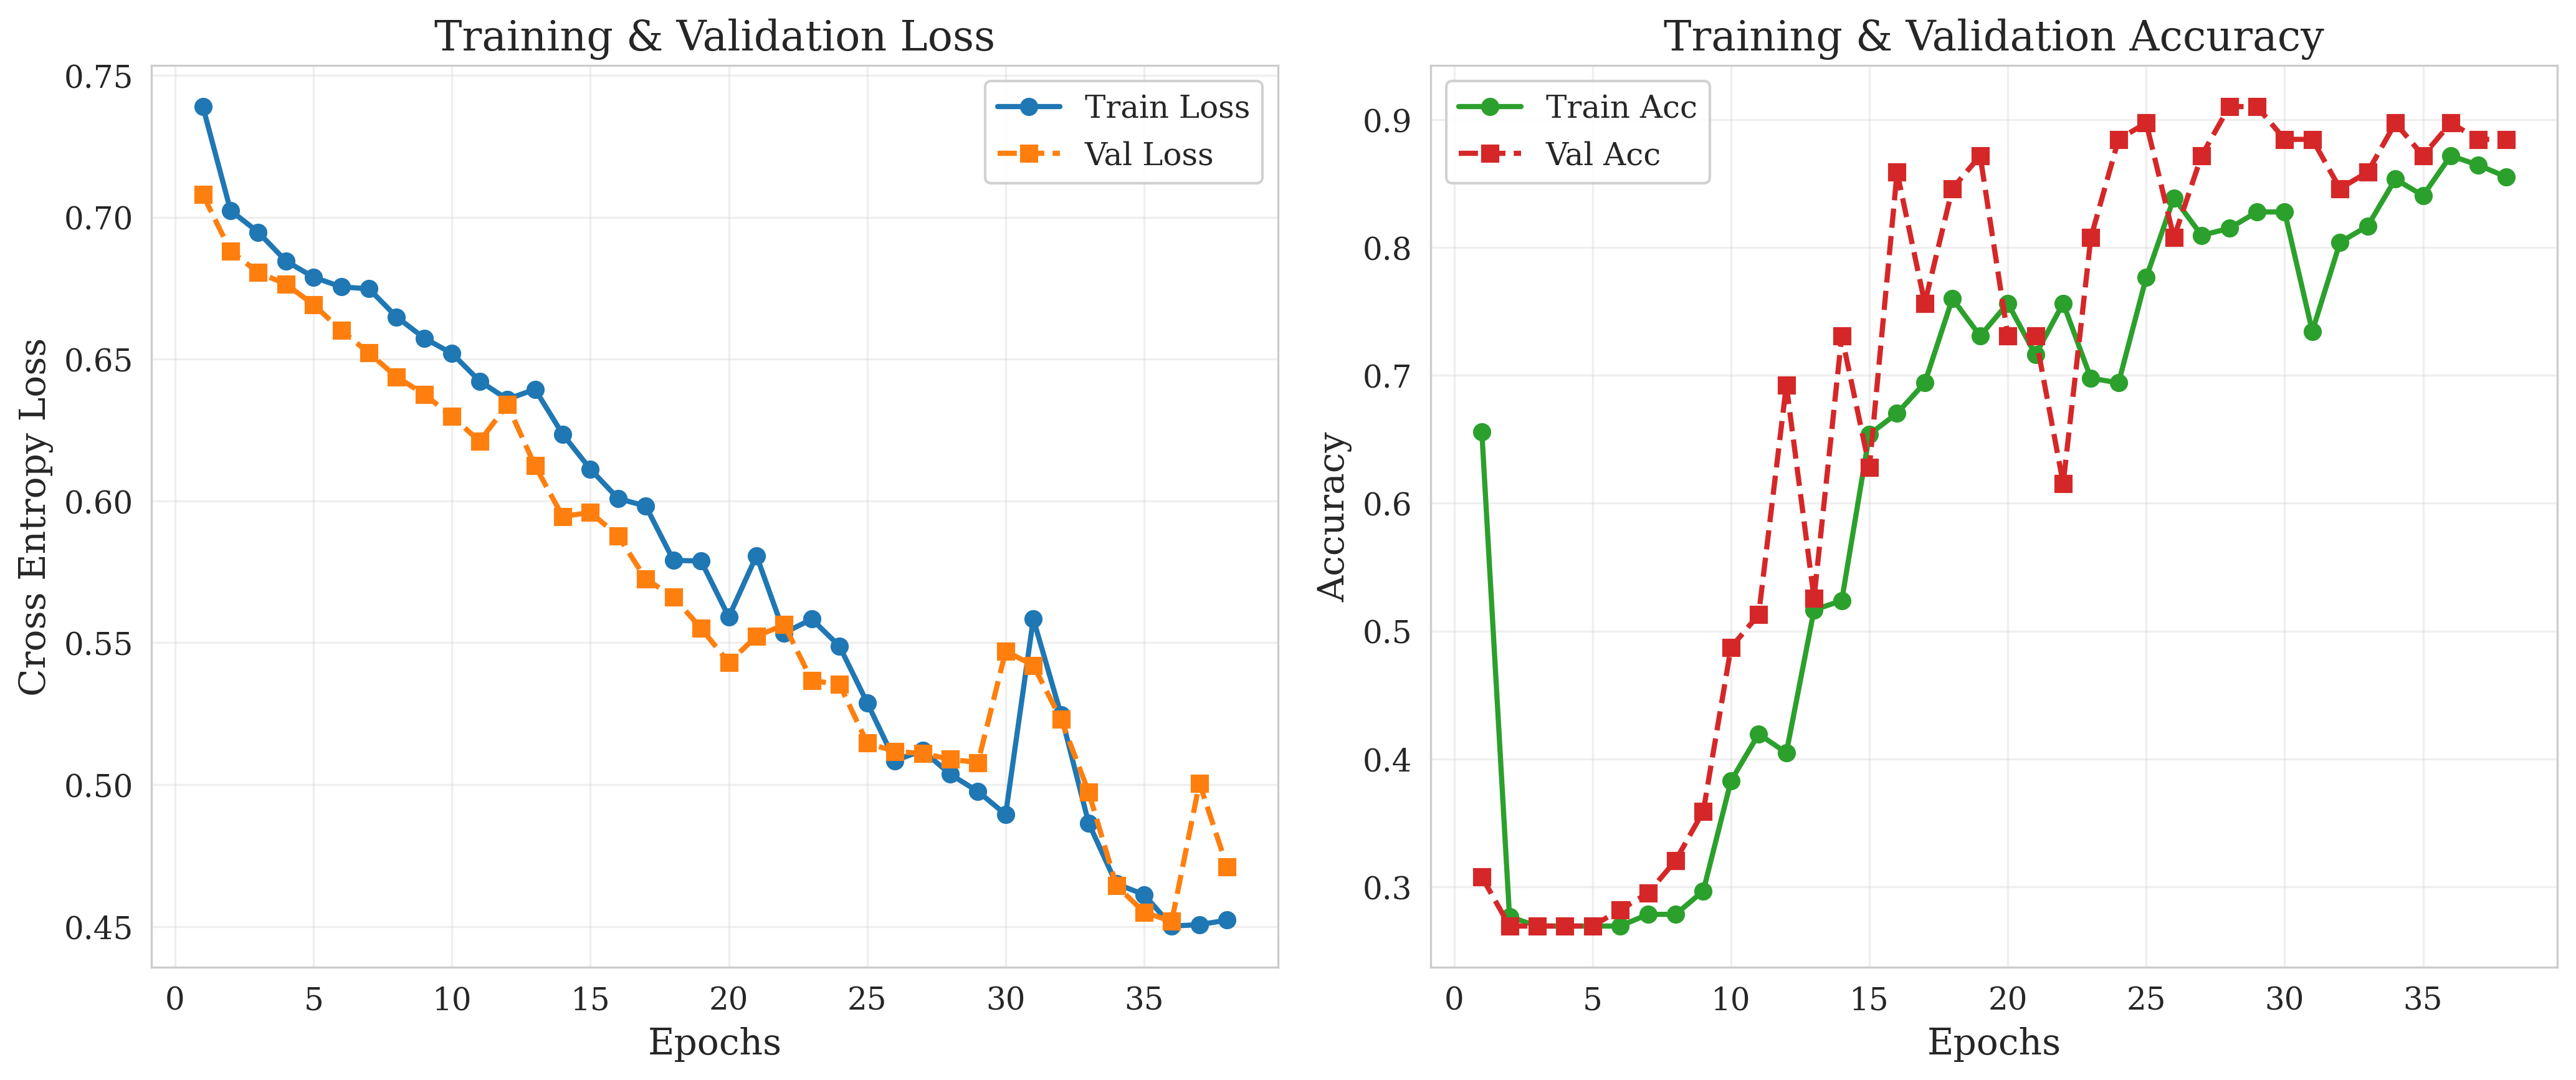

In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_9, save_dir='training_plots', model_name='model_quantum_9')

In [ ]:
# Chiamata alla funzione generica
val_metrics_quantum_9 = calculate_metrics(
    model=model_quantum_9_trained,
    dataloader=val_loader,          # Il Validation Set
    device="cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set (BreastMNIST)"
)

🏥 Avvio Valutazione su: Validation Set (BreastMNIST)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (BreastMNIST)
✅ Accuracy Standard:    0.8846
⚖️  Balanced Accuracy:    0.8459  (Target Paper)
📈 AUC Score:            0.9114
------------------------------
🔍 Sensitivity (Maligno): 0.7619  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.9298



### Scaling dell'output per migliorare la confidenza del modello

In [23]:
class ScaledVQC(nn.Module):
    """Sblocca i valori di aspettazione [-1, 1] per la CrossEntropyLoss."""
    def __init__(self, q_layer, num_qubits=16):
        super().__init__()
        self.q_layer = q_layer
        # Un moltiplicatore addestrabile inizializzato a 5.0 per espandere i logits
        self.scaler = nn.Parameter(torch.ones(num_qubits) * 5.0)

    def forward(self, x):
        # Moltiplica l'output [-1, 1] per lo scaler, permettendo valori come [-5, 5]
        return self.q_layer(x) * self.scaler

In [ ]:
with LocalSeed(seed_7):
    n_qubits_10 = 16
    dev_10 = qml.device("default.qubit", wires=n_qubits_10)
    qnode_10 = qnode_factory(circuit_reupload_template_stab_en, n_qubits_10, dev_10, interface="torch")


    weight_shapes_10 = {"weights": (2, n_qubits_10, 3)}
    vqc_base_10 = qml.qnn.TorchLayer(qnode_10, weight_shapes_10)

    with torch.no_grad():
        for param in vqc_base_10.parameters():
            param.uniform_(-0.01, 0.01)

    # AVVOLGIAMO IL VQC NELLO SCALER
    vqc_layer_10 = ScaledVQC(vqc_base_10, num_qubits=n_qubits_10)

    model_quantum_10 = get_quantum_swin_model_arg(vqc_layer_10, n_qubits=n_qubits_10)

    params_quantum_10 = list(model_quantum_10.head[1].parameters())
    quantum_10_ids = list(map(id, params_quantum_10))

    classical_params_10 = filter(lambda p: id(p) not in quantum_10_ids, model_quantum_10.parameters())

    optimizer_quantum_10 = optim.SGD([
        {'params': classical_params_10, 'lr': 0.0004},
        {'params': params_quantum_10,   'lr': 0.004}
    ], momentum=0.9, weight_decay=1e-4)

    scheduler_quantum_10 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_quantum_10, mode='min', factor=0.1, patience=3)
    loss_fn_quantum_10 = nn.CrossEntropyLoss(weight=class_weights_aggressive, label_smoothing=0.1)

    model_quantum_10_trained, history_quantum_10 = train_pipeline(
        model=model_quantum_10,
        optimizer=optimizer_quantum_10,
        train_loader=train_loader,
        val_loader=val_loader,
        loss_fn=loss_fn_quantum_10,
        model_name="model_quantum_10",
        epochs=50,
        patience=10,
        early_stopping=True,
        scheduler=scheduler_quantum_10,
        save_best_model=False,
        drive_dir=local_path_models,
        wandb_flag=False,
        verbose=True
    )


I modelli verranno salvati in: /content/models/model_quantum_10_20260218_151538


Training model_quantum_10:   0%|                                                                              …

[Early Stopping] Nessun miglioramento per 10 epoche.



📊 Generazione Grafici...
✅ Grafici salvati in alta risoluzione in: training_plots
   📄 PDF: training_plots/model_quantum_10_results.pdf
   🖼️ PNG: training_plots/model_quantum_10_results.png


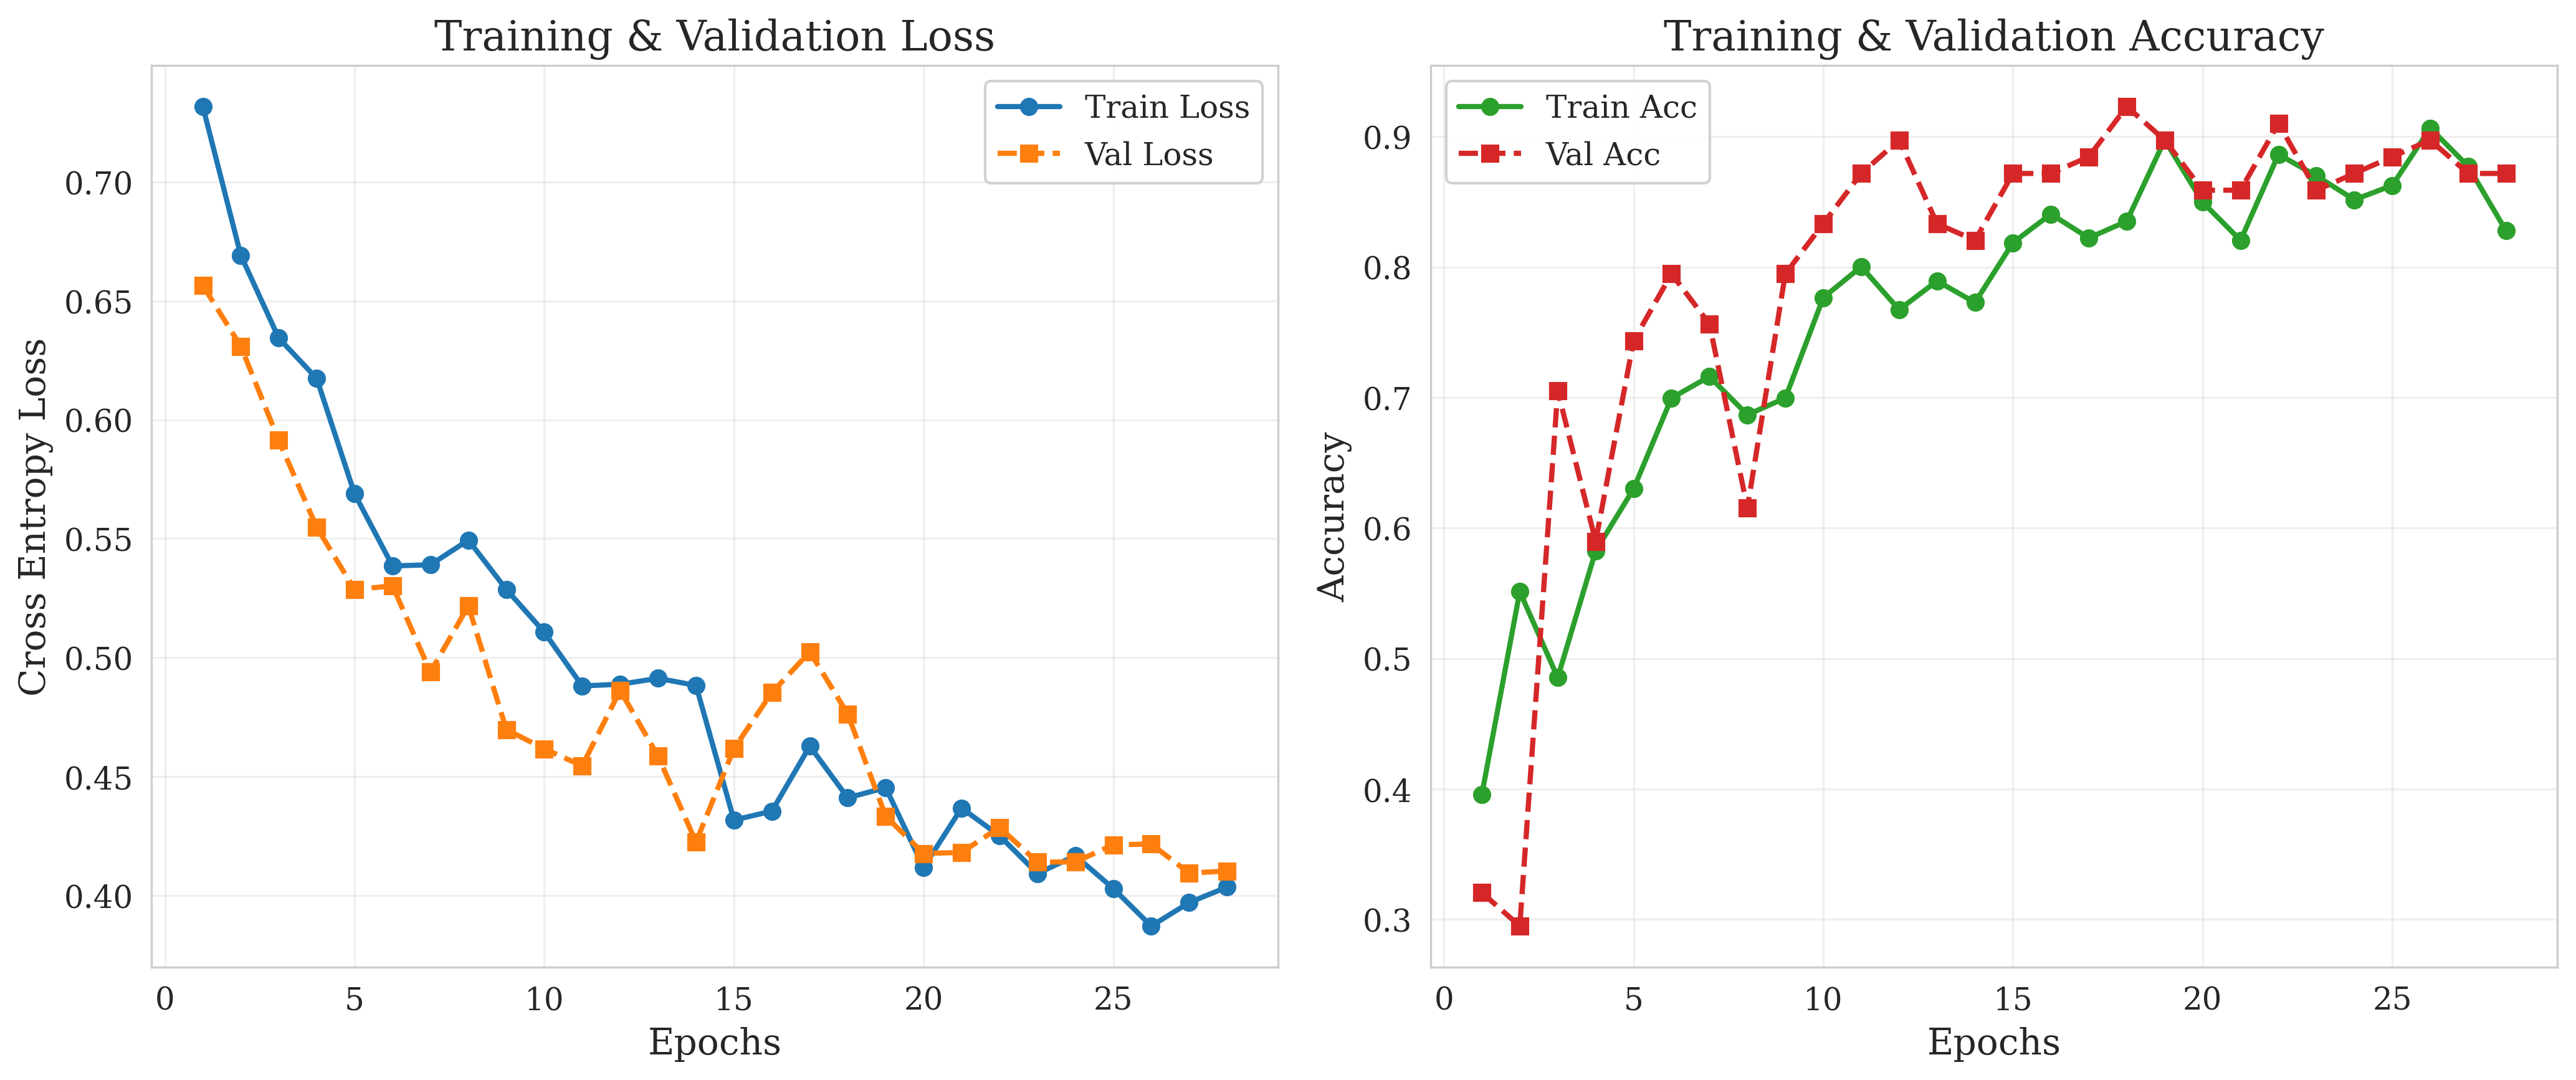

🏥 Avvio Valutazione su: Validation Set...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set
✅ Accuracy Standard:    0.8718
⚖️  Balanced Accuracy:    0.8972  (Target Paper)
📈 AUC Score:            0.9507
------------------------------
🔍 Sensitivity (Maligno): 0.9524  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8421

💾 Modello finale salvato con successo in: /content/models/TOP_model_quantum_10/TOP_best_model.pt


In [ ]:
print("\n Generazione Grafici...")
plot_results(history_quantum_10, save_dir='training_plots', model_name='model_quantum_10')

val_metrics_quantum_10 = calculate_metrics(
    model=model_quantum_10_trained,
    dataloader=val_loader,
    device= "cuda" if torch.cuda.is_available() else "cpu",
    dataset_name="Validation Set"
)

last_model_path_10 = os.path.join(local_path_models, "TOP_model_quantum_10", "TOP_best_model.pt")
os.makedirs(os.path.dirname(last_model_path_10), exist_ok=True)
torch.save(model_quantum_10_trained.state_dict(), last_model_path_10)
print(f" Modello finale salvato con successo in: {last_model_path_10}")

### VQC a 16 qubit con Data Reuploading e 1000 shots in simulazione

In [ ]:
!pip install PennyLane-Lightning

In [ ]:
dev_6_f = qml.device("lightning.qubit", wires=n_qubits_6, shots=1000)
qnode_6_f = qnode_factory(circuit_reupload_template, n_qubits_6, dev_6_f, interface="torch")

vqc_layer_6_f = qml.qnn.TorchLayer(qnode_6_f, weight_shapes_6)

/usr/local/lib/python3.12/dist-packages/pennylane/devices/device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


In [ ]:
device_6_f = "cuda" if torch.cuda.is_available() else "cpu"

file_path_6_saved = os.path.join(drive_path_models, "model_quantum_6_20260218_083223/best_model.pt")

model_6_f = get_quantum_swin_model_arg(vqc_layer_6_f, n_qubits=n_qubits_6)
model_6_saved = torch.load(file_path_6_saved, map_location=device_6_f)
if isinstance(model_6_saved, dict) and 'model_state_dict' in model_6_saved:
  print("Caricamento da Checkpoint completo...")
  weights_6_saved = model_6_saved['model_state_dict']
else:
  print("Direct weight loading...")
  weights_6_saved = model_6_saved

model_6_f.load_state_dict(weights_6_saved)
model_6_f = model_6_f.to(device_6_f)
model_6_f.eval()
metrics_shots_6_f = calculate_metrics(
    model=model_6_f,
    dataloader=val_loader,
    device=device_6_f,
    dataset_name="Validation Set (16 Qubits - 1000 Shots)"
)

Caricamento da Checkpoint completo...
🏥 Avvio Valutazione su: Validation Set (16 Qubits - 1000 Shots)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (16 Qubits - 1000 Shots)
✅ Accuracy Standard:    0.8846
⚖️  Balanced Accuracy:    0.8759  (Target Paper)
📈 AUC Score:            0.8872
------------------------------
🔍 Sensitivity (Maligno): 0.8571  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8947



### Test del miglior modello a 16 qubit con 1000 shots in simulazione

In [ ]:
import os
import torch
import pennylane as qml

device_10_f = "cuda" if torch.cuda.is_available() else "cpu"
n_qubits_10_f = 16

dev_10_f = qml.device("lightning.qubit", wires=n_qubits_10_f, shots=1000)
qnode_10_f = qnode_factory(circuit_reupload_template_stab_en, n_qubits_10_f, dev_10_f, interface="torch")

weight_shapes_10_f = {"weights": (2, n_qubits_10_f, 3)}
vqc_base_10_f = qml.qnn.TorchLayer(qnode_10_f, weight_shapes_10_f)

vqc_layer_10_scaled_f = ScaledVQC(vqc_base_10_f, num_qubits=n_qubits_10_f)

model_10_f = get_quantum_swin_model_arg(vqc_layer_10_scaled_f, n_qubits=n_qubits_10_f)

# caricamento
file_path_10_saved = os.path.join(drive_path_models, "TOP_best_model_quantum_10/TOP_best_model.pt")

model_10_saved = torch.load(file_path_10_saved, map_location=device_10_f)

if isinstance(model_10_saved, dict) and 'model_state_dict' in model_10_saved:
    print(" Caricamento da Checkpoint completo...")
    weights_10_saved = model_10_saved['model_state_dict']
else:
    print(" Direct weight loading...")
    weights_10_saved = model_10_saved

# strict=True assicura che se c'è anche un solo peso che non combacia, lancia un errore esplicito
model_10_f.load_state_dict(weights_10_saved, strict=True)
model_10_f = model_10_f.to(device_10_f)
model_10_f.eval()

# Stampa il valore dello scaler per vedere se è stato aggiornato rispetto al 5.0 iniziale
print(f" Valore Scaler Caricato: {model_10_f.head[1].scaler.mean().item():.3f}")

with LocalSeed(1000): # Mettiamo il seed originale
    metrics_shots_10_f = calculate_metrics(
        model=model_10_f,
        dataloader=val_loader,
        device=device_10_f,
        dataset_name="Validation Set (Reloaded)"
    )

/usr/local/lib/python3.12/dist-packages/pennylane/devices/device_api.py:201: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


🔧 Direct weight loading...
🔎 Valore Scaler Caricato: 4.996
🏥 Avvio Valutazione su: Validation Set (Reloaded)...


Inference:   0%|          | 0/3 [00:00<?, ?it/s]


📊 REPORT METRICHE: Validation Set (Reloaded)
✅ Accuracy Standard:    0.8846
⚖️  Balanced Accuracy:    0.9060  (Target Paper)
📈 AUC Score:            0.9507
------------------------------
🔍 Sensitivity (Maligno): 0.9524  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8596



### Miglior modello valutato sul test set con esecuzione analitica (infiniti shots)

In [ ]:
dev_10_inf = qml.device("default.qubit", wires=n_qubits_10_f)

qnode_10_inf = qnode_factory(circuit_reupload_template_stab_en, n_qubits_10_f, dev_10_inf, interface="torch")

vqc_base_10_inf = qml.qnn.TorchLayer(qnode_10_inf, weight_shapes_10_f)

vqc_layer_10_scaled_inf = ScaledVQC(vqc_base_10_inf, num_qubits=n_qubits_10_f)

model_10_inf = get_quantum_swin_model_arg(vqc_layer_10_scaled_inf, n_qubits=n_qubits_10_f)

model_10_inf.load_state_dict(weights_10_saved, strict=True)
model_10_inf = model_10_inf.to(device_10_f)
model_10_inf.eval()

with LocalSeed(1000): # Mettiamo il seed originale
    metrics_shots_10_inf = calculate_metrics(
        model=model_10_inf,
        dataloader=test_loader,
        device=device_10_f,
        dataset_name="Test Set (Shots Infiniti - Calcolo Analitico)"
    )

🏥 Avvio Valutazione su: Test Set (Shots Infiniti - Calcolo Analitico)...


Inference:   0%|          | 0/5 [00:00<?, ?it/s]


📊 REPORT METRICHE: Test Set (Shots Infiniti - Calcolo Analitico)
✅ Accuracy Standard:    0.8462
⚖️  Balanced Accuracy:    0.8496  (Target Paper)
📈 AUC Score:            0.9035
------------------------------
🔍 Sensitivity (Maligno): 0.8571  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8421



### Miglior modello valutato sul test set con 1000 shots in simulazione

In [ ]:
with LocalSeed(1000): # Mettiamo il seed originale
    metrics_shots_10_f_t = calculate_metrics(
        model=model_10_f,
        dataloader=test_loader,
        device=device_10_f,
        dataset_name="Test Set (1000 Shots - Simulazione Rumore)"
    )

🏥 Avvio Valutazione su: Test Set (1000 Shots - Simulazione Rumore)...


Inference:   0%|          | 0/5 [00:00<?, ?it/s]


📊 REPORT METRICHE: Test Set (1000 Shots - Simulazione Rumore)
✅ Accuracy Standard:    0.8397
⚖️  Balanced Accuracy:    0.8528  (Target Paper)
📈 AUC Score:            0.9091
------------------------------
🔍 Sensitivity (Maligno): 0.8810  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8246



### Test su Real Quantum Computer

In [ ]:
!pip install pennylane-qiskit qiskit-ibm-runtime

In [ ]:
import os
import torch
import pennylane as qml
from torch.utils.data import DataLoader, Subset
from qiskit_ibm_runtime import QiskitRuntimeService

n_qubits_ibm_1 = 16
# SETUP IBM QUANTUM
IBM_TOKEN = "XXXX" # Sostituire con la propria API key
BACKEND_IBM = "ibm_torino"

print(f"Connessione al computer quantistico: {BACKEND_IBM}...")

QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token=IBM_TOKEN, set_as_default=True, overwrite=True)

service = QiskitRuntimeService()

real_backend = service.backend(BACKEND_IBM)

# Sostituisco il simulatore "lightning.qubit" con il QPU reale
dev_ibm_1 = qml.device(
    "qiskit.remote",
    wires=n_qubits_ibm_1,
    backend=real_backend,
    shots=1000
)

# Creazione del QNode agganciato al computer reale
weight_shapes_ibm_1 = {"weights": (2, n_qubits_ibm_1, 3)} #valido per model_quantum_10
qnode_ibm_1 = qnode_factory(circuit_reupload_template_stab_en, n_qubits_ibm_1, dev_ibm_1, interface="torch")

vqc_base_ibm_1 = qml.qnn.TorchLayer(qnode_ibm_1, weight_shapes_ibm_1)

vqc_layer_ibm_1_scaled = ScaledVQC(vqc_base_ibm_1, num_qubits=n_qubits_ibm_1)

model_ibm_1 = get_quantum_swin_model_arg(vqc_layer_ibm_1_scaled, n_qubits=n_qubits_ibm_1)

device_ibm_1 = "cuda" if torch.cuda.is_available() else "cpu"

# CARICAMENTO DEI PESI
file_path_ibm_1_saved = os.path.join(drive_path_models, "TOP_best_model_quantum_10/TOP_best_model.pt")

model_ibm_1_saved = torch.load(file_path_ibm_1_saved, map_location=device_ibm_1)

if isinstance(model_ibm_1_saved, dict) and 'model_state_dict' in model_ibm_1_saved:
    print("Caricamento da Checkpoint completo...")
    weights_ibm_1_saved = model_ibm_1_saved['model_state_dict']
else:
    print("Direct weight loading...")
    weights_ibm_1_saved = model_ibm_1_saved

model_ibm_1.load_state_dict(weights_ibm_1_saved, strict=True)
model_ibm_1 = model_ibm_1.to(device_ibm_1)
model_ibm_1.eval()

# CREAZIONE DEL MINI-DATALOADER
# Selezioniamo solo i primi 50 campioni per non restare bloccati in coda
NUM_TEST_SAMPLES = 50
print(f"Riduzione del Test Set a {NUM_TEST_SAMPLES} campioni per limiti hardware IBM...")

subset_indices = list(range(NUM_TEST_SAMPLES))
mini_test_dataset = Subset(test_loader.dataset, subset_indices)

# Usiamo un batch_size piccolo (es. 4 o 8) per non mandare in timeout le richieste API
mini_test_loader = DataLoader(mini_test_dataset, batch_size=4, shuffle=False)

# ESECUZIONE SUL VERO HARDWARE
print(f"AVVIO INFERENZA SUL QPU REALE ({BACKEND_IBM})...")
print("ATTENZIONE: Attesa possibile. Il processo dipenderà dalle code IBM.")

with LocalSeed(1000):
  metrics_shots_ibm_1 = calculate_metrics(
      model=model_ibm_1,
      dataloader=mini_test_loader,  # Usiamo il mini dataloader
      device=device_ibm_1,
      dataset_name=f"Real Hardware Test ({BACKEND_IBM} - 1000 Shots)"
  )

Connessione al computer quantistico: ibm_torino...


qiskit_runtime_service.__init__:WARNING:2026-02-18 18:24:05,250: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-02-18 18:24:05,252: Using instance: open-instance, plan: open


Direct weight loading...
Riduzione del Test Set a 50 campioni per limiti hardware IBM...
AVVIO INFERENZA SUL QPU REALE (ibm_torino)...
ATTENZIONE: Attesa possibile. Il processo dipenderà dalle code IBM.
🏥 Avvio Valutazione su: Real Hardware Test (ibm_torino - 1000 Shots)...


Inference:   0%|          | 0/13 [00:00<?, ?it/s]


📊 REPORT METRICHE: Real Hardware Test (ibm_torino - 1000 Shots)
✅ Accuracy Standard:    0.8200
⚖️  Balanced Accuracy:    0.8229  (Target Paper)
📈 AUC Score:            0.9271
------------------------------
🔍 Sensitivity (Maligno): 0.8333  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8125



### Valutazione dello Swin Transformer classico sul test set

In [ ]:
device_c1_v = "cuda" if torch.cuda.is_available() else "cpu"

file_path_c1_v_saved = os.path.join(drive_path_models, "model_classic_1_20260211_210555/best_model.pt")
model_c1_v = get_classical_swin_model()
model_c1_v_saved = torch.load(file_path_c1_v_saved, map_location=device_c1_v)
if isinstance(model_c1_v_saved, dict) and 'model_state_dict' in model_c1_v_saved:
  print("Caricamento da Checkpoint completo...")
  weights_c1_v_saved = model_c1_v_saved['model_state_dict']
else:
  print("Direct weight loading...")
  weights_c1_v_saved = model_c1_v_saved

model_c1_v.load_state_dict(weights_c1_v_saved)
model_c1_v = model_c1_v.to(device_c1_v)
model_c1_v.eval()
metrics_c1_v = calculate_metrics(
    model=model_c1_v,
    dataloader=test_loader,
    device=device_c1_v,
    dataset_name="Test Set"
)

Caricamento da Checkpoint completo...
🏥 Avvio Valutazione su: Test Set...


Inference:   0%|          | 0/5 [00:00<?, ?it/s]


📊 REPORT METRICHE: Test Set
✅ Accuracy Standard:    0.8333
⚖️  Balanced Accuracy:    0.8258  (Target Paper)
📈 AUC Score:            0.9020
------------------------------
🔍 Sensitivity (Maligno): 0.8095  (Capacità di trovare tumori)
🛡️  Specificity (Benigno): 0.8421



###Explainability

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def extract_features_with_hooks(model, dataloader, device, is_quantum=False):
    model.eval()

    # Dizionari per salvare i tensori
    features = {'input_fc': [], 'output_16_dim': [], 'output_final': []}
    labels_list = []

    # Funzioni di Hook
    def hook_input_fc(module, inp, out):
        # Salva l'input dello strato (le features grezze dal Transformer)
        features['input_fc'].append(inp[0].detach().cpu().numpy())

    def hook_output_16_dim(module, inp, out):
        # Salva l'output a 16 dimensioni
        features['output_16_dim'].append(out.detach().cpu().numpy())

    def hook_output_final(module, inp, out):
        # Salva i logits quantistici finali
        features['output_final'].append(out.detach().cpu().numpy())

    # LOGICA DI HOOKING DIFFERENZIATA
    if not is_quantum:
        # Modello Classico
        h1 = model.head[0].register_forward_hook(hook_input_fc)
        h2 = model.head[2].register_forward_hook(hook_output_16_dim)
    else:
        # Modello Quantistico
        h1 = model.head[0].register_forward_hook(hook_input_fc)
        h2 = model.head[0].register_forward_hook(hook_output_16_dim)
        h3 = model.head[1].register_forward_hook(hook_output_final)

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            _ = model(inputs)
            labels_list.append(labels.detach().cpu().numpy())

    # Rimuovo gli hooks
    h1.remove()
    h2.remove()
    if is_quantum:
        h3.remove()

    # Concateno i risultati
    extracted = {
        'input_fc': np.concatenate(features['input_fc'], axis=0),
        'output_16_dim': np.concatenate(features['output_16_dim'], axis=0),
        'labels': np.concatenate(labels_list, axis=0).flatten()
    }
    if is_quantum:
        extracted['output_final'] = np.concatenate(features['output_final'], axis=0)

    return extracted


def plot_manifold_comparison(model_classic, model_quantum, dataloader, device):
    print("Estrazione features modello classico...")
    feat_classic = extract_features_with_hooks(model_classic, dataloader, device, is_quantum=False)

    print("Estrazione features modello quantistico...")
    feat_quantum = extract_features_with_hooks(model_quantum, dataloader, device, is_quantum=True)

    labels = feat_classic['labels'] # Le labels sono le stesse per entrambi

    # Preparo i 4 tensori da plottare
    data_to_plot = [
        ("Input of FC", feat_classic['input_fc']),
        ("Output of FC", feat_classic['output_16_dim']),
        ("Input of VQC", feat_quantum['output_16_dim']),
        ("Output of VQC", feat_quantum['output_final'])
    ]

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    fig.subplots_adjust(hspace=0.4, wspace=0.3)

    # Indice 0 (Maligno) -> lightcoral (Rosso)
    # Indice 1 (Benigno) -> mediumturquoise (Ciano)
    colors = ['lightcoral', 'mediumturquoise']

    for col_idx, (title, X) in enumerate(data_to_plot):
        # RIGA 0: PCA
        pca = PCA(n_components=2, random_state=42)
        X_pca = pca.fit_transform(X)

        ax_pca = axes[0, col_idx]
        for class_idx in [0, 1]:
            mask = (labels == class_idx)
            ax_pca.scatter(X_pca[mask, 0], X_pca[mask, 1], c=colors[class_idx], s=15, alpha=0.8)

        ax_pca.set_title(title, fontsize=14, pad=15)
        ax_pca.set_xticks([])
        ax_pca.set_yticks([])
        if col_idx == 0: ax_pca.set_ylabel("PCA", fontsize=16, labelpad=20, rotation=0, va='center')

        # RIGA 1: t-SNE
        tsne = TSNE(n_components=2, random_state=42, perplexity=30)
        X_tsne = tsne.fit_transform(X)

        ax_tsne = axes[1, col_idx]
        for class_idx in [0, 1]:
            mask = (labels == class_idx)
            ax_tsne.scatter(X_tsne[mask, 0], X_tsne[mask, 1], c=colors[class_idx], s=15, alpha=0.8)

        ax_tsne.set_xticks([])
        ax_tsne.set_yticks([])
        if col_idx == 0: ax_tsne.set_ylabel("tSNE", fontsize=16, labelpad=20, rotation=0, va='center')

    # Frecce tra i plot
    for row in range(2):
        for col in [0, 2]:
            axes[row, col].annotate('', xy=(1.15, 0.5), xycoords='axes fraction', xytext=(1.05, 0.5),
                                    arrowprops=dict(facecolor='white', edgecolor='green', width=3, headwidth=10))

    plt.suptitle("PCA and t-SNE embedding distance visualization (Classical vs 16-qubit QEST)", fontsize=18)

    # Salvataggio in PDF Vettoriale e PNG Alta Risoluzione
    plt.savefig("latent_space_visualization.pdf", bbox_inches='tight', format='pdf')
    plt.savefig("latent_space_visualization.png", bbox_inches='tight', dpi=300)
    plt.show()

In [25]:
device_10_f_xai = "cuda" if torch.cuda.is_available() else "cpu"
n_qubits_10_f_xai = 16

dev_10_f_xai = qml.device("default.qubit", wires=n_qubits_10_f_xai)
qnode_10_f_xai = qnode_factory(circuit_reupload_template_stab_en, n_qubits_10_f_xai, dev_10_f_xai, interface="torch")

weight_shapes_10_f_xai = {"weights": (2, n_qubits_10_f_xai, 3)}
vqc_base_10_f_xai = qml.qnn.TorchLayer(qnode_10_f_xai, weight_shapes_10_f_xai)

vqc_layer_10_scaled_f_xai = ScaledVQC(vqc_base_10_f_xai, num_qubits=n_qubits_10_f_xai)

model_10_f_xai = get_quantum_swin_model_arg(vqc_layer_10_scaled_f_xai, n_qubits=n_qubits_10_f_xai)

# caricamento
file_path_10_saved_xai = os.path.join(drive_path_models, "TOP_best_model_quantum_10_Copia/TOP_best_model.pt")

model_10_saved_xai = torch.load(file_path_10_saved_xai, map_location=device_10_f_xai)

if isinstance(model_10_saved_xai, dict) and 'model_state_dict' in model_10_saved_xai:
    print(" Caricamento da Checkpoint completo...")
    weights_10_saved_xai = model_10_saved_xai['model_state_dict']
else:
    print(" Direct weight loading...")
    weights_10_saved_xai = model_10_saved_xai

# strict=True assicura che se c'è anche un solo peso che non combacia, lancia un errore esplicito
model_10_f_xai.load_state_dict(weights_10_saved_xai, strict=True)
model_10_f_xai = model_10_f_xai.to(device_10_f_xai)
model_10_f_xai.eval()

 Direct weight loading...


SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=128, out_features=384, bias=True)
          (proj): Linear(in_features=128, out_features=128, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=512, out_features=128, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock

In [ ]:
model_classic_1_xai = get_classical_swin_model()
# caricamento
file_path_saved_classic_1_xai = os.path.join(drive_path_models, "model_classic_1_20260211_210555/best_model.pt")

model_saved_classic_1_xai = torch.load(file_path_saved_classic_1_xai, map_location=device_10_f_xai)

if isinstance(model_saved_classic_1_xai, dict) and 'model_state_dict' in model_saved_classic_1_xai:
    print(" Caricamento da Checkpoint completo...")
    weights_saved_classic_1_xai = model_saved_classic_1_xai['model_state_dict']
else:
    print(" Direct weight loading...")
    weights_saved_classic_1_xai = model_saved_classic_1_xai
# strict=True assicura che se c'è anche un solo peso che non combacia, lancia un errore esplicito
model_classic_1_xai.load_state_dict(weights_saved_classic_1_xai, strict=True)
model_classic_1_xai = model_classic_1_xai.to(device_10_f_xai)
model_classic_1_xai.eval()

 Caricamento da Checkpoint completo...


SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 128, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=128, out_features=384, bias=True)
          (proj): Linear(in_features=128, out_features=128, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=512, out_features=128, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock

Estrazione features modello classico...
Estrazione features modello quantistico...


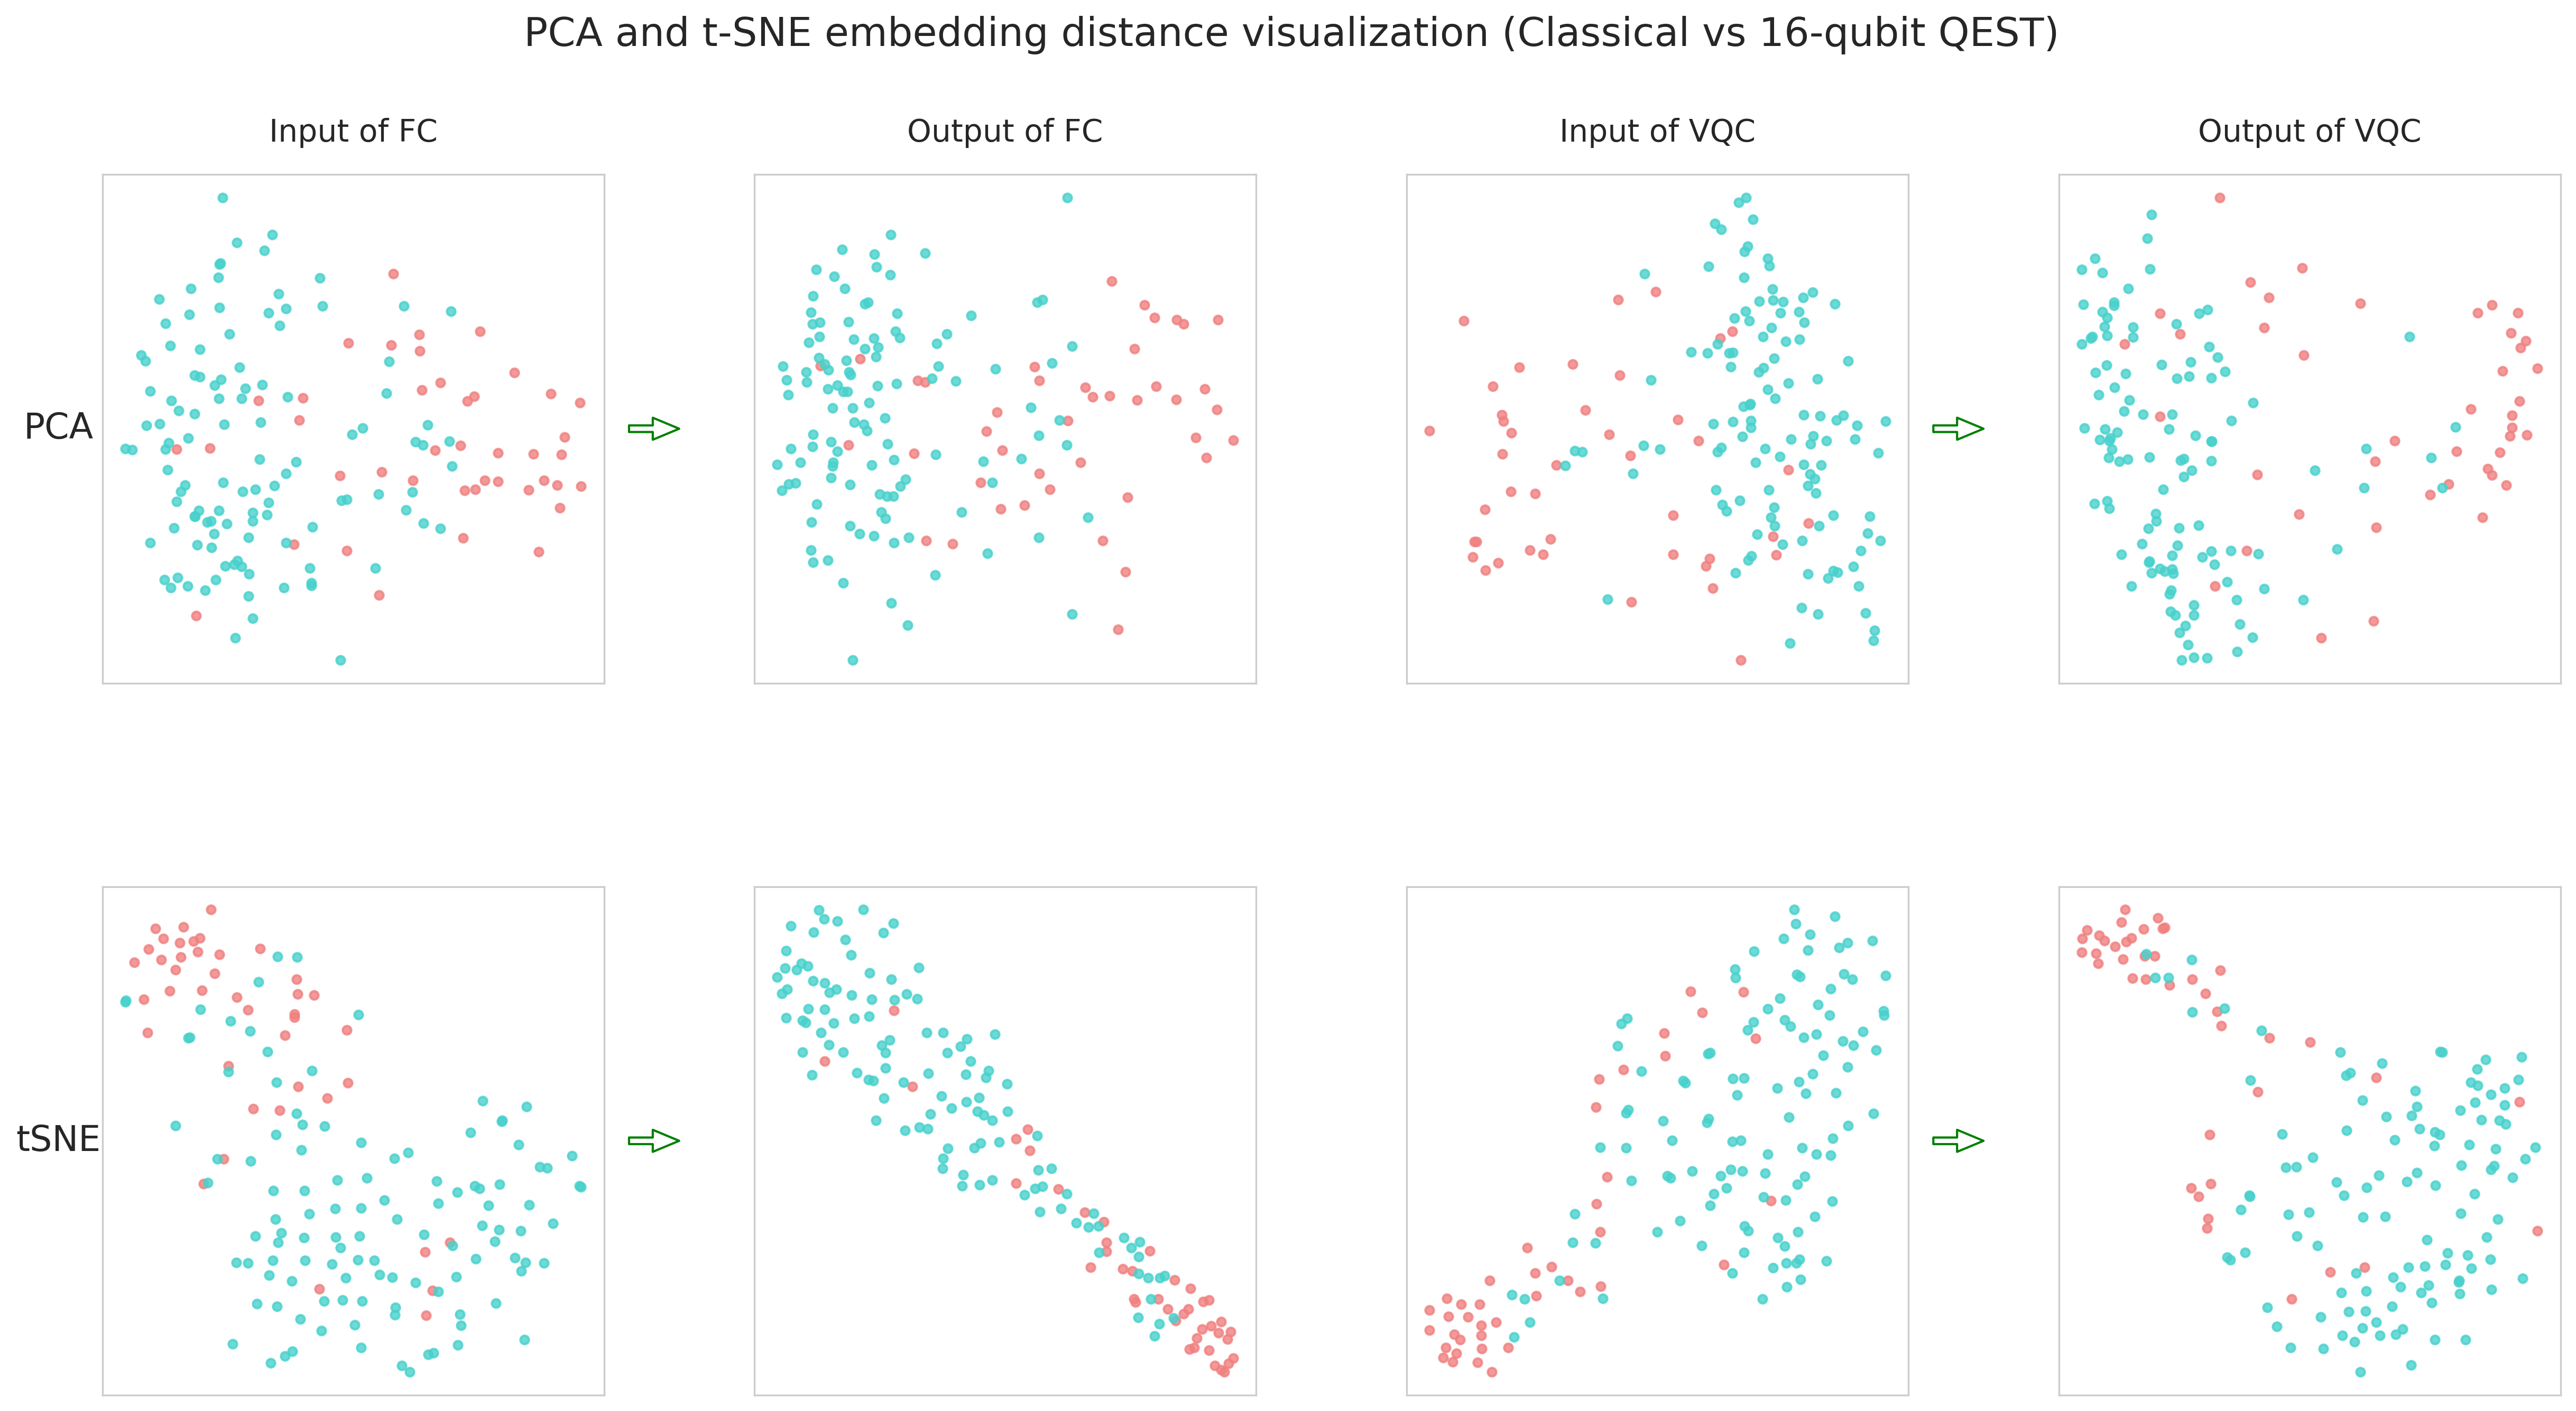

In [ ]:
plot_manifold_comparison(model_classic_1_xai, model_10_f_xai, test_loader, device_10_f_xai)

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import cv2
from scipy.ndimage import gaussian_filter

def generate_occlusion_map(model, image_tensor, target_class, device, patch_size=24, stride=8, smoothing=True):
    """
    Genera una mappa di calore usando l'Occlusion Sensitivity con opzione di smoothing.
    """
    model.eval()


    if len(image_tensor.shape) == 3:
        image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)
    _, C, H, W = image_tensor.shape

    # Calcola la probabilità base dell'immagine originale
    with torch.no_grad():
        outputs = model(image_tensor)
        base_probs = F.softmax(outputs, dim=1)
        base_prob = base_probs[0, target_class].item()

    # Creo una mappa di calore vuota
    heatmap = np.zeros((H, W), dtype=np.float32)
    # Contatore per fare la media nelle zone di sovrapposizione delle patch
    counts = np.zeros((H, W), dtype=np.float32)

    # Valore di "copertura" (grigio medio)
    mask_value = image_tensor.mean().item()

    # Faccio scorrere il quadratino (patch) sull'immagine
    for y in range(0, H - patch_size + 1, stride):
        for x in range(0, W - patch_size + 1, stride):
            # Creo una copia dell'immagine e applico la toppa
            masked_image = image_tensor.clone()
            masked_image[:, :, y:y+patch_size, x:x+patch_size] = mask_value

            # Calcolo la nuova probabilità con l'immagine "oscurata"
            with torch.no_grad():
                masked_outputs = model(masked_image)
                masked_probs = F.softmax(masked_outputs, dim=1)
                new_prob = masked_probs[0, target_class].item()

            # L'importanza di questa patch è quanto fa crollare la probabilità
            drop_in_prob = base_prob - new_prob

            # Assegno questo calo di probabilità alla zona coperta
            heatmap[y:y+patch_size, x:x+patch_size] += drop_in_prob
            counts[y:y+patch_size, x:x+patch_size] += 1.0

    # Per evitare divisioni per zero
    counts[counts == 0] = 1.0
    heatmap = heatmap / counts

    # Normalizzo la heatmap tra 0 e 1 per i colori
    heatmap = np.maximum(heatmap, 0) # Rimuovo i valori negativi
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    # Smoothing gaussiano
    if smoothing:
        # Applico un filtro gaussiano per sfumare i bordi squadrati
        heatmap = gaussian_filter(heatmap, sigma=3.0)
        # Ri-normalizzo dopo il filtro
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

    return heatmap

def plot_xai_comparison(model_classic, model_quantum, dataloader, device, patch_size=24, stride=8):
    """
    Trova un'immagine Maligna (0) e una Benigna (1), calcola le Occlusion Maps
    per entrambi i modelli e genera un plot
    """
    print("Ricerca di immagini campione nel dataloader...")
    img_malignant, img_benign = None, None
    label_malignant, label_benign = 0, 1 # 0=Maligno, 1=Benigno

    for inputs, labels in dataloader:
        for i in range(inputs.size(0)):
            if labels[i].item() == label_malignant and img_malignant is None:
                img_malignant = inputs[i].unsqueeze(0)
            elif labels[i].item() == label_benign and img_benign is None:
                img_benign = inputs[i].unsqueeze(0)
        if img_malignant is not None and img_benign is not None:
            break

    images = [
        ("Malignant Case (Target: 0)", img_malignant, label_malignant),
        ("Benign Case (Target: 1)", img_benign, label_benign)
    ]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.subplots_adjust(hspace=0.3, wspace=0.1)

    for row_idx, (title, img_tensor, target_class) in enumerate(images):
        print(f"Generazione mappe per: {title}...")

        # Immagine Originale (Convertita per Matplotlib)
        img_np = img_tensor.squeeze().cpu().numpy()
        if len(img_np.shape) == 3:
            img_np = np.transpose(img_np, (1, 2, 0))
            # Denormalizzazione basica per la visualizzazione
            img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

        axes[row_idx, 0].imshow(img_np, cmap='gray' if len(img_np.shape)==2 else None)
        axes[row_idx, 0].set_title(f"Input\n{title}", fontsize=14)
        axes[row_idx, 0].axis('off')

        # Generazione Mappa Modello Classico
        print(" -> Calcolo Occlusion Map (Classico)...")
        # Uso smoothing=True per avere mappe sfumate
        hm_classic = generate_occlusion_map(model_classic, img_tensor, target_class, device, patch_size, stride, smoothing=True)

        axes[row_idx, 1].imshow(img_np, cmap='gray' if len(img_np.shape)==2 else None)
        # Uso l'interpolazione 'bicubic' per un rendering a schermo più morbido
        im1 = axes[row_idx, 1].imshow(hm_classic, cmap='jet', alpha=0.5, interpolation='bicubic')
        axes[row_idx, 1].set_title("Classical Swin-T\nOcclusion Sensitivity", fontsize=14)
        axes[row_idx, 1].axis('off')

        # Generazione Mappa Modello Quantistico
        print(" -> Calcolo Occlusion Map (Quantistico). Questo richiederà un po' di tempo...")
        hm_quantum = generate_occlusion_map(model_quantum, img_tensor, target_class, device, patch_size, stride, smoothing=True)

        axes[row_idx, 2].imshow(img_np, cmap='gray' if len(img_np.shape)==2 else None)
        im2 = axes[row_idx, 2].imshow(hm_quantum, cmap='jet', alpha=0.5, interpolation='bicubic')
        axes[row_idx, 2].set_title("16-Qubit QEST\nOcclusion Sensitivity", fontsize=14)
        axes[row_idx, 2].axis('off')

    plt.suptitle("Explainable AI (XAI) Comparison: Classical vs Quantum Hybrid Model", fontsize=18, y=0.95)

    print("Salvataggio dei plot in alta risoluzione (PDF e PNG)...")
    plt.savefig("xai_occlusion_comparison.pdf", bbox_inches='tight', format='pdf')
    plt.savefig("xai_occlusion_comparison.png", bbox_inches='tight', dpi=300)
    plt.show()
    print("Plot completato e salvato!")

Ricerca di immagini campione nel dataloader...
Generazione mappe per: Malignant Case (Target: 0)...
 -> Calcolo Occlusion Map (Classico)...
 -> Calcolo Occlusion Map (Quantistico). Questo richiederà un po' di tempo...
Generazione mappe per: Benign Case (Target: 1)...
 -> Calcolo Occlusion Map (Classico)...
 -> Calcolo Occlusion Map (Quantistico). Questo richiederà un po' di tempo...
Salvataggio dei plot in alta risoluzione (PDF e PNG)...


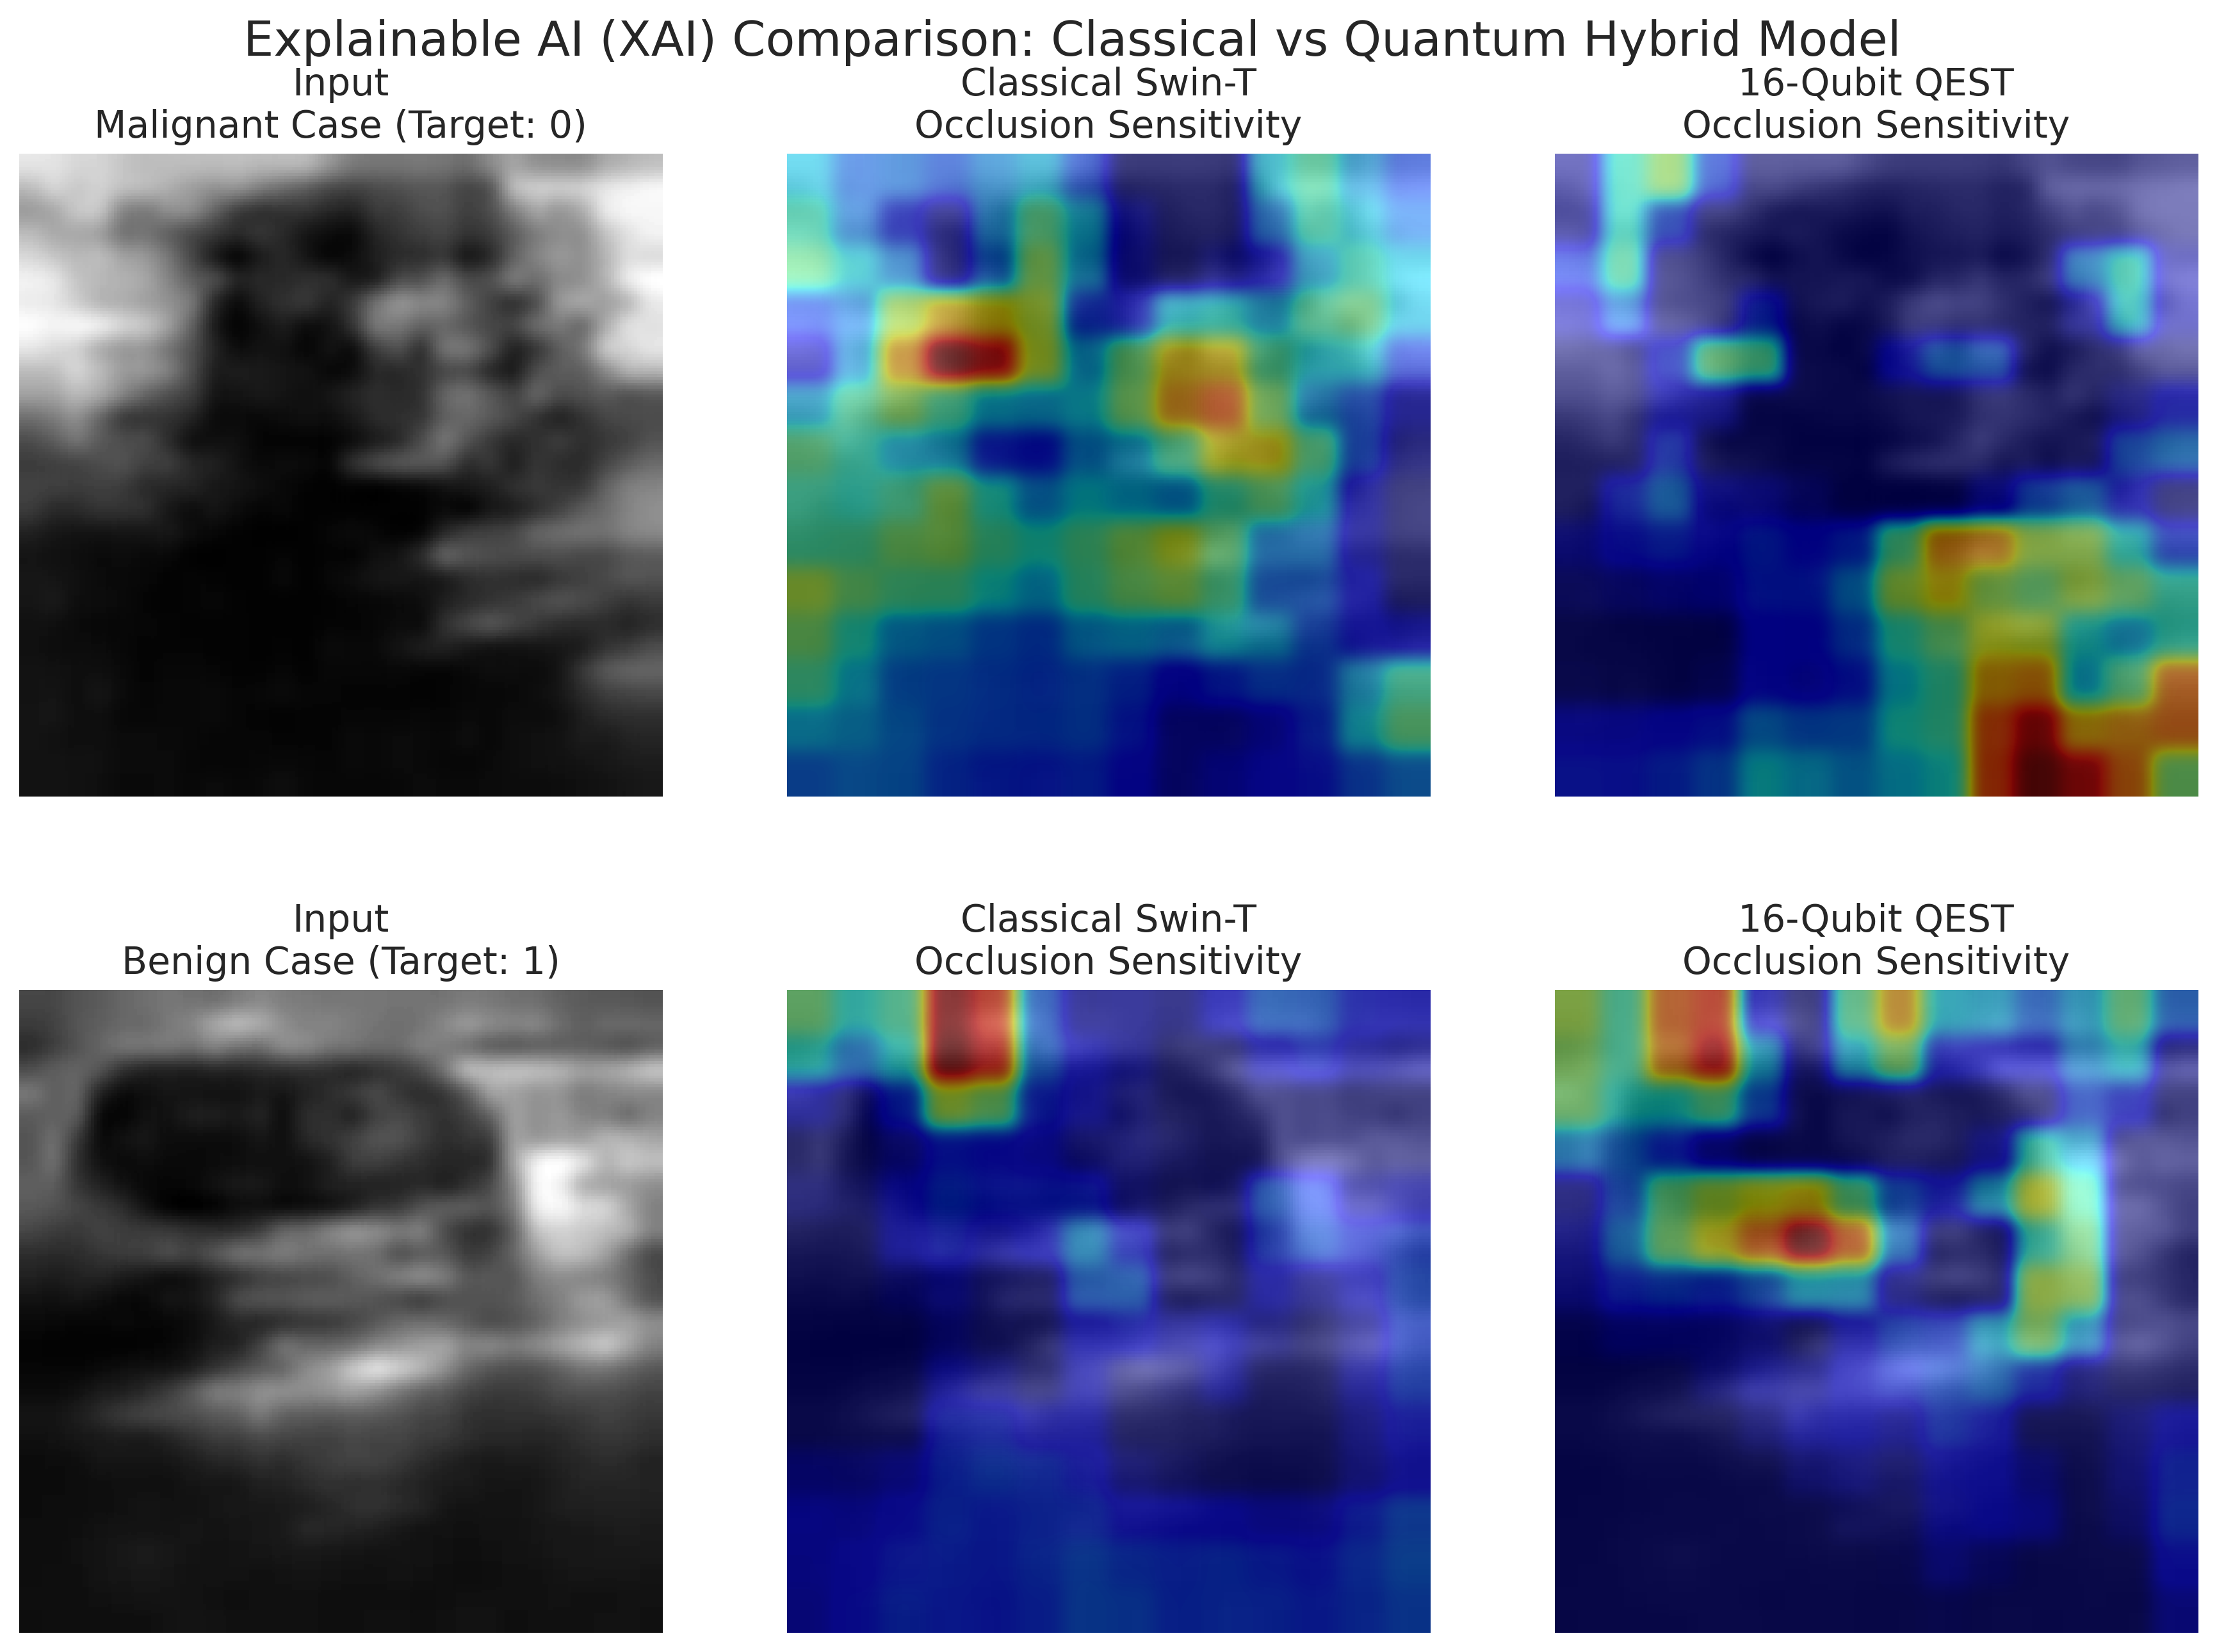

Plot completato e salvato!


In [ ]:
plot_xai_comparison(model_classic_1_xai, model_10_f_xai, test_loader, device_10_f_xai, patch_size=32, stride=16)

## Plot degli ansatz

In [10]:
n_qubits_ans = 4
n_layers_ans = 1
dummy_inputs_ans = torch.rand(n_qubits_ans)
dummy_weights_ans = torch.rand((n_layers_ans, n_qubits_ans, 3))
dummy_args_ans = (dummy_inputs_ans, dummy_weights_ans)
dev_ans = qml.device("default.qubit", wires=n_qubits_ans)

### Ansatz di circuit

In [12]:
qnode_a1 = qml.QNode(circuit, dev_ans)
export_professional_circuit(
    qnode=qnode_a1,             # Passiamo il QNode esatto che hai definito nel tuo setup
    dummy_args=dummy_args_ans,            # I dati finti appena creati
    filename="circuit_ansatz_4_qubits", # Il nome che avranno i file scaricati
    style="pennylane",                # Stile a colori perfetto per presentazioni
    dpi=500                           # Altissima risoluzione per le slide
)


Generazione del circuito 'circuit_ansatz_4_qubits' in corso...
Download di circuit_ansatz_4_qubits.pdf e circuit_ansatz_4_qubits.png...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fatto! Immagini pronte per LaTeX.


### Ansatz di circuit_strong

In [11]:
qnode_a2 = qml.QNode(circuit_strong, dev_ans)
export_professional_circuit(
    qnode=qnode_a2,             # Passiamo il QNode esatto che hai definito nel tuo setup
    dummy_args=dummy_args_ans,            # I dati finti appena creati
    filename="circuit_strong_ansatz_4_qubits", # Il nome che avranno i file scaricati
    style="pennylane",                # Stile a colori perfetto per presentazioni
    dpi=500                           # Altissima risoluzione per le slide
)

Generazione del circuito 'circuit_strong_ansatz_4_qubits' in corso...
Download di circuit_strong_ansatz_4_qubits.pdf e circuit_strong_ansatz_4_qubits.png...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fatto! Immagini pronte per LaTeX.


### model_quantum_10

In [26]:
# --- GENERAZIONE DELL'IMMAGINE PER LE SLIDE ---

# 1. Creiamo i dati finti (Dummy Data) per il disegno
# Usiamo i 16 qubit del tuo modello
n_qubits_vis = 16

# Impostiamo 1 solo layer per l'ansatz visivo, così l'immagine non diventa chilometrica
n_layers_vis = 1

# Generiamo tensori casuali con le dimensioni corrette
dummy_inputs = torch.rand(n_qubits_vis)
dummy_weights = torch.rand((n_layers_vis, n_qubits_vis, 3))

# 2. Prepariamo la tupla degli argomenti finti
# Nelle tue versioni precedenti, il qnode si aspettava (inputs, weights)
dummy_args = (dummy_inputs, dummy_weights)

# NOTA DI SICUREZZA: Se la tua funzione "qnode_factory" non nasconde il parametro n_qubits
# e ricevi un errore del tipo "missing 1 required positional argument",
# commenta la riga sopra e de-commenta questa qui sotto:
# dummy_args = (dummy_inputs, dummy_weights, n_qubits_vis)

# 3. Lanciamo l'esportazione professionale
export_professional_circuit(
    qnode=qnode_10_f_xai,             # Passiamo il QNode esatto che hai definito nel tuo setup
    dummy_args=dummy_args,            # I dati finti appena creati
    filename="model_quantum_10_ansatz_16_qubits", # Il nome che avranno i file scaricati
    style="pennylane",                # Stile a colori perfetto per presentazioni
    dpi=500                           # Altissima risoluzione per le slide
)

Generazione del circuito 'model_quantum_10_ansatz_16_qubits' in corso...
Download di model_quantum_10_ansatz_16_qubits.pdf e model_quantum_10_ansatz_16_qubits.png...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fatto! Immagini pronte per LaTeX.


In [ ]:
!pip install graphviz

In [ ]:
import graphviz
import os

output_dir_graph = '/content/graph_eda_results'
os.makedirs(output_dir_graph, exist_ok=True)

def generate_compact_swin_diagram():
    dot = graphviz.Digraph(comment='Swin Transformer Compact', format='pdf')

    # splines='ortho' crea le frecce spezzate ad angolo retto come nel paper
    dot.attr(rankdir='LR', splines='ortho', nodesep='0.3', ranksep='0.4')
    dot.attr('node', fontname='Helvetica-Bold', fontsize='12')
    dot.attr('edge', penwidth='2', color='#888888', arrowsize='0.8')

    # --- COLORI ESATTI DEL PAPER ---
    c_swmsa = '#00B050'       # Verde intenso
    c_linear_stage = '#0070C0' # Blu intenso
    c_head = '#ED7D31'        # Arancione
    c_pool = '#00A2E8'        # Ciano
    c_bg = '#F8F9FA'          # Grigio chiarissimo

    # --- 1. INPUT ---
    dot.node('input', 'Input Image\n224 x 224 x 1', shape='box', style='filled,rounded', fillcolor=c_bg, penwidth='2', color='#555555')

    # --- 2. SWIN TRANSFORMER (ST) BOUNDING BOX ---
    with dot.subgraph(name='cluster_st') as st:
        st.attr(color='#00A2E8', penwidth='2', label='ST', fontname='Helvetica-Bold', fontsize='14', style='rounded', margin='15')

        # Patch Partition (Scatola verticale alta)
        st.node('patch', 'Patch\nPartition', shape='box', style='filled', fillcolor=c_linear_stage, fontcolor='white', height='3', width='0.6')

        for i in range(1, 5):
            stage_html = f"""<
            <TABLE BORDER="1" COLOR="#999999" CELLBORDER="0" CELLSPACING="2" CELLPADDING="6" STYLE="ROUNDED" BGCOLOR="white">
              <TR><TD BGCOLOR="{c_swmsa}" PORT="top" STYLE="ROUNDED"><FONT COLOR="white">Block<BR/>(SW-MSA)</FONT></TD></TR>
              <TR><TD BGCOLOR="{c_swmsa}" STYLE="ROUNDED"><FONT COLOR="white">Block<BR/>(SW-MSA)</FONT></TD></TR>
              <TR><TD BGCOLOR="{c_linear_stage}" PORT="bot" STYLE="ROUNDED"><FONT COLOR="white">Linear<BR/>Embedding</FONT></TD></TR>
              <TR><TD BORDER="0" PADDING="2"><FONT COLOR="black" POINT-SIZE="10">Stage {i}</FONT></TD></TR>
            </TABLE>>"""
            st.node(f'stage{i}', stage_html, shape='plaintext')

        # === TRUCCO MAGICO 1: SPINA DORSALE INVISIBILE ===
        # Questo forza Graphviz ad allineare tutti i centri perfettamente in orizzontale!
        st.edge('patch', 'stage1', style='invis')
        st.edge('stage1', 'stage2', style='invis')
        st.edge('stage2', 'stage3', style='invis')
        st.edge('stage3', 'stage4', style='invis')

        # === TRUCCO MAGICO 2: FRECCE A SERPENTE "LIBERE" ===
        # constraint='false' disegna le frecce senza alterare l'allineamento dei blocchi
        st.edge('patch:e', 'stage1:bot:w', constraint='false')
        st.edge('stage1:top:e', 'stage2:bot:w', constraint='false')
        st.edge('stage2:top:e', 'stage3:bot:w', constraint='false')
        st.edge('stage3:top:e', 'stage4:bot:w', constraint='false')

    dot.edge('input', 'patch')

    # --- 3. CLASSIFICATION HEAD (Compattata con Rettangoli Verticali) ---
    dot.node('norm', 'Norm', shape='plaintext', fontname='Helvetica-Bold')
    dot.node('pool', 'AvgPool', shape='diamond', style='filled', fillcolor=c_pool, fontcolor='white', width='0.8', height='0.8')

    # Creiamo rettangoli stretti e alti (height > width) per schiacciare la parte finale
    dot.node('fc1', 'Linear\nLayer\n(1024)', shape='box', style='filled,rounded', fillcolor=c_head, fontcolor='white', height='1.5', width='0.6')
    dot.node('relu', 'ReLU', shape='circle', style='filled', fillcolor='#FFC000', fontcolor='black', fixedsize='true', width='0.6', fontsize='10')
    dot.node('fc2', 'Linear\nLayer\n(16)', shape='box', style='filled,rounded', fillcolor=c_head, fontcolor='white', height='1.2', width='0.6')
    dot.node('fc3', 'Class.\n(2)', shape='box', style='filled,rounded', fillcolor=c_head, fontcolor='white', height='0.8', width='0.6')
    dot.node('softmax', 'Softmax', shape='ellipse', style='filled', fillcolor=c_pool, fontcolor='white')

    # Allineiamo la testa allo Stage 4 con un asse invisibile
    dot.edge('stage4', 'norm', style='invis')

    # Connessioni finali (La freccia dal paper esce dall'alto dello stage 4)
    dot.edge('stage4:top:e', 'norm:w', constraint='false')
    dot.edge('norm:e', 'pool:w')
    dot.edge('pool:e', 'fc1:w')
    dot.edge('fc1:e', 'relu:w')
    dot.edge('relu:e', 'fc2:w')
    dot.edge('fc2:e', 'fc3:w')
    dot.edge('fc3:e', 'softmax:w')

    output_path = os.path.join(output_dir_graph, 'swin_b_paper_style')
    dot.render(output_path, cleanup=True)
    print(f"Diagramma STILE PAPER salvato in: {output_path}.pdf")

# Esecuzione
generate_compact_swin_diagram()

in label of node stage1
in label of node stage2
in label of node stage3
in label of node stage4


Diagramma STILE PAPER salvato in: /content/graph_eda_results/swin_b_paper_style.pdf


Per svolgere il progetto sono stati usati LLM, nello specifico ChatGPT e Gemini. In ogni caso, il codice implementato è stato sviluppato dal sottoscritto in modo originale, usando l'AI solo per aiuto con librerie di plot o questioni minori.